# Ablations of M6

M6 retrained without one ingredient at a time, on the same folds and seeds: the stimulus information, the turn and
kinematic history, the clocks, the x3 turn weight and the per-fish latent.

<a id="contents"></a>
**Contents**

- [Training and evaluation](#training-and-evaluation)
- [Every ablation at both seeds (Table tab:abl-all)](#every-ablation-at-both-seeds-table-tab-abl-all)
- [Individuality of every ablation (Table tab:abl-indiv)](#individuality-of-every-ablation-table-tab-abl-in)
- [Distance profiles of the stimulus ablations (Figure fig:abl-profiles)](#distance-profiles-of-the-stimulus-ablations-figu)
- [Every model's measurements on held-out fish](#every-model-s-measurements-on-held-out-fish)

In [1]:
import pandas as pd
from twin import registry, tables, training, unit_eval
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

In [2]:
MODELS = tables.ABLATIONS

<a id="training-and-evaluation"></a>
## Training and evaluation

`TRAIN = True` retrains every unit below (about 40 CPU-hours), `EVALUATE = True` re-runs every evaluation (about 15 min per
unit); both write to `output/`. Evaluation is deterministic, so re-evaluating reproduces the saved numbers exactly.

[↑ back to contents](#contents)

In [3]:
TRAIN, EVALUATE = False, False
UNITS = [(name, seed) for name in MODELS + ['M6-pos'] for seed in (0, 101) if (name, seed) in registry.BY_NAME]
for name, seed in UNITS:
    if TRAIN:
        training.make_unit(name, seed)
    if EVALUATE:
        unit_eval.evaluate(registry.BY_NAME[(name, seed)])
pd.DataFrame([dict(model=n, seed=s, key=registry.BY_NAME[(n, s)], made=registry.unit(n, s)["make"],
                   arm=registry.arm(registry.unit(n, s))) for n, s in UNITS]).set_index(["model", "seed"])

key   made                               arm
model          seed                                              
M6             0     26e  train      S4x_adt_z2_cdt_tr_rc_al_w3ft
               101   30d  train      S4x_adt_z2_cdt_tr_rc_al_w3ft
M6-stim        0     29e  train   Snull_adt_z2_cdt_tr_rc_w3ft_nck
               101   33u  train   Snull_adt_z2_cdt_tr_rc_w3ft_nck
M6-count       0     29c  train    S4xnn_adt_z2_cdt_tr_rc_al_w3ft
               101   33s  train    S4xnn_adt_z2_cdt_tr_rc_al_w3ft
M6-range       0     33c  train       S4xnr_adt_z2_cdt_tr_rc_w3ft
               101   33d  train       S4xnr_adt_z2_cdt_tr_rc_w3ft
M6-motion      0     29d  train       S4xnm_adt_z2_cdt_tr_rc_w3ft
               101   33t  train       S4xnm_adt_z2_cdt_tr_rc_w3ft
M6-turn4       0     33e  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h4
               101   33f  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h4
M6-turn3       0     49c  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h3
               101   49d  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h3
M6-turn1       0     33g  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h1
               101   33h  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h1
M6-turn0       0     33i  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h0
               101   33j  train   S4x_adt_z2_cdt_tr_rc_al_w3ft_h0
M6-kin5        0     44c  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5
               101   44d  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5
M6-kin4        0     44a  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4
               101   44b  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4
M6-kin2        0     49a  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2
               101   49b  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2
M6-kin1        0     33k  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1
               101   33l  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1
M6-kin0        0     33m  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0
               101   33n  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0
M6-block clock 0     33o  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_nck
               101   33p  train  S4x_adt_z2_cdt_tr_rc_al_w3ft_nck
M6-run clock   0     35a  train         S4x_adt_z2_cdt_tr_al_w3ft
               101   35b  train         S4x_adt_z2_cdt_tr_al_w3ft
M6-x3          0     35g  train           S4x_adt_z2_cdt_tr_rc_al
               101   35h  train           S4x_adt_z2_cdt_tr_rc_al
M6-z           0     45a  train         S4x_adt_cdt_tr_rc_al_w3ft
               101   45b  train         S4x_adt_cdt_tr_rc_al_w3ft
M6-pos         0     33a  train       Scond_adt_z2_cdt_tr_rc_w3ft
               101   33b  train       Scond_adt_z2_cdt_tr_rc_w3ft

<a id="every-ablation-at-both-seeds-table-tab-abl-all"></a>
## Every ablation at both seeds (Table tab:abl-all)

[↑ back to contents](#contents)

In [4]:
tables.profile_table(MODELS, half_up=False)

AUC match AUC std AUC no-rad dip (mm) latency (s) grading (mm) plateau 2-8 (mm) plateau 1 (mm) error moving error static
M6             s0       0.671   0.679      0.599     3.77        10.5         4.76            18.14          22.07         0.90         0.80
               s101     0.645   0.647      0.575     3.07         9.5         4.07            17.64          21.23         1.00         1.06
M6-stim        s0       0.785   0.797      0.743     0.00         1.0         0.87            32.02          32.82         9.05         0.78
               s101     0.757   0.774      0.685     0.00         1.0         0.59            31.37          32.38         8.66         0.86
M6-count       s0       0.679   0.698      0.597     2.29         9.0         2.58            18.13          20.12         1.16         0.80
               s101     0.694   0.710      0.593     2.77         9.5         2.66            18.98          20.53         1.39         0.76
M6-range       s0       0.676   0.710      0.590     2.61        12.0         4.72            17.89          21.46         1.06         1.33
               s101     0.688   0.670      0.596     2.98         9.5         4.89            18.62          22.49         1.22         1.15
M6-motion      s0       0.706   0.712      0.642     1.20         6.5         4.60            21.11          24.76         2.66         4.99
               s101     0.715   0.703      0.639     1.29         5.5         5.04            21.05          24.25         2.55         5.19
M6-turn4       s0       0.717   0.734      0.651     2.94         8.5         6.30            18.22          23.22         1.04         1.06
               s101     0.675   0.650      0.597     2.82         9.5         4.38            18.40          22.18         0.99         1.20
M6-turn3       s0       0.682   0.683      0.614     4.00        13.5         5.43            17.03          21.06         0.76         1.38
               s101     0.686   0.665      0.621     3.18         9.5         5.19            18.09          22.05         1.11         0.94
M6-turn1       s0       0.620   0.675      0.545     3.09         9.0         5.23            18.02          21.69         1.01         0.87
               s101     0.680   0.668      0.605     3.47         9.0         5.52            18.11          22.74         0.99         1.10
M6-turn0       s0       0.675   0.699      0.630     3.21        11.5         5.83            17.79          22.94         1.08         0.92
               s101     0.695   0.695      0.648     2.80         9.0         4.36            18.19          21.79         1.16         1.24
M6-kin5        s0       0.671   0.688      0.575     3.19        12.0         4.71            17.63          21.29         0.95         1.29
               s101     0.640   0.647      0.555     3.36        13.0         4.76            17.47          21.28         0.93         1.28
M6-kin4        s0       0.698   0.694      0.639     2.98        11.5         3.83            17.63          20.60         1.01         1.15
               s101     0.656   0.670      0.591     3.18        12.0         5.95            17.32          22.35         0.96         1.23
M6-kin2        s0       0.719   0.721      0.628     3.04        12.0         4.11            17.82          21.65         1.08         1.18
               s101     0.658   0.622      0.586     3.32        12.5         6.00            17.80          22.07         0.96         1.04
M6-kin1        s0       0.715   0.742      0.640     3.27        10.5         5.31            18.67          22.63         1.22         0.98
               s101     0.660   0.644      0.594     2.92        10.0         5.21            18.16          22.22         1.04         1.10
M6-kin0        s0       0.800   0.806      0.740     3.09        10.0         4.89            18.61          22.42         1.14         0.89
               s101     0.773   0.767      0.706     3.76         9.5   

<a id="individuality-of-every-ablation-table-tab-abl-in"></a>
## Individuality of every ablation (Table tab:abl-indiv)

[↑ back to contents](#contents)

In [5]:
tables.individuality_table(MODELS)

between turn between disp. between interval between radial within turn within disp. within interval within radial
M6             s0           0.71          1.03             1.33           0.38        0.95         0.71            0.77          0.93
               s101         0.83          1.16             1.15           0.38        1.07         0.82            0.75          0.90
M6-stim        s0           0.64          1.09             1.50           0.40        1.00         0.72            0.77          0.90
               s101         0.90          1.24             1.18           0.35        0.96         0.77            0.72          0.88
M6-count       s0           0.68          1.09             1.80           0.38        1.10         0.72            0.82          0.94
               s101         0.61          0.93             1.13           0.36        1.05         0.80            0.76          0.89
M6-range       s0           0.79          1.79             1.38           0.66        1.01         0.76            0.78          0.88
               s101         0.72          1.09             1.37           0.32        1.01         0.74            0.73          0.89
M6-motion      s0           0.68          1.00             1.36           0.38        1.03         0.72            0.74          0.92
               s101         0.68          1.02             1.44           0.35        1.03         0.73            0.80          0.94
M6-turn4       s0           0.83          1.08             1.31           0.43        0.97         0.73            0.77          0.90
               s101         0.57          0.88             1.14           0.38        0.96         0.74            0.77          0.90
M6-turn3       s0           0.54          1.05             1.73           0.42        0.97         0.69            0.83          0.90
               s101         0.75          1.13             1.71           0.43        0.94         0.74            0.82          0.90
M6-turn1       s0           0.59          1.59             1.39           0.62        0.91         0.75            0.78          0.86
               s101         0.77          1.07             1.36           0.31        0.89         0.75            0.74          0.87
M6-turn0       s0           0.52          1.08             1.40           0.38        0.84         0.71            0.76          0.90
               s101         0.62          0.92             1.35           0.30        0.82         0.72            0.80          0.91
M6-kin5        s0           0.74          1.24             1.08           0.52        1.02         0.84            0.80          0.92
               s101         0.82          1.37             1.40           0.41        1.00         0.84            0.82          0.92
M6-kin4        s0           0.63          0.83             1.53           0.34        1.02         0.90            0.84          0.94
               s101         0.84          1.17             1.70           0.43        1.03         0.77            0.83          0.93
M6-kin2        s0           0.52          0.92             1.52           0.41        1.05         0.77            0.72          0.91
               s101         0.87          1.43             1.45           0.52        1.05         0.62            0.74          0.92
M6-kin1        s0           0.75          1.07             1.34           0.43        1.02         0.64            0.66          0.88
               s101         0.59          0.93             1.30           0.38        1.06         0.64            0.66          0.87
M6-kin0        s0           0.54          1.45             1.42           0.52        1.03         0.44            0.55          0.85
               s101         0.61          1.08             1.46           0.32        1.03         0.46            0.57          0.84
M6-block clock s0           0.76          1.41             1.34           0.40        1.10         0.79            0.79          0.90


<a id="distance-profiles-of-the-stimulus-ablations-figu"></a>
## Distance profiles of the stimulus ablations (Figure fig:abl-profiles)

[↑ back to contents](#contents)

check passed: 12 units reproduce their archived matched metrics and attraction


  M6 s0 (26e): bands done


  M6 s101 (30d): bands done


  M6−stim s0 (29e): bands done


  M6−stim s101 (33u): bands done


...

  M6−range s101 (33d): bands done


  M6−motion s0 (29d): bands done


  M6−motion s101 (33t): bands done


model / real band width (15 fish each, bouts thinned):
unit    M6 s0  M6 s101  M6−count s0  M6−count s101  M6−motion s0  M6−motion s101  M6−pos s0  M6−pos s101  M6−range s0  M6−range s101  M6−stim s0  M6−stim s101
cond                                                                                                                                                          
d1s3.5   0.90     0.80         0.85           0.90          0.91            0.89       0.97         0.92         0.83           0.88        0.99          0.98
d2s3.5   0.86     0.97         0.93           0.98          1.08            1.00       1.12         1.20         0.99           0.93        1.21          1.10
d4s3.5   0.61     0.65         0.66           0.72          0.77            0.72       0.78         0.80         0.65           0.61        0.78          0.78
d6s3.5   0.71     0.71         0.80           0.79          0.95            0.90       0.93         0.85         0.76           0.69        0.93      

  wrote figures/out/fig_ablation_profiles.pdf


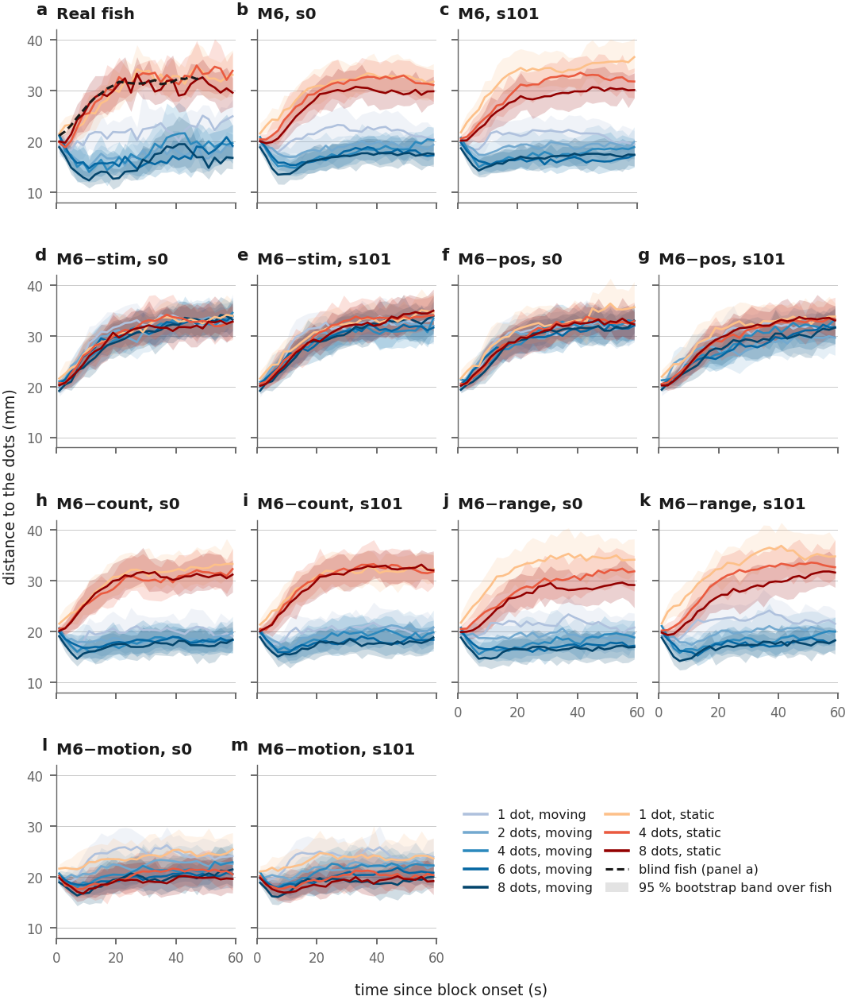

In [6]:
from figures import fig_ablation_profiles
fig_ablation_profiles.main()

<a id="every-model-s-measurements-on-held-out-fish"></a>
## Every model's measurements on held-out fish

The saved outputs of `unit_eval.evaluate`, the nine measurements of `unit_eval.CELLS` per unit; a unit with no saved evaluation is evaluated first.

[↑ back to contents](#contents)

### M6-stim, seed 0


== held-out likelihood per head (bits per bout)
turn             7.699
displacement     4.502
interval         1.213
joint           13.414

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['Snull_adt_z2_cdt_tr_rc_w3ft_nck'] -> writing panelB_model1_rej_Snull_adt_z2_cdt_tr_rc_w3ft_nck.csv / c2st_model1_rej_Snull_adt_z2_cdt_tr_rc_w3ft_nck.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_Snull_adt_z2_cdt_tr_rc_w3ft_nck.csv  (15 rows) in 500s

Metric B, mean over held-out fish (lower = closer to real):
arm                     Snull_adt_z2_cdt_tr_rc_w3ft_nck_rej
abs_dtheta_w1                                        7.9606
symbol_js                                            0.0098
dt_

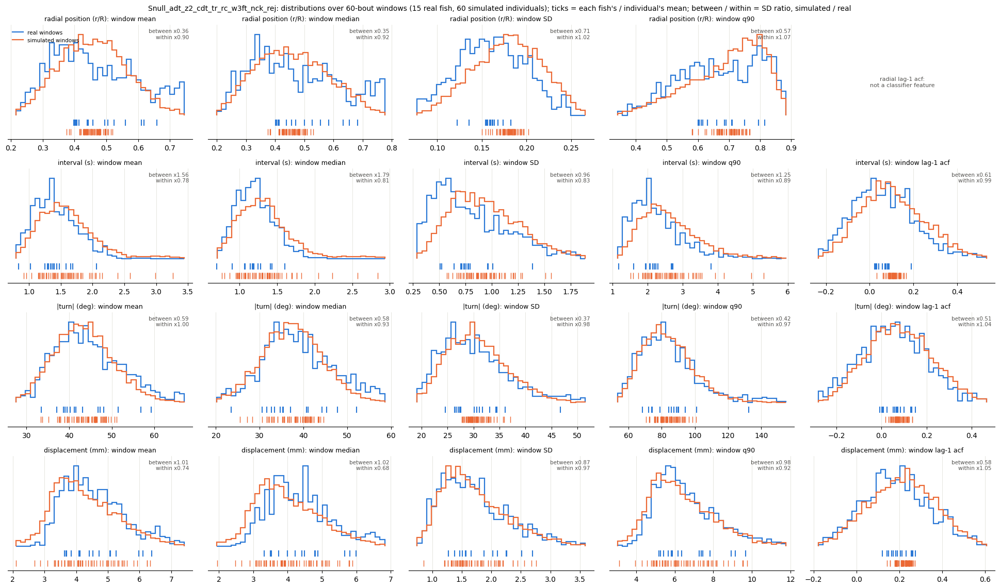


== distance to the dots across the block
  Snull_adt_z2_cdt_tr_rc_w3ft_nck_fold4.pt: 3 rollouts
dropped 11.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    9.30     6.13  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  33.0 +/- 1.0
d2s3.5   12.08     9.29  2.64   0.0  11.0   1.0                  17.4 +/- 0.9  30.8 +/- 1.2
d4s3.5   11.51     6.67  4.68   0.0  19.0   1.0                  18.7 +/- 1.7  31.5 +/- 0.9
d6s3.5   13.35     9.10  4.62   0.0  13.0   1.0                  16.7 +/- 1.3  32.1 +/- 1.2
d8s3.5   13.74    12.02  4.97   0.0  11.0   1.0                  16.3 +/- 1.0  31.3 +/- 1.1
d1s0     

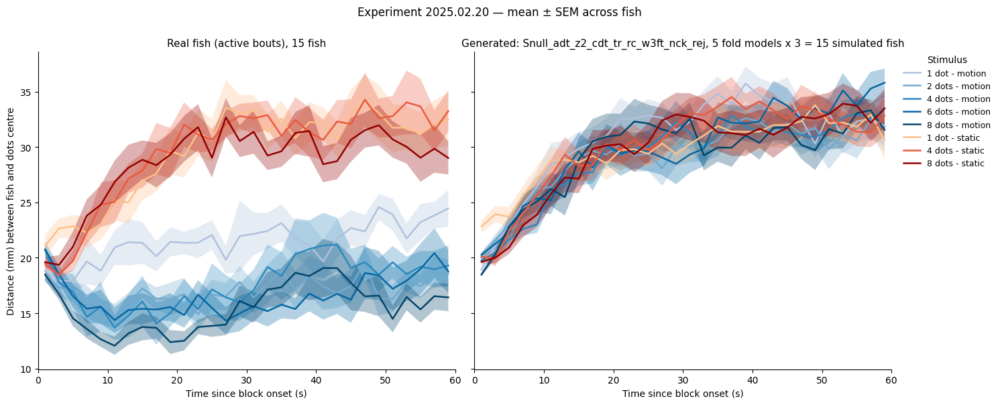


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

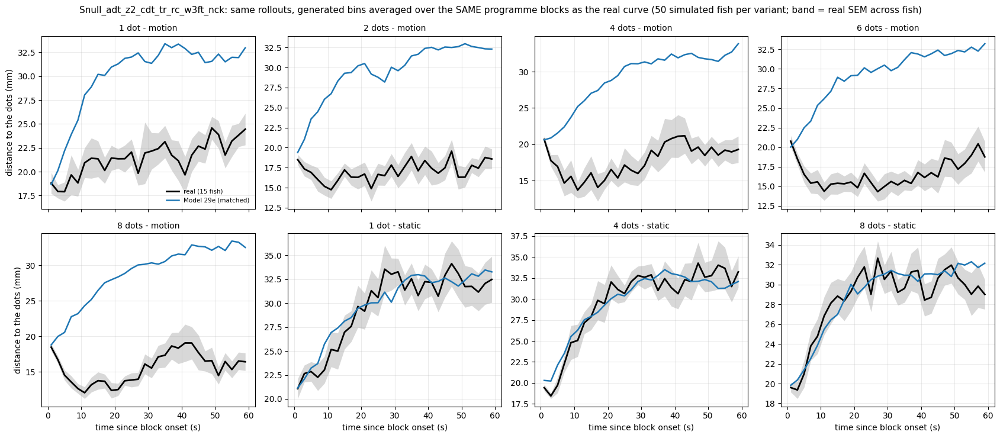


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   Snull_adt_z2_cdt_tr_rc_w3ft_nck                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           31.83  22.46      -9.37
d2s3.5       17.39  23.58       6.19                           31.05  22.51      -8.54
d4s3.5       18.74  23.93       5.19                           31.52  22.49      -9.02
d6s3.5       16.69  23.12       6.43                           31.33  22.53      -8.80
d8s3.5       16.41  23.36       6.94                           31.57  22.83      -8.74

== turn toward the moving dots by dot count
           real  Snull_adt

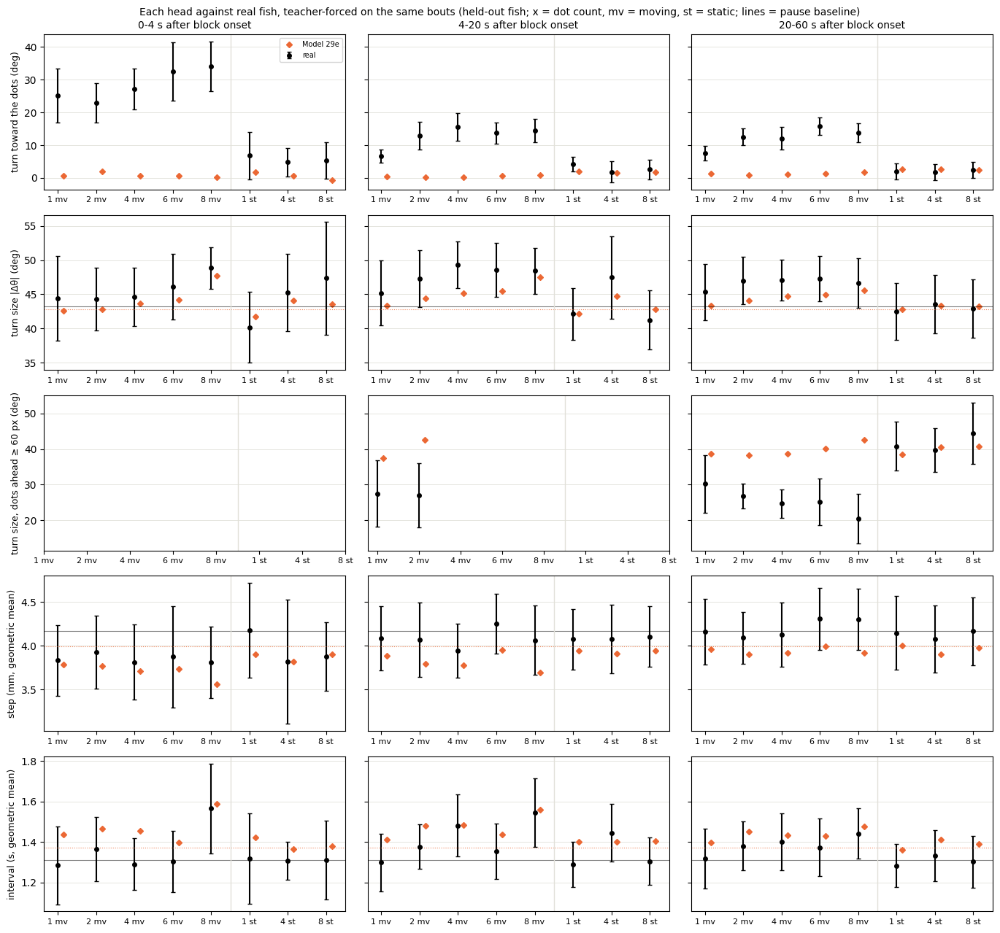

In [7]:
unit_eval.show('29e')

### M6-stim, seed 101


== held-out likelihood per head (bits per bout)
turn             7.709
displacement     4.503
interval         1.223
joint           13.436

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['Snull_adt_z2_cdt_tr_rc_w3ft_nck'] -> writing panelB_model1_rej_Snull_adt_z2_cdt_tr_rc_w3ft_nck.csv / c2st_model1_rej_Snull_adt_z2_cdt_tr_rc_w3ft_nck.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_Snull_adt_z2_cdt_tr_rc_w3ft_nck.csv  (15 rows) in 580s

Metric B, mean over held-out fish (lower = closer to real):
arm                     Snull_adt_z2_cdt_tr_rc_w3ft_nck_rej
abs_dtheta_w1                                        8.9389
symbol_js                                            0.0126
dt_

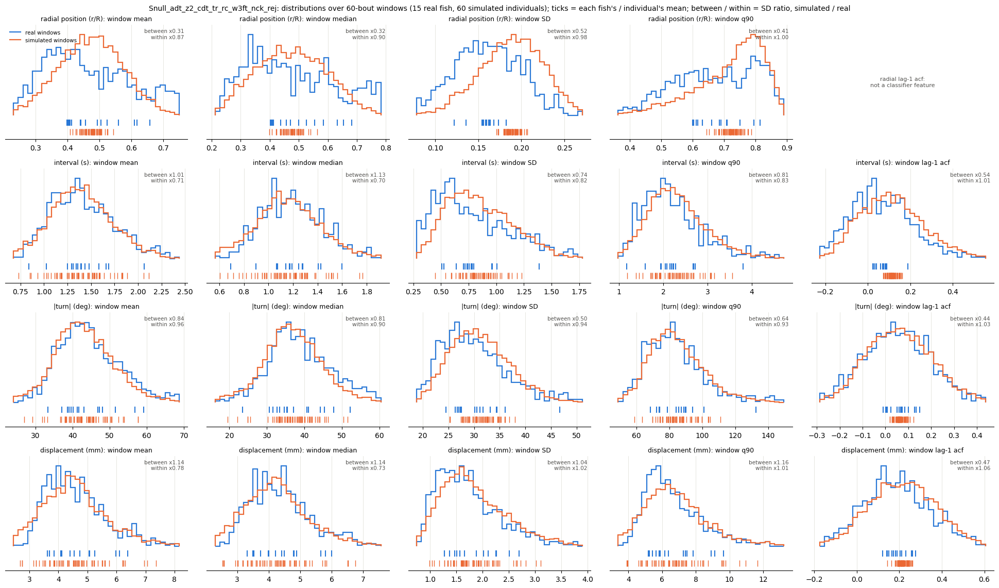


== distance to the dots across the block
  Snull_adt_z2_cdt_tr_rc_w3ft_nck_fold4.pt: 3 rollouts
dropped 11.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    8.21     5.51  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  31.3 +/- 0.6
d2s3.5   11.80     9.08  2.64   0.0  11.0   1.0                  17.4 +/- 0.9  30.8 +/- 0.9
d4s3.5   10.19     5.96  4.68   0.0  19.0   1.0                  18.7 +/- 1.7  29.5 +/- 0.8
d6s3.5   12.49     8.66  4.62   0.0  13.0   1.0                  16.7 +/- 1.3  31.0 +/- 1.2
d8s3.5   12.87    10.98  4.97   0.0  11.0   1.0                  16.3 +/- 1.0  30.7 +/- 1.0
d1s0     

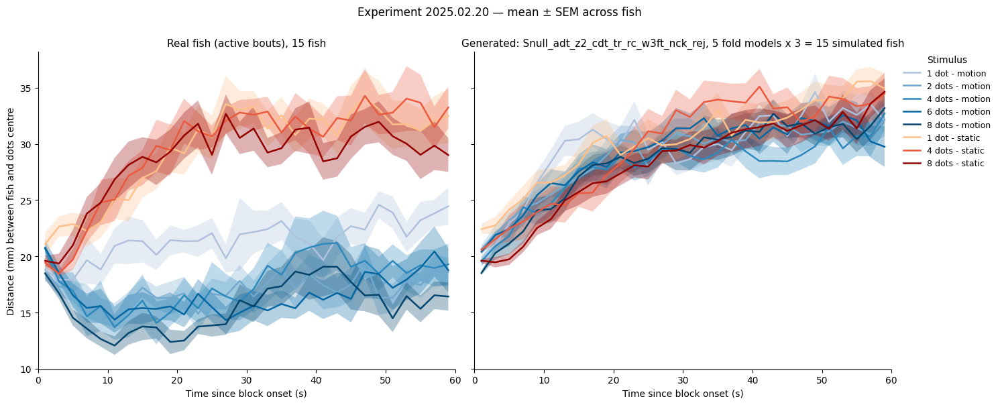


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

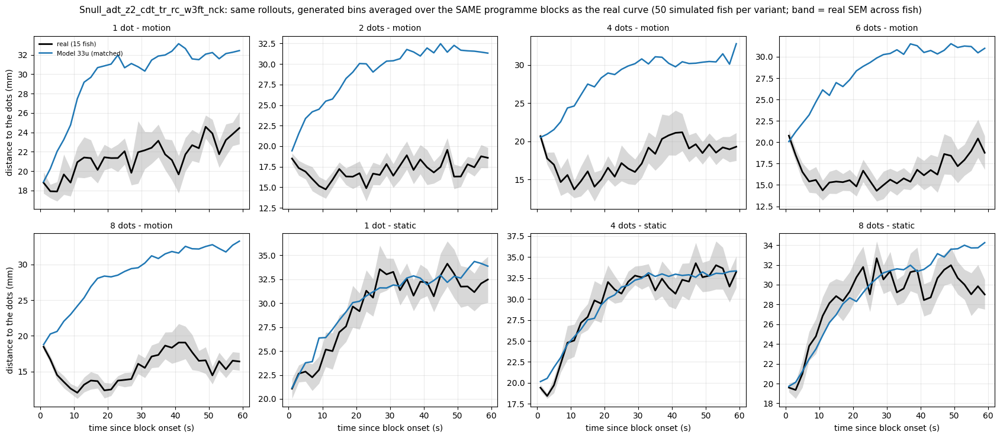


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   Snull_adt_z2_cdt_tr_rc_w3ft_nck                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           32.56  23.10      -9.46
d2s3.5       17.39  23.58       6.19                           31.66  23.00      -8.66
d4s3.5       18.74  23.93       5.19                           30.38  23.36      -7.02
d6s3.5       16.69  23.12       6.43                           30.45  22.88      -7.57
d8s3.5       16.41  23.36       6.94                           31.77  23.03      -8.74

== turn toward the moving dots by dot count
           real  Snull_adt

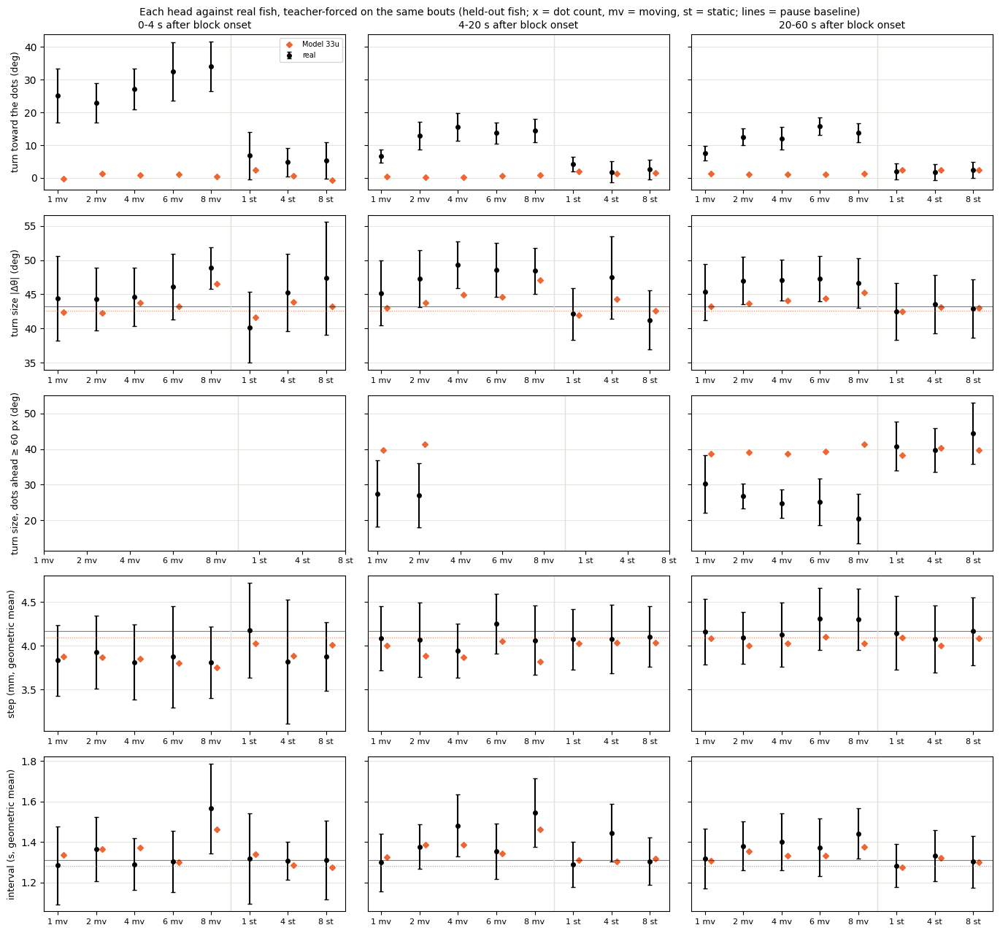

In [8]:
unit_eval.show('33u')

### M6-pos, seed 0


== held-out likelihood per head (bits per bout)
turn             7.688
displacement     4.517
interval         1.228
joint           13.432

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['Scond_adt_z2_cdt_tr_rc_w3ft'] -> writing panelB_model1_rej_Scond_adt_z2_cdt_tr_rc_w3ft.csv / c2st_model1_rej_Scond_adt_z2_cdt_tr_rc_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_Scond_adt_z2_cdt_tr_rc_w3ft.csv  (15 rows) in 407s

Metric B, mean over held-out fish (lower = closer to real):
arm                     Scond_adt_z2_cdt_tr_rc_w3ft_rej
abs_dtheta_w1                                    7.3928
symbol_js                                        0.0095
dt_w1                          

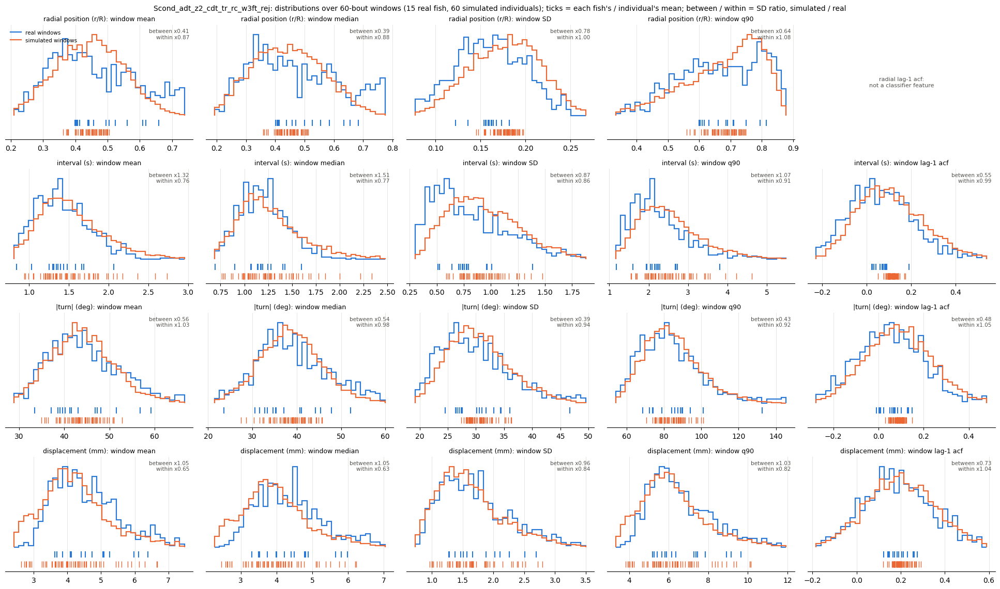


== distance to the dots across the block
  Scond_adt_z2_cdt_tr_rc_w3ft_fold4.pt: 3 rollouts
dropped 12.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    8.21     5.45  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  31.4 +/- 1.4
d2s3.5   11.40     8.79  2.64   0.0  11.0   1.0                  17.4 +/- 0.9  30.1 +/- 1.1
d4s3.5   10.44     5.99  4.68  0.16  19.0   3.0                  18.7 +/- 1.7  30.5 +/- 1.1
d6s3.5   12.35     8.58  4.62   0.0  13.0   1.0                  16.7 +/- 1.3  30.7 +/- 1.1
d8s3.5   12.90    10.88  4.97   0.0  11.0   1.0                  16.3 +/- 1.0  30.9 +/- 0.8
d1s0      2.1

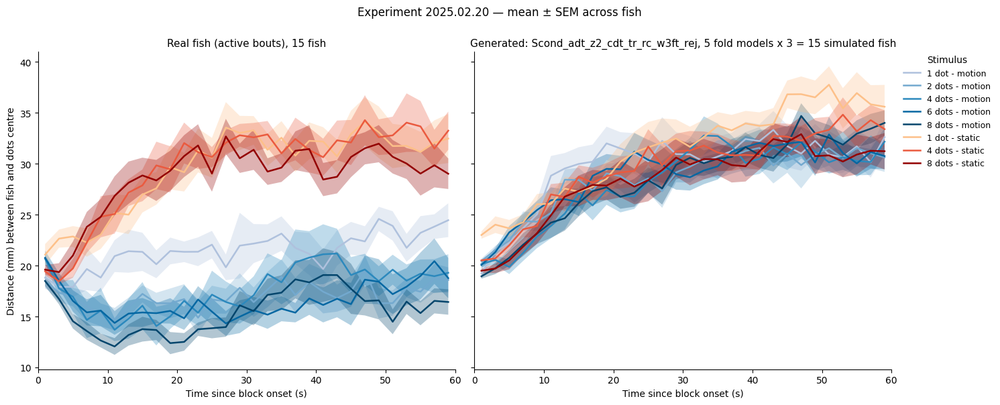


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

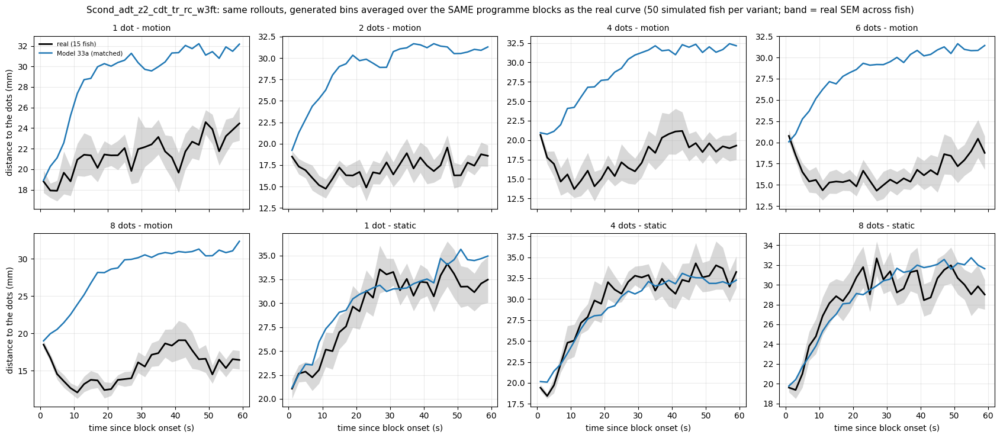


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   Scond_adt_z2_cdt_tr_rc_w3ft                  
           plateau   null attraction                     plateau   null attraction
cond_label                                                                        
d1s3.5       22.41  23.57       1.16                       31.02  22.47      -8.55
d2s3.5       17.39  23.58       6.19                       30.31  22.59      -7.72
d4s3.5       18.74  23.93       5.19                       31.11  22.58      -8.53
d6s3.5       16.69  23.12       6.43                       30.19  22.57      -7.62
d8s3.5       16.41  23.36       6.94                       30.95  22.45      -8.50

== turn toward the moving dots by dot count
           real  Scond_adt_z2_cdt_tr_rc_w3ft
win    N     

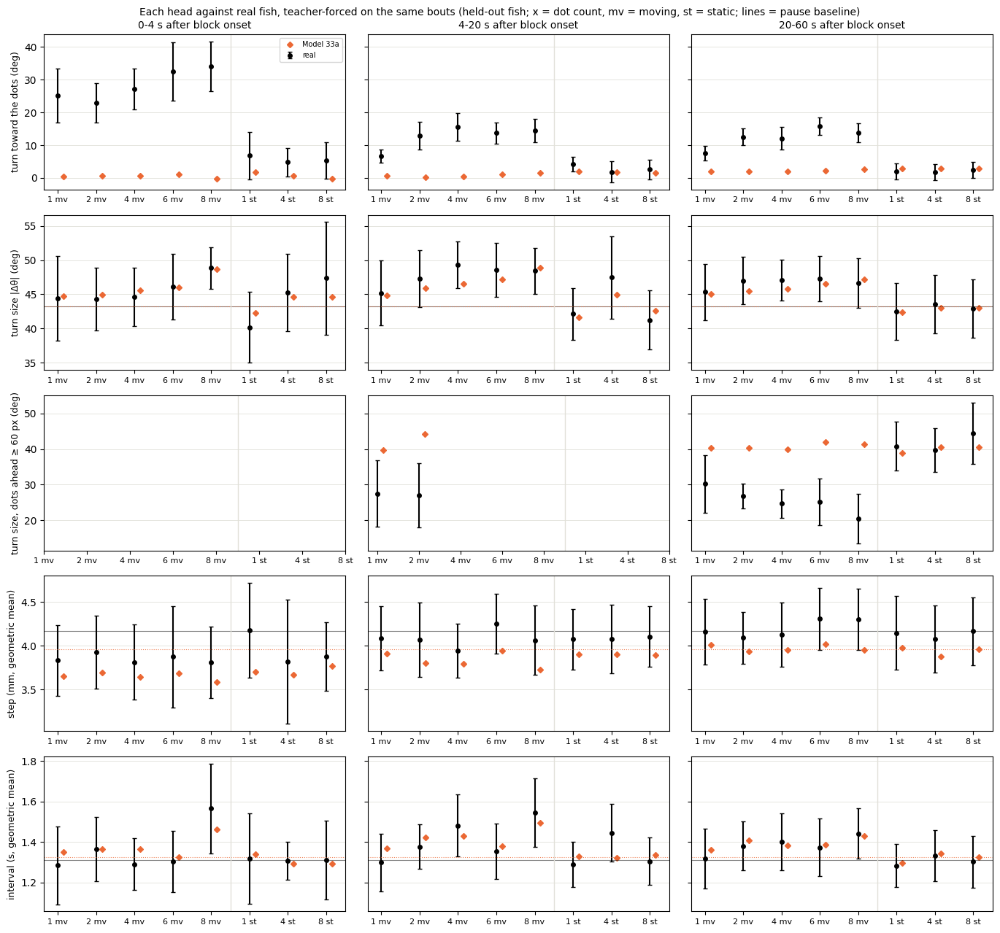

In [9]:
unit_eval.show('33a')

### M6-pos, seed 101


== held-out likelihood per head (bits per bout)
turn             7.697
displacement     4.495
interval         1.256
joint           13.448

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['Scond_adt_z2_cdt_tr_rc_w3ft'] -> writing panelB_model1_rej_Scond_adt_z2_cdt_tr_rc_w3ft.csv / c2st_model1_rej_Scond_adt_z2_cdt_tr_rc_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_Scond_adt_z2_cdt_tr_rc_w3ft.csv  (15 rows) in 644s

Metric B, mean over held-out fish (lower = closer to real):
arm                     Scond_adt_z2_cdt_tr_rc_w3ft_rej
abs_dtheta_w1                                    7.6027
symbol_js                                        0.0102
dt_w1                          

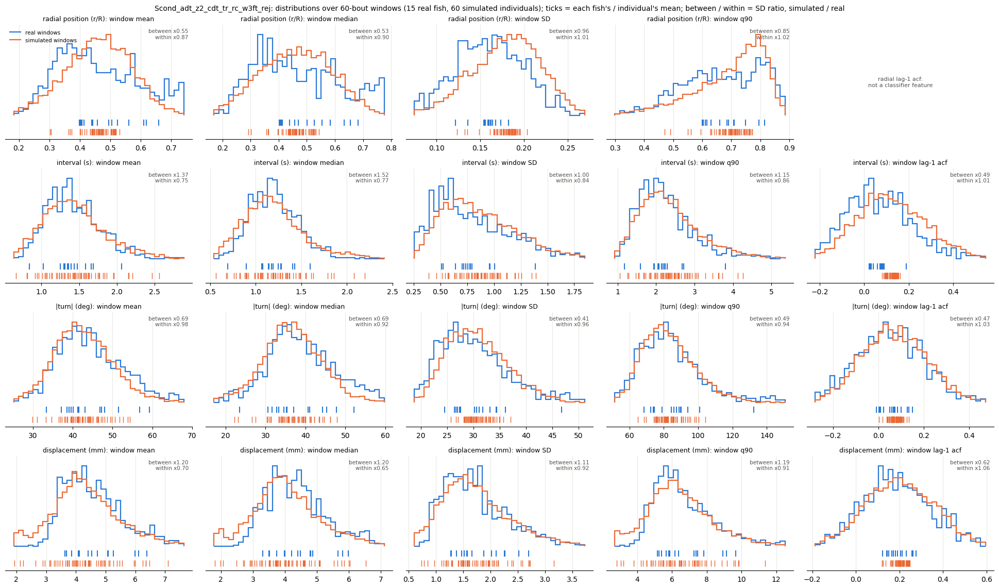


== distance to the dots across the block
  Scond_adt_z2_cdt_tr_rc_w3ft_fold4.pt: 3 rollouts
dropped 8.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    7.11     4.73  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  30.3 +/- 1.1
d2s3.5    9.52     7.38  2.64   0.0  11.0   1.0                  17.4 +/- 0.9  27.7 +/- 1.5
d4s3.5    9.87     5.67  4.68   0.0  19.0   1.0                  18.7 +/- 1.7  29.5 +/- 1.1
d6s3.5   10.53     7.14  4.62   0.0  13.0   1.0                  16.7 +/- 1.3  29.2 +/- 1.1
d8s3.5   11.00     9.36  4.97   0.0  11.0   1.0                  16.3 +/- 1.0  28.6 +/- 0.9
d1s0      1.28

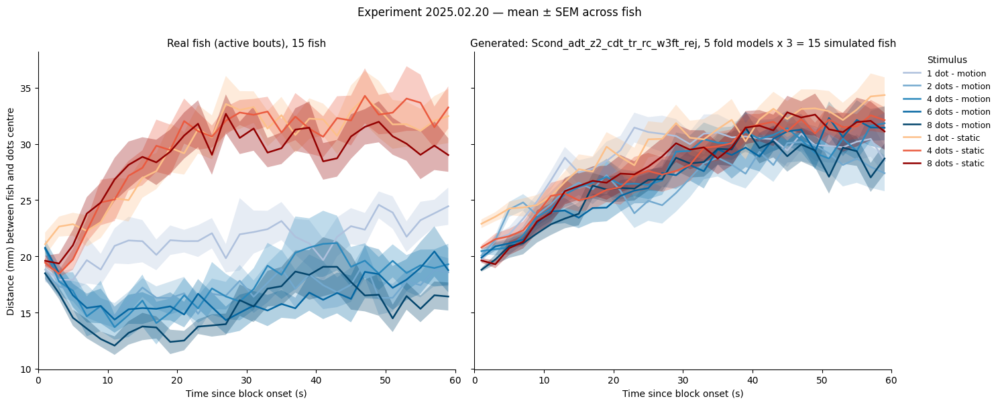


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

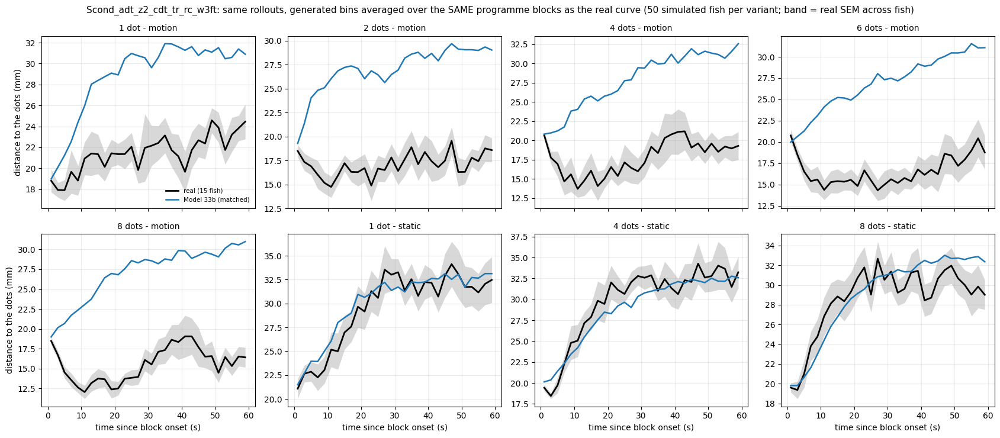


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   Scond_adt_z2_cdt_tr_rc_w3ft                  
           plateau   null attraction                     plateau   null attraction
cond_label                                                                        
d1s3.5       22.41  23.57       1.16                       30.74  21.64      -9.09
d2s3.5       17.39  23.58       6.19                       28.01  21.32      -6.69
d4s3.5       18.74  23.93       5.19                       30.79  21.37      -9.43
d6s3.5       16.69  23.12       6.43                       29.06  21.69      -7.37
d8s3.5       16.41  23.36       6.94                       28.91  21.60      -7.31

== turn toward the moving dots by dot count
           real  Scond_adt_z2_cdt_tr_rc_w3ft
win    N     

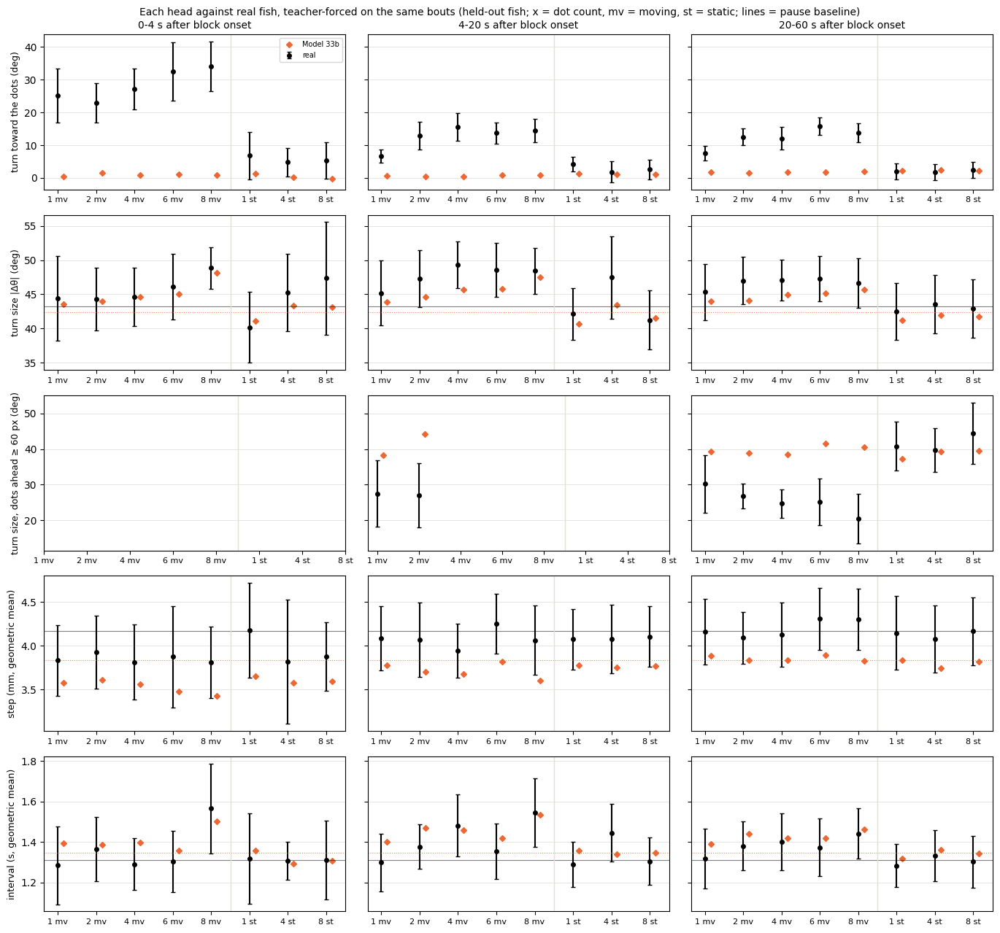

In [10]:
unit_eval.show('33b')

### M6-count, seed 0


== held-out likelihood per head (bits per bout)
turn             7.678
displacement     4.499
interval         1.227
joint           13.405

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xnn_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4xnn_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4xnn_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xnn_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 701s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xnn_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                       7.9708
symbol_js                                           0.0108
dt_w1     

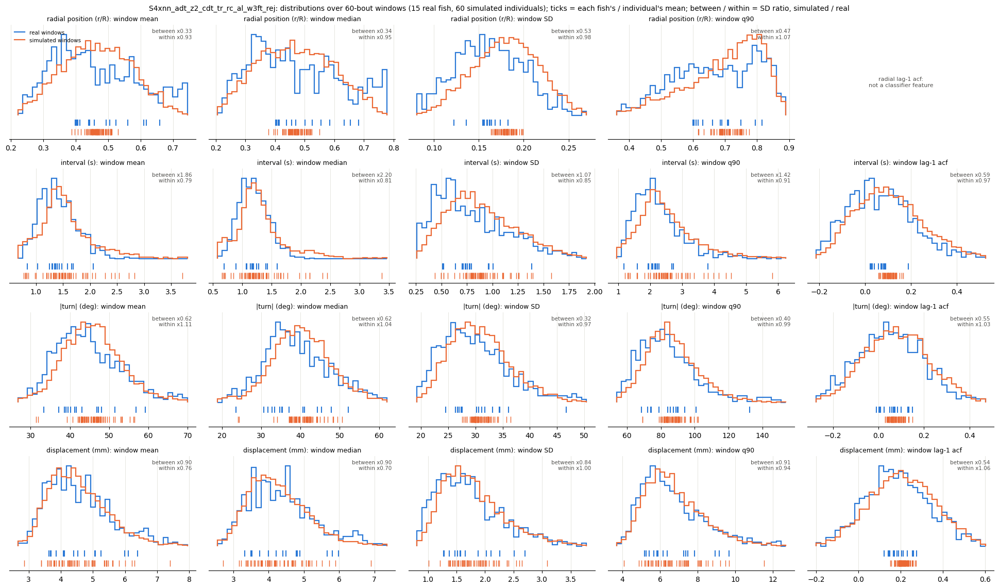


== distance to the dots across the block
  S4xnn_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.66     1.76  0.15  0.97   3.0   5.0                  22.3 +/- 0.9  18.9 +/- 0.8
d2s3.5    1.33     1.09  2.64  1.59  11.0  11.0                  17.4 +/- 0.9  17.1 +/- 0.6
d4s3.5    1.63     0.98  4.68   3.0  19.0   9.0                  18.7 +/- 1.7  17.3 +/- 1.0
d6s3.5    1.63     1.22  4.62  3.02  13.0  13.0                  16.7 +/- 1.3  18.1 +/- 0.9
d8s3.5    2.09     2.05  4.97  2.47  11.0  13.0                  16.3 +/- 1.0  17.0 +/- 1.0
d1s0      

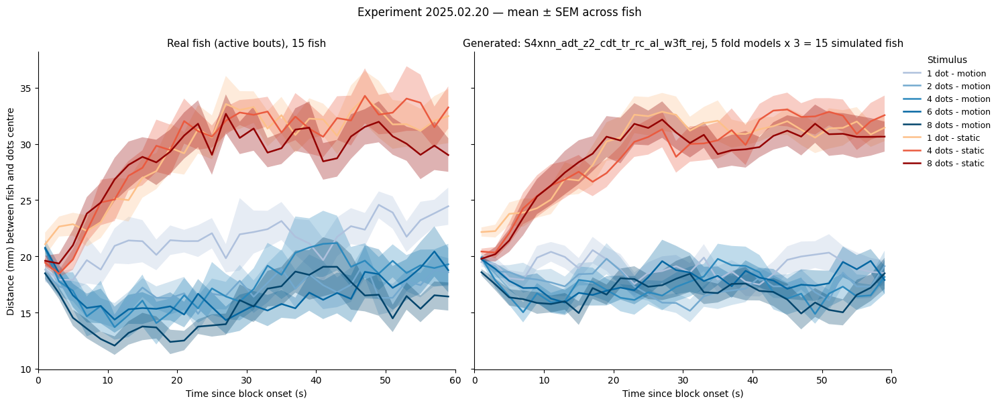


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

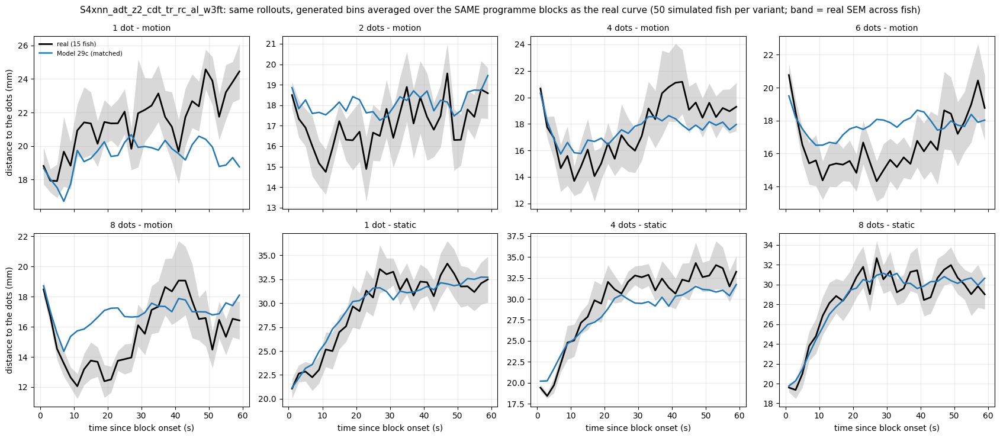


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xnn_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          19.33  22.70       3.36
d2s3.5       17.39  23.58       6.19                          17.88  22.68       4.80
d4s3.5       18.74  23.93       5.19                          17.71  22.80       5.08
d6s3.5       16.69  23.12       6.43                          17.81  22.56       4.74
d8s3.5       16.41  23.36       6.94                          17.56  22.77       5.21

== turn toward the moving dots by dot count
           real  S4xnn_adt_z2_cdt_

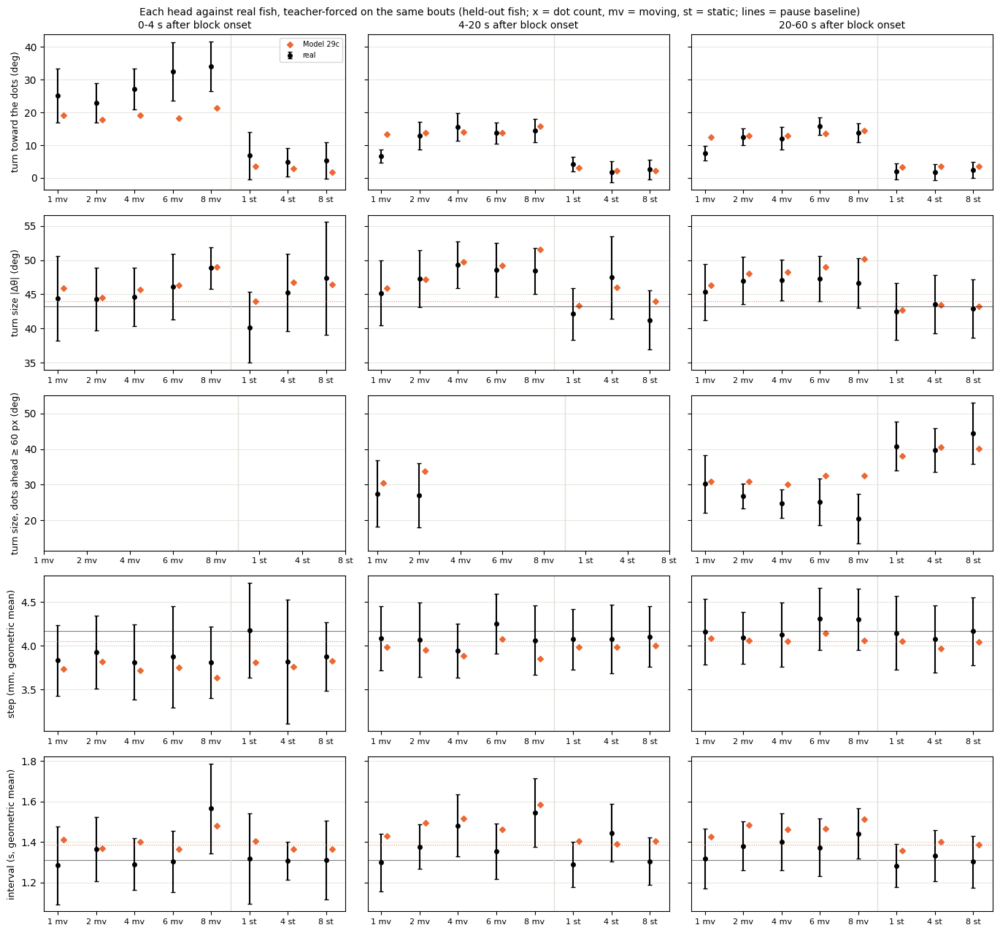

In [11]:
unit_eval.show('29c')

### M6-count, seed 101


== held-out likelihood per head (bits per bout)
turn             7.664
displacement     4.509
interval         1.228
joint           13.401

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xnn_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4xnn_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4xnn_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xnn_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 517s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xnn_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                       7.5588
symbol_js                                           0.0100
dt_w1     

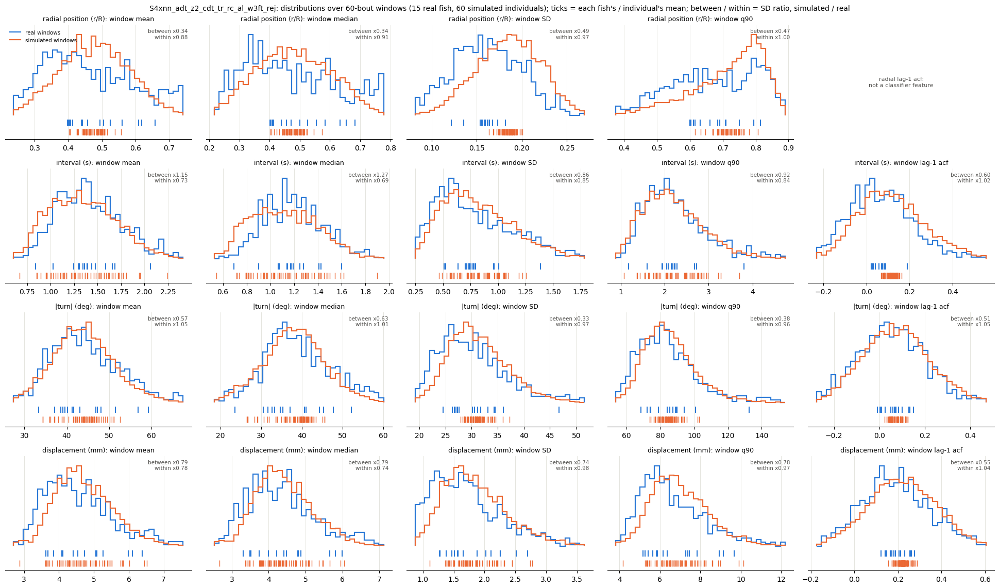


== distance to the dots across the block
  S4xnn_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 12.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.86     1.24  0.15  1.12   3.0   7.0                  22.3 +/- 0.9  20.0 +/- 1.0
d2s3.5    2.11     1.69  2.64  2.28  11.0   9.0                  17.4 +/- 0.9  19.5 +/- 0.6
d4s3.5    1.17     0.75  4.68  2.78  19.0  11.0                  18.7 +/- 1.7  18.8 +/- 1.0
d6s3.5    1.05     0.74  4.62  3.95  13.0  11.0                  16.7 +/- 1.3  17.3 +/- 0.6
d8s3.5    1.93     1.85  4.97  2.65  11.0   9.0                  16.3 +/- 1.0  17.6 +/- 0.6
d1s0      

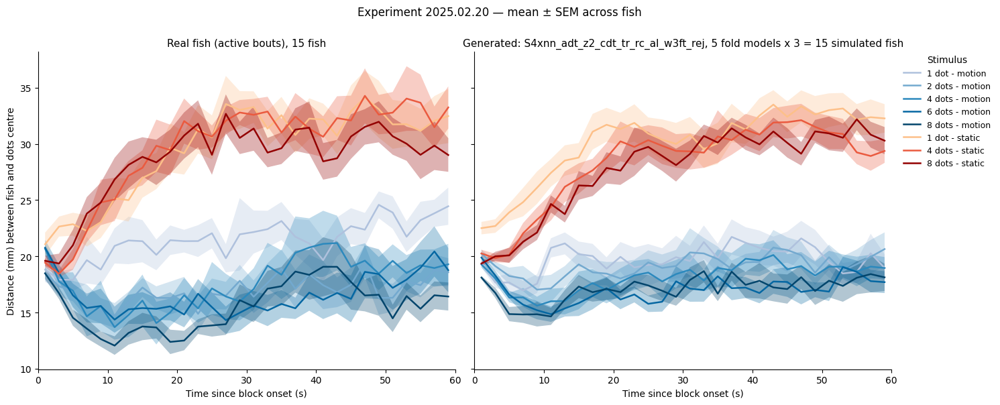


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

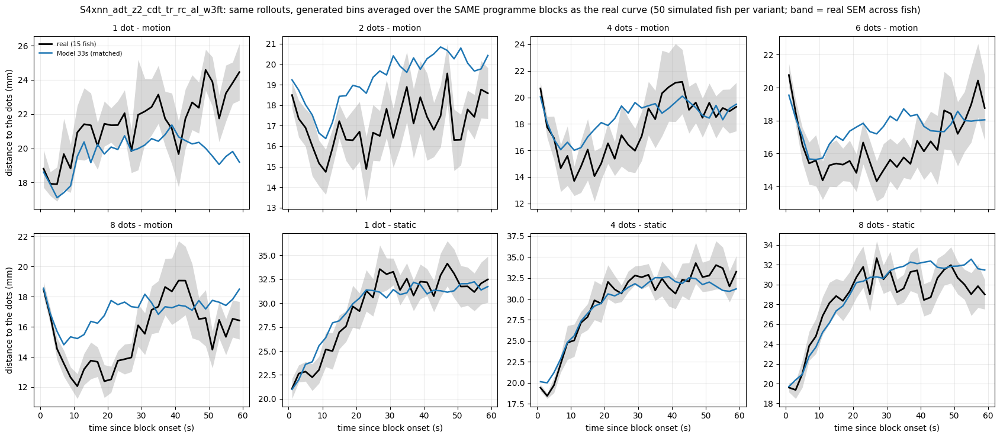


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xnn_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          20.90  22.99       2.09
d2s3.5       17.39  23.58       6.19                          19.72  22.95       3.22
d4s3.5       18.74  23.93       5.19                          19.26  22.85       3.60
d6s3.5       16.69  23.12       6.43                          17.88  23.11       5.23
d8s3.5       16.41  23.36       6.94                          17.51  22.88       5.37

== turn toward the moving dots by dot count
           real  S4xnn_adt_z2_cdt_

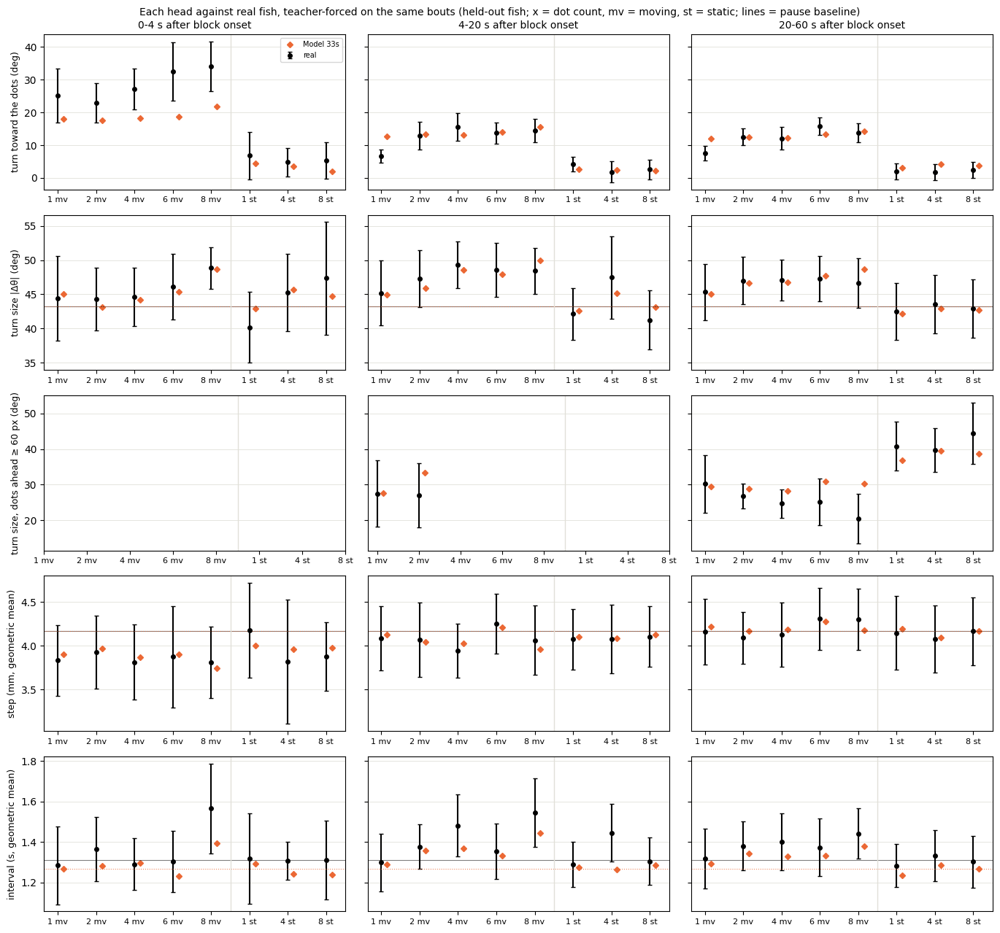

In [12]:
unit_eval.show('33s')

### M6-range, seed 0


== held-out likelihood per head (bits per bout)
turn             7.679
displacement     4.515
interval         1.208
joint           13.402

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xnr_adt_z2_cdt_tr_rc_w3ft'] -> writing panelB_model1_rej_S4xnr_adt_z2_cdt_tr_rc_w3ft.csv / c2st_model1_rej_S4xnr_adt_z2_cdt_tr_rc_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xnr_adt_z2_cdt_tr_rc_w3ft.csv  (15 rows) in 1205s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xnr_adt_z2_cdt_tr_rc_w3ft_rej
abs_dtheta_w1                                    8.4898
symbol_js                                        0.0109
dt_w1                         

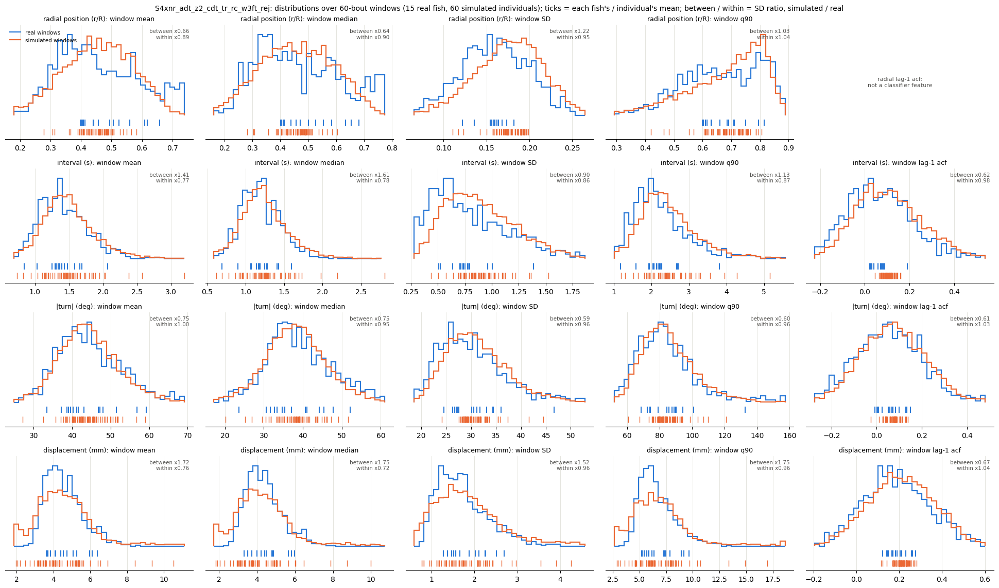


== distance to the dots across the block
  S4xnr_adt_z2_cdt_tr_rc_w3ft_fold4.pt: 3 rollouts
dropped 9.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.07     1.42  0.15  0.05   3.0   3.0                  22.3 +/- 0.9  20.3 +/- 0.9
d2s3.5    1.78     1.42  2.64  1.39  11.0  19.0                  17.4 +/- 0.9  18.5 +/- 1.0
d4s3.5    1.27     0.67  4.68  4.28  19.0   9.0                  18.7 +/- 1.7  17.1 +/- 1.0
d6s3.5    1.11     0.73  4.62  3.23  13.0  11.0                  16.7 +/- 1.3  16.1 +/- 0.9
d8s3.5    1.55     1.31  4.97  3.16  11.0   9.0                  16.3 +/- 1.0  15.7 +/- 1.1
d1s0      2.73

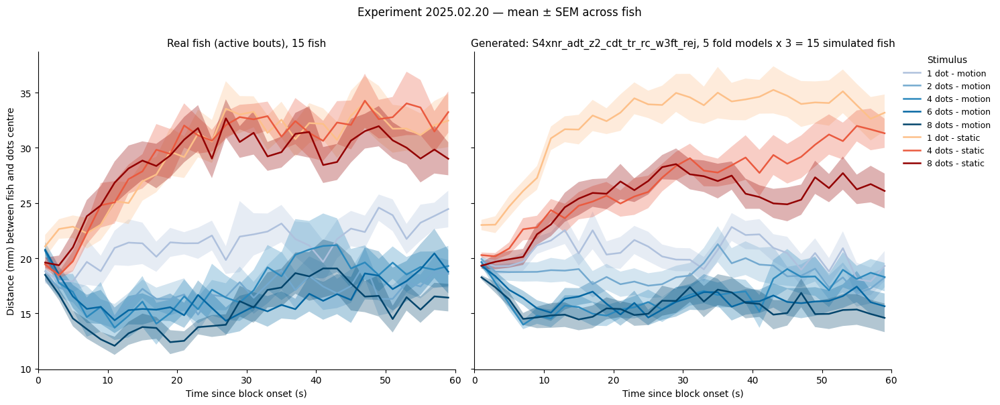


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

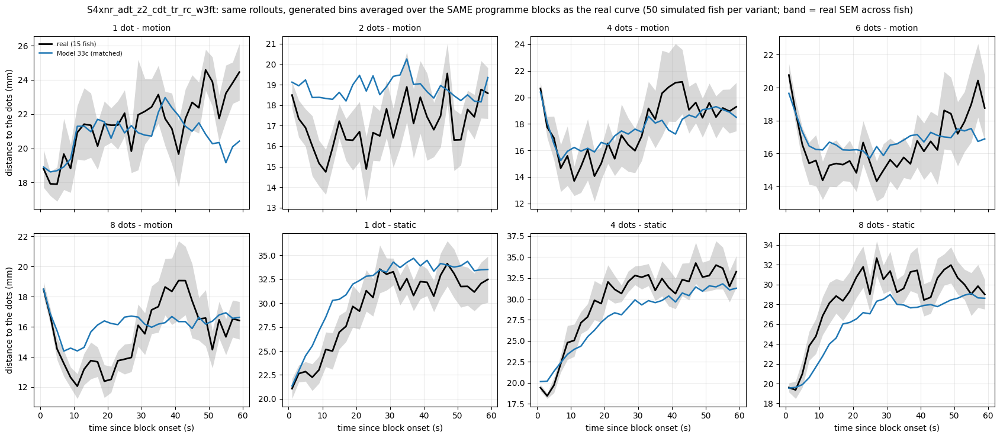


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xnr_adt_z2_cdt_tr_rc_w3ft                  
           plateau   null attraction                     plateau   null attraction
cond_label                                                                        
d1s3.5       22.41  23.57       1.16                       20.91  22.17       1.26
d2s3.5       17.39  23.58       6.19                       19.02  22.26       3.24
d4s3.5       18.74  23.93       5.19                       18.23  22.26       4.03
d6s3.5       16.69  23.12       6.43                       16.50  22.60       6.09
d8s3.5       16.41  23.36       6.94                       16.43  22.03       5.60

== turn toward the moving dots by dot count
           real  S4xnr_adt_z2_cdt_tr_rc_w3ft
win    N     

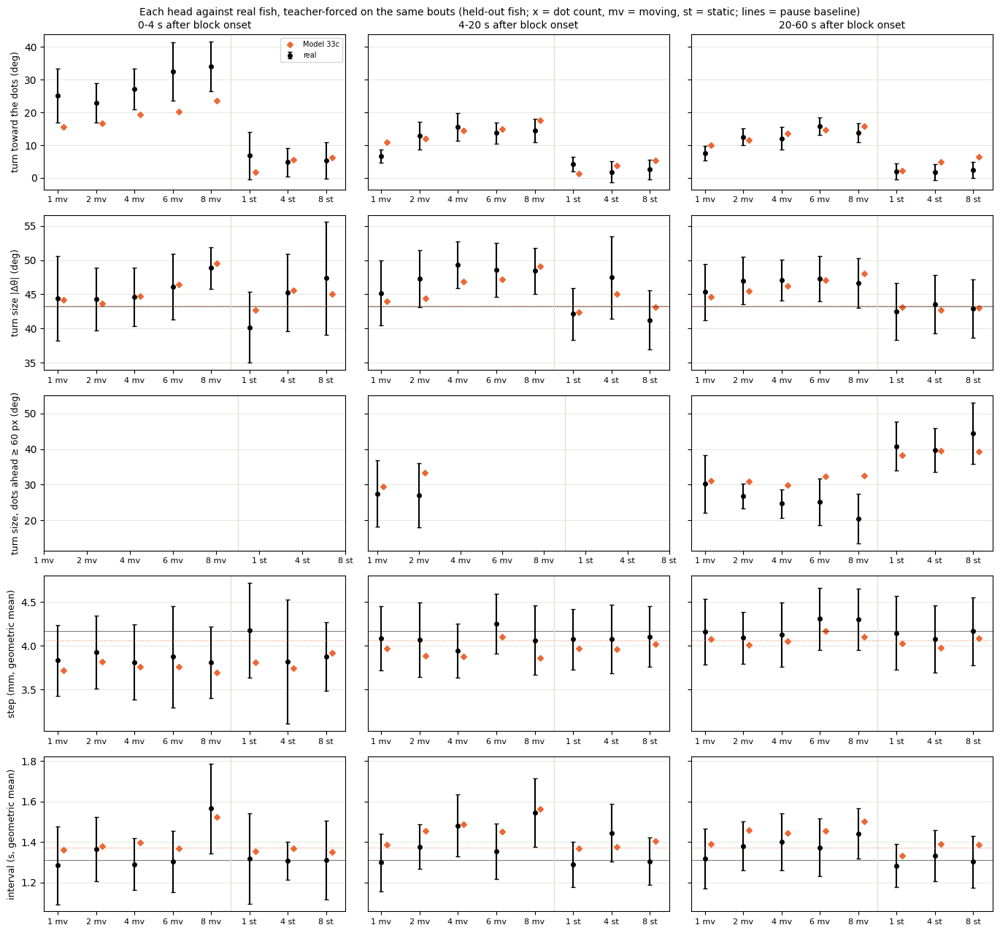

In [13]:
unit_eval.show('33c')

### M6-range, seed 101


== held-out likelihood per head (bits per bout)
turn             7.656
displacement     4.494
interval         1.237
joint           13.387

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xnr_adt_z2_cdt_tr_rc_w3ft'] -> writing panelB_model1_rej_S4xnr_adt_z2_cdt_tr_rc_w3ft.csv / c2st_model1_rej_S4xnr_adt_z2_cdt_tr_rc_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xnr_adt_z2_cdt_tr_rc_w3ft.csv  (15 rows) in 602s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xnr_adt_z2_cdt_tr_rc_w3ft_rej
abs_dtheta_w1                                    7.8451
symbol_js                                        0.0107
dt_w1                          

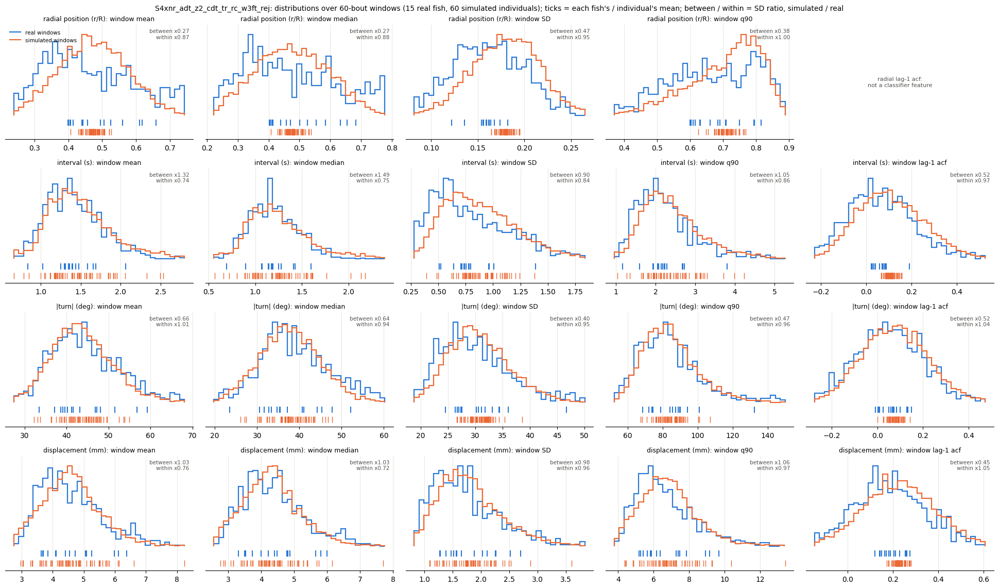


== distance to the dots across the block
  S4xnr_adt_z2_cdt_tr_rc_w3ft_fold4.pt: 3 rollouts
dropped 11.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.49     1.04  0.15  0.22   3.0   5.0                  22.3 +/- 0.9  22.2 +/- 0.7
d2s3.5    1.86     1.49  2.64  2.14  11.0   9.0                  17.4 +/- 0.9  19.2 +/- 0.7
d4s3.5    1.55     0.86  4.68  3.95  19.0   9.0                  18.7 +/- 1.7  16.9 +/- 0.5
d6s3.5    1.22     0.83  4.62  3.65  13.0  13.0                  16.7 +/- 1.3  17.5 +/- 0.6
d8s3.5    1.87     1.75  4.97  3.19  11.0   7.0                  16.3 +/- 1.0  17.1 +/- 0.9
d1s0      2.8

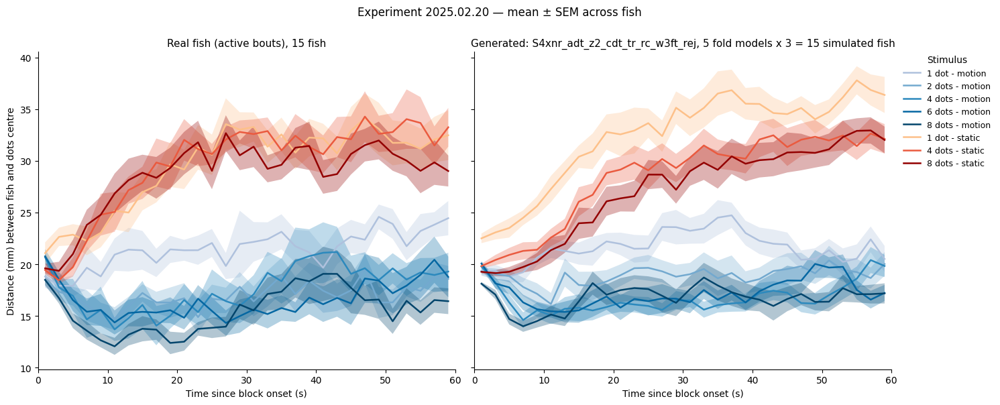


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

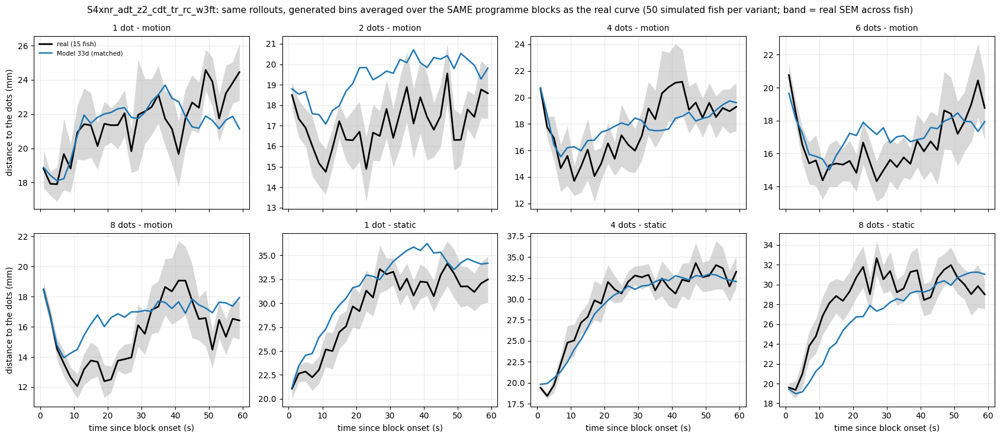


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xnr_adt_z2_cdt_tr_rc_w3ft                  
           plateau   null attraction                     plateau   null attraction
cond_label                                                                        
d1s3.5       22.41  23.57       1.16                       22.15  23.06       0.92
d2s3.5       17.39  23.58       6.19                       19.57  23.10       3.53
d4s3.5       18.74  23.93       5.19                       18.01  23.23       5.23
d6s3.5       16.69  23.12       6.43                       17.42  22.90       5.48
d8s3.5       16.41  23.36       6.94                       17.09  23.19       6.10

== turn toward the moving dots by dot count
           real  S4xnr_adt_z2_cdt_tr_rc_w3ft
win    N     

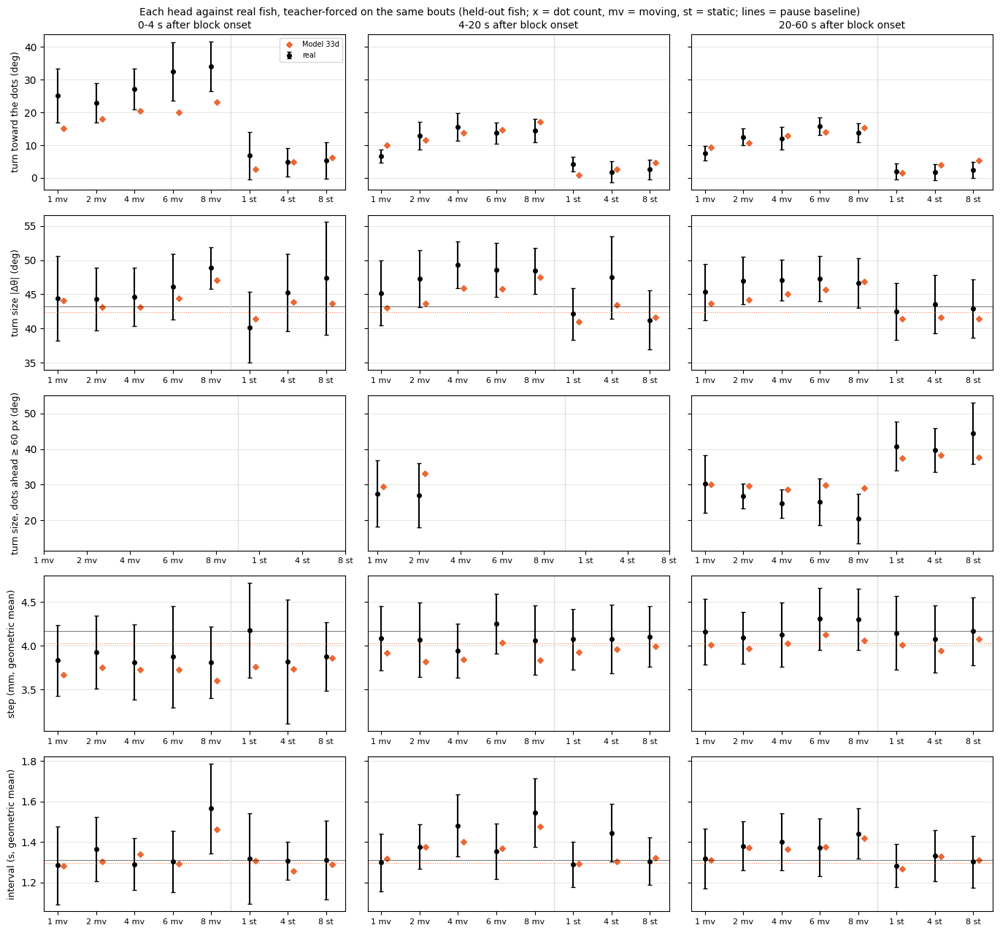

In [14]:
unit_eval.show('33d')

### M6-motion, seed 0


== held-out likelihood per head (bits per bout)
turn             7.676
displacement     4.520
interval         1.222
joint           13.418

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xnm_adt_z2_cdt_tr_rc_w3ft'] -> writing panelB_model1_rej_S4xnm_adt_z2_cdt_tr_rc_w3ft.csv / c2st_model1_rej_S4xnm_adt_z2_cdt_tr_rc_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xnm_adt_z2_cdt_tr_rc_w3ft.csv  (15 rows) in 650s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xnm_adt_z2_cdt_tr_rc_w3ft_rej
abs_dtheta_w1                                    7.6395
symbol_js                                        0.0092
dt_w1                          

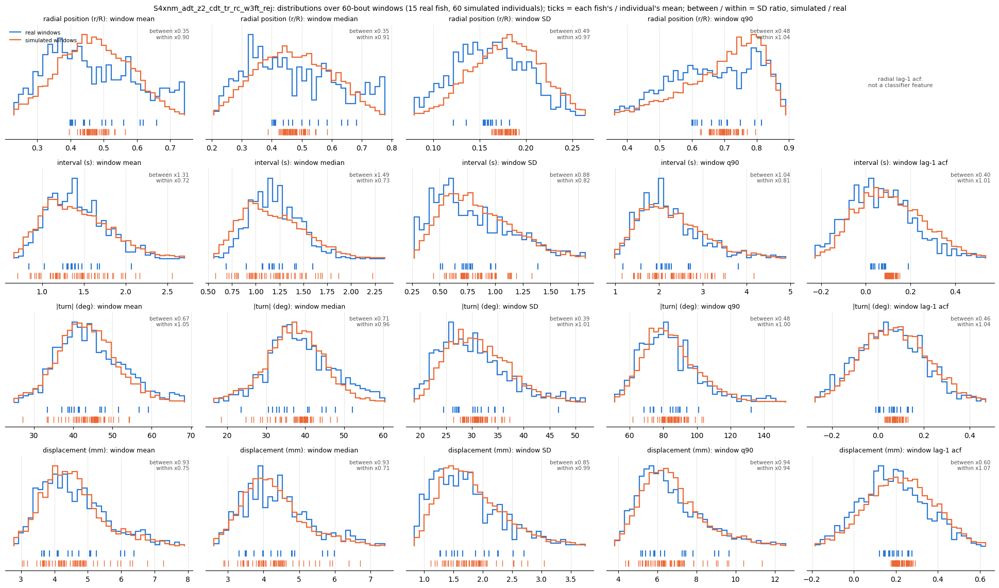


== distance to the dots across the block
  S4xnm_adt_z2_cdt_tr_rc_w3ft_fold4.pt: 3 rollouts
dropped 11.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.93     1.35  0.15  0.17   3.0   5.0                  22.3 +/- 0.9  23.3 +/- 0.8
d2s3.5    4.41     3.41  2.64  0.45  11.0   5.0                  17.4 +/- 0.9  22.2 +/- 0.7
d4s3.5    3.32     2.03  4.68  1.18  19.0   9.0                  18.7 +/- 1.7  21.5 +/- 1.0
d6s3.5    3.77     2.83  4.62   1.1  13.0   7.0                  16.7 +/- 1.3  20.5 +/- 1.4
d8s3.5    4.80     4.40  4.97   0.3  11.0   5.0                  16.3 +/- 1.0  21.2 +/- 0.9
d1s0      6.1

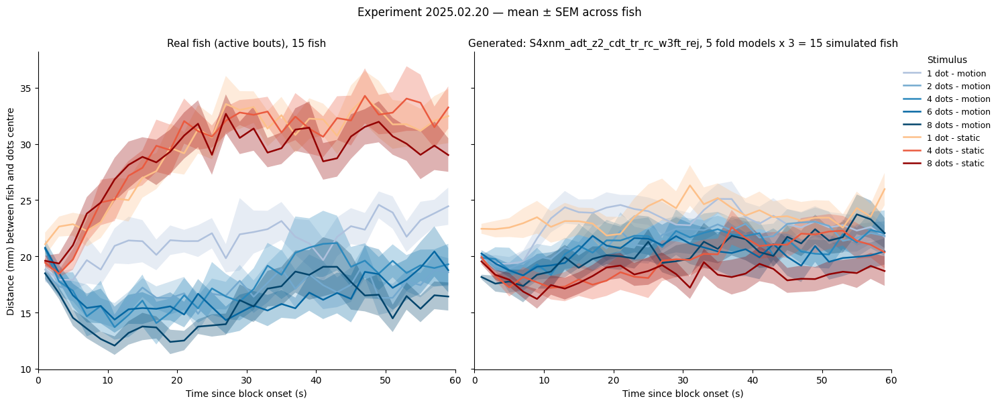


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

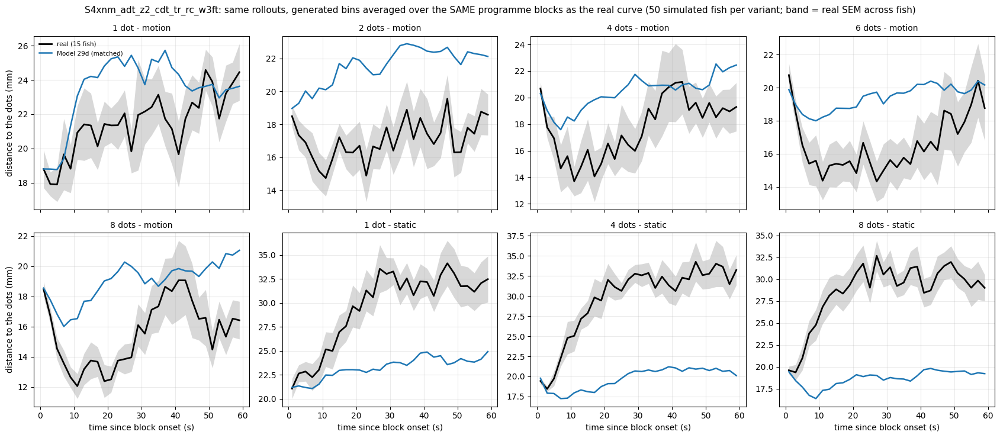


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xnm_adt_z2_cdt_tr_rc_w3ft                  
           plateau   null attraction                     plateau   null attraction
cond_label                                                                        
d1s3.5       22.41  23.57       1.16                       24.66  22.34      -2.32
d2s3.5       17.39  23.58       6.19                       22.43  22.56       0.13
d4s3.5       18.74  23.93       5.19                       21.99  22.53       0.53
d6s3.5       16.69  23.12       6.43                       20.63  22.66       2.02
d8s3.5       16.41  23.36       6.94                       20.56  22.38       1.81

== turn toward the moving dots by dot count
           real  S4xnm_adt_z2_cdt_tr_rc_w3ft
win    N     

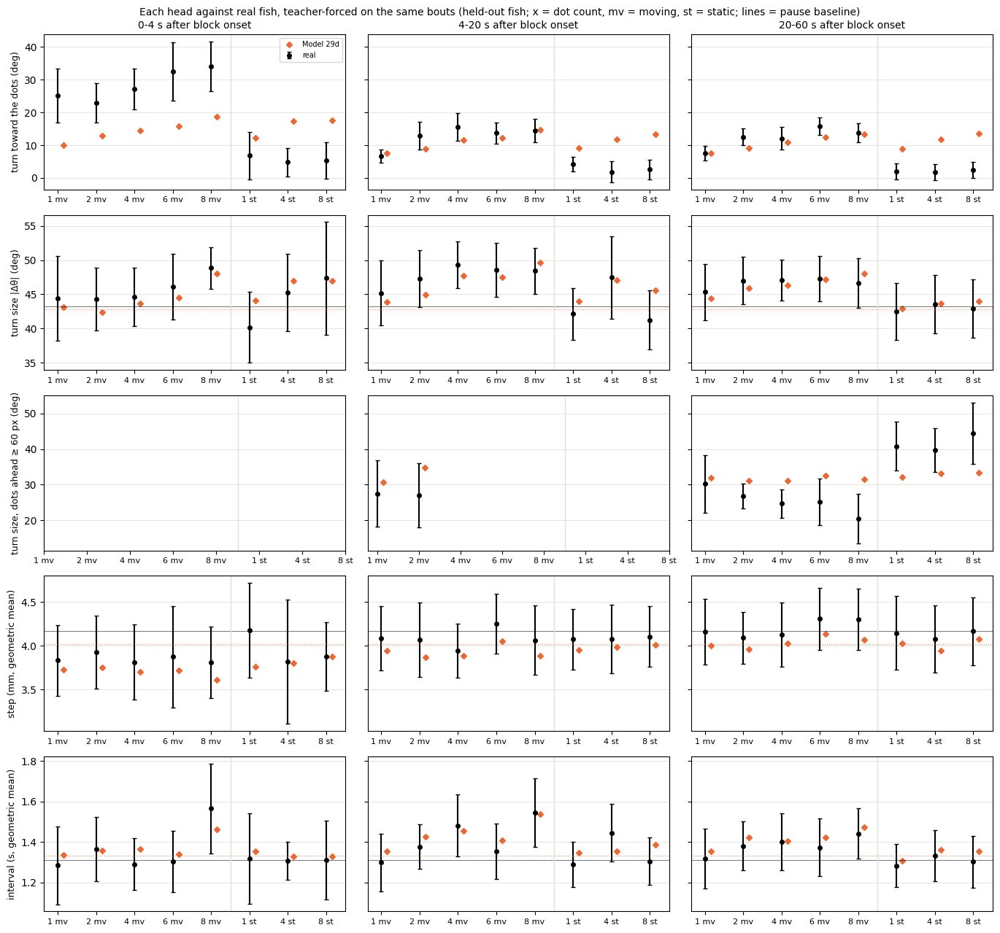

In [15]:
unit_eval.show('29d')

### M6-motion, seed 101


== held-out likelihood per head (bits per bout)
turn             7.683
displacement     4.512
interval         1.246
joint           13.441

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xnm_adt_z2_cdt_tr_rc_w3ft'] -> writing panelB_model1_rej_S4xnm_adt_z2_cdt_tr_rc_w3ft.csv / c2st_model1_rej_S4xnm_adt_z2_cdt_tr_rc_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xnm_adt_z2_cdt_tr_rc_w3ft.csv  (15 rows) in 1299s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xnm_adt_z2_cdt_tr_rc_w3ft_rej
abs_dtheta_w1                                    7.2698
symbol_js                                        0.0089
dt_w1                         

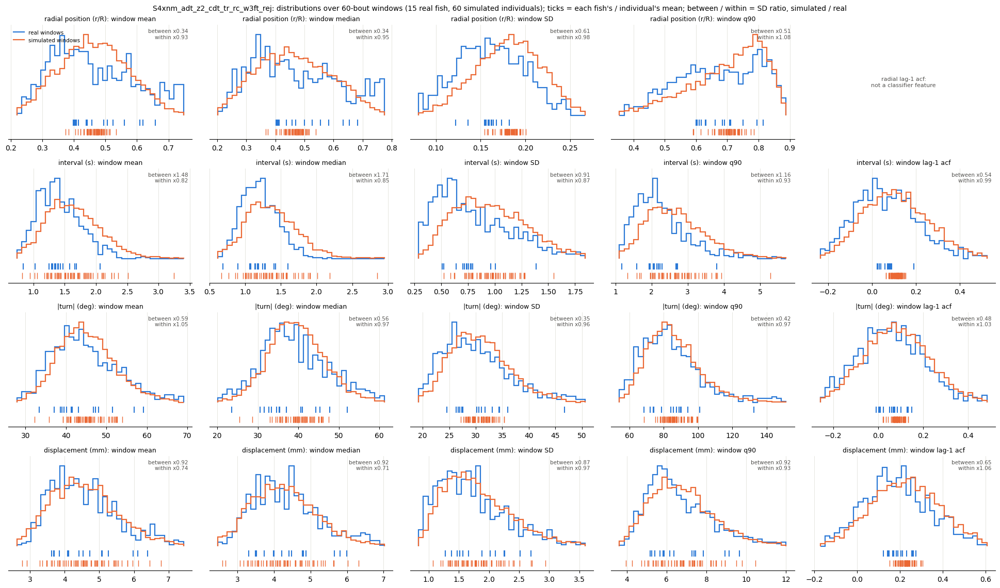


== distance to the dots across the block
  S4xnm_adt_z2_cdt_tr_rc_w3ft_fold4.pt: 3 rollouts
dropped 13.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    3.05     2.01  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  25.2 +/- 0.7
d2s3.5    4.62     3.62  2.64   0.0  11.0   1.0                  17.4 +/- 0.9  22.2 +/- 0.6
d4s3.5    4.22     2.56  4.68  1.23  19.0   7.0                  18.7 +/- 1.7  22.9 +/- 0.9
d6s3.5    4.26     3.01  4.62  1.36  13.0   5.0                  16.7 +/- 1.3  21.7 +/- 1.4
d8s3.5    3.20     3.14  4.97  1.27  11.0   7.0                  16.3 +/- 1.0  19.1 +/- 0.9
d1s0      5.6

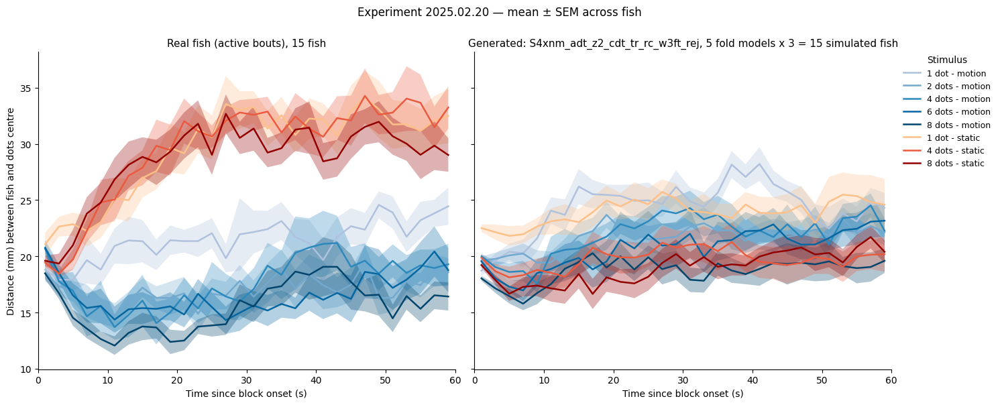


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

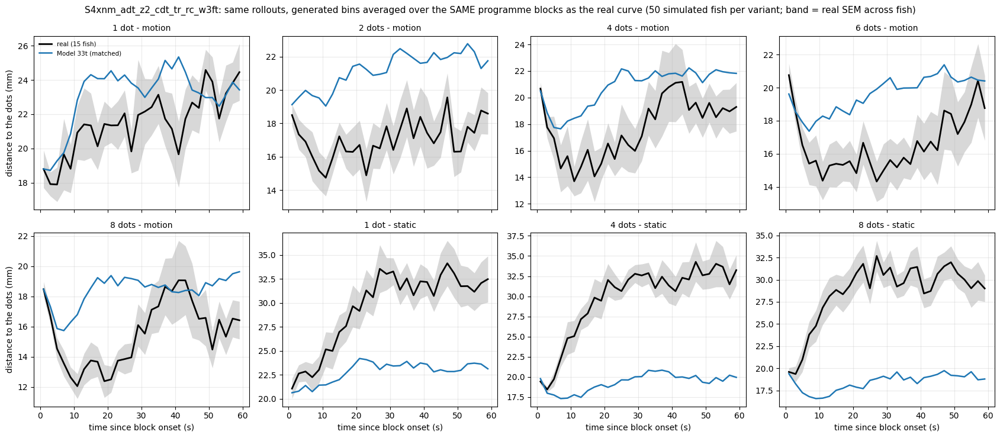


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xnm_adt_z2_cdt_tr_rc_w3ft                  
           plateau   null attraction                     plateau   null attraction
cond_label                                                                        
d1s3.5       22.41  23.57       1.16                       24.64  22.81      -1.83
d2s3.5       17.39  23.58       6.19                       21.91  22.35       0.44
d4s3.5       18.74  23.93       5.19                       22.90  22.87      -0.03
d6s3.5       16.69  23.12       6.43                       20.45  22.58       2.13
d8s3.5       16.41  23.36       6.94                       18.73  22.58       3.86

== turn toward the moving dots by dot count
           real  S4xnm_adt_z2_cdt_tr_rc_w3ft
win    N     

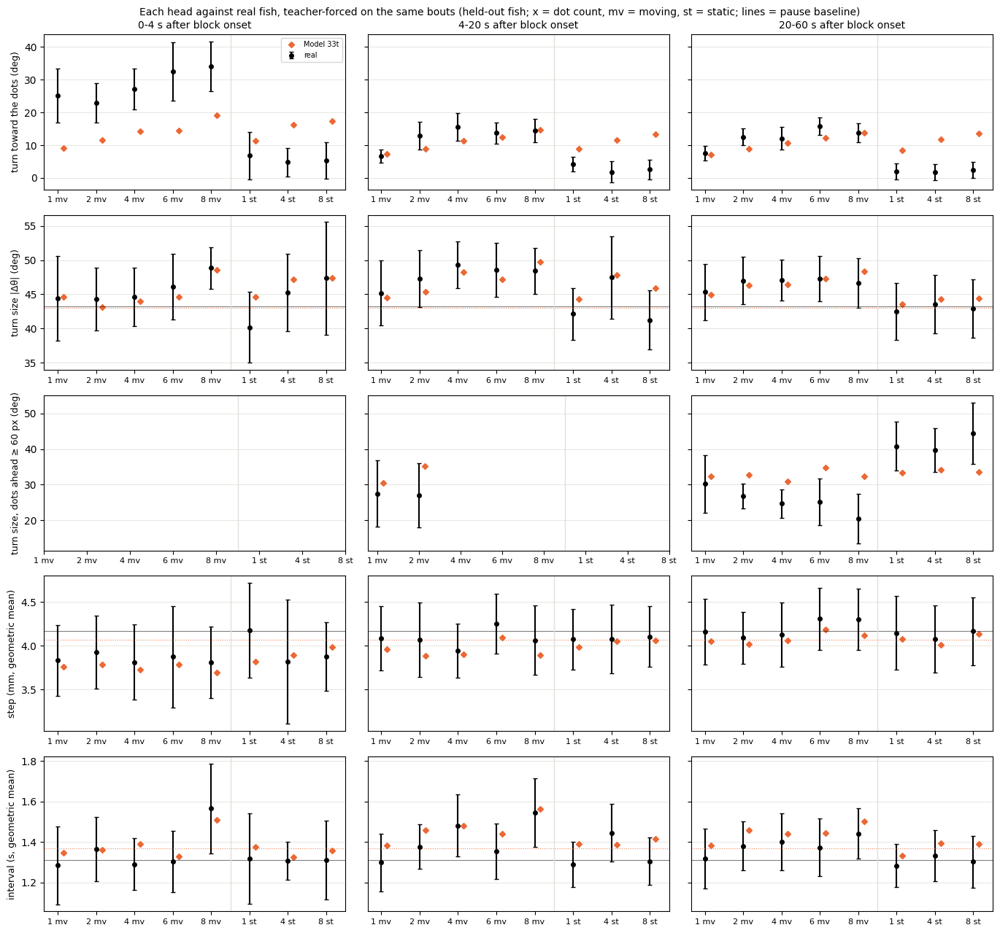

In [16]:
unit_eval.show('33t')

### M6-turn4, seed 0


== held-out likelihood per head (bits per bout)
turn             7.655
displacement     4.512
interval         1.219
joint           13.386

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h4'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h4.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h4.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h4.csv  (15 rows) in 323s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h4_rej
abs_dtheta_w1                                        8.6296
symbol_js                                            0.0119
dt_

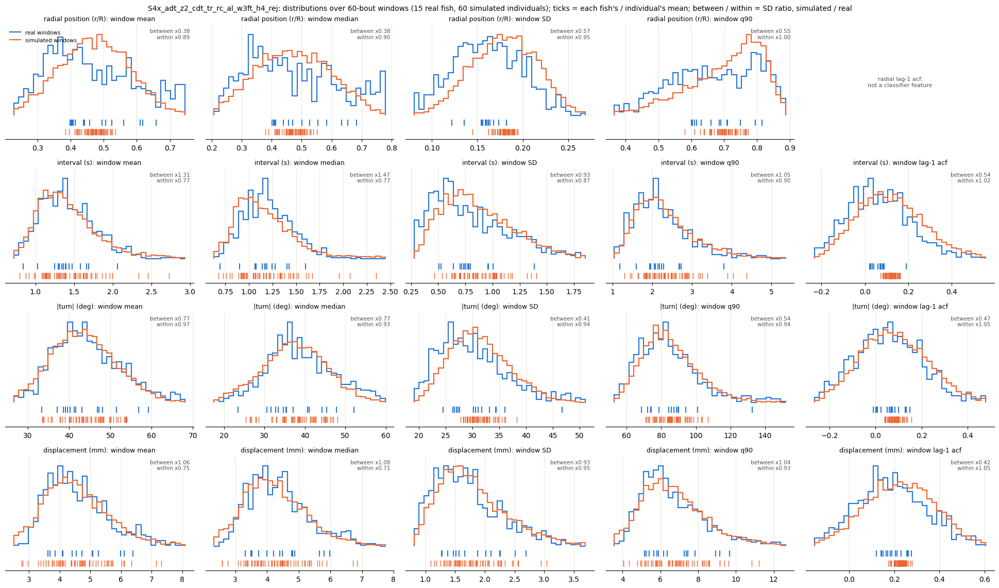


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h4_fold4.pt: 3 rollouts
dropped 10.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.86     1.27  0.15  0.32   3.0   9.0                  22.3 +/- 0.9  22.7 +/- 1.1
d2s3.5    1.75     1.39  2.64  2.23  11.0   9.0                  17.4 +/- 0.9  19.0 +/- 1.0
d4s3.5    1.70     0.98  4.68  2.41  19.0   9.0                  18.7 +/- 1.7  17.6 +/- 0.8
d6s3.5    1.33     1.01  4.62  3.22  13.0   9.0                  16.7 +/- 1.3  17.5 +/- 0.9
d8s3.5    1.57     1.35  4.97  2.82  11.0   9.0                  16.3 +/- 1.0  16.3 +/- 0.7
d1s0     

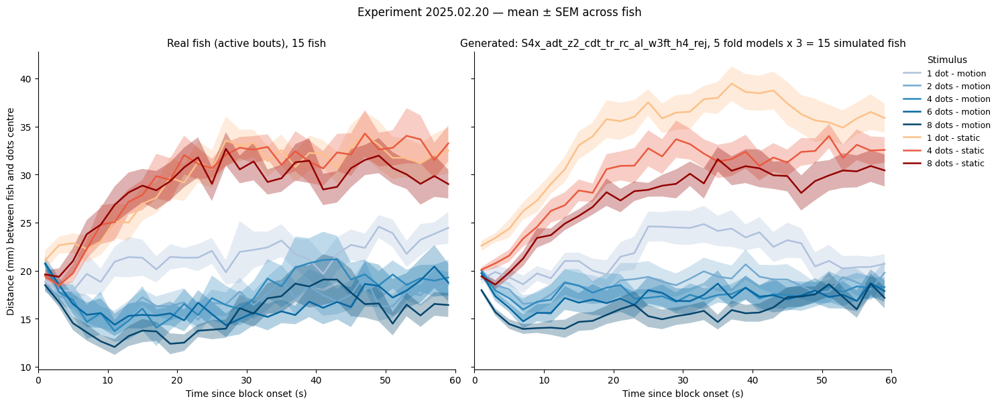


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

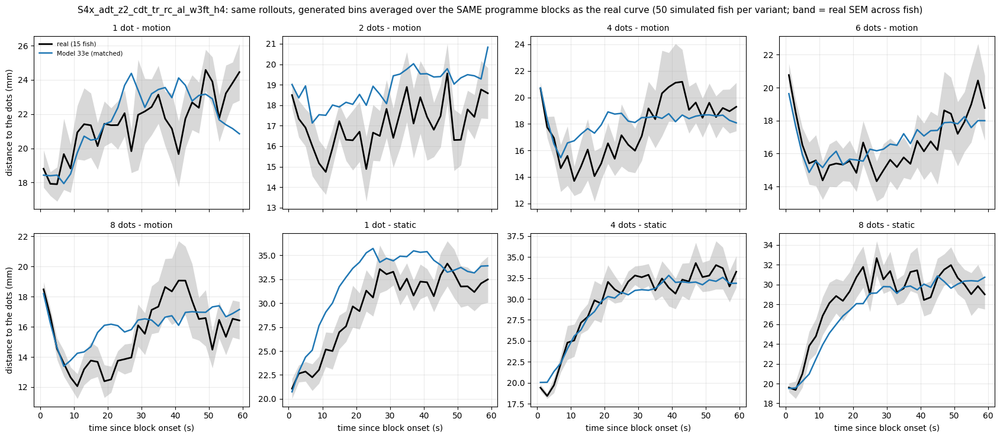


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h4                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           23.62  23.52      -0.10
d2s3.5       17.39  23.58       6.19                           18.99  23.36       4.37
d4s3.5       18.74  23.93       5.19                           19.01  23.30       4.29
d6s3.5       16.69  23.12       6.43                           17.28  23.03       5.75
d8s3.5       16.41  23.36       6.94                           16.84  23.30       6.47

== turn toward the moving dots by dot count
           real  S4x_adt_z

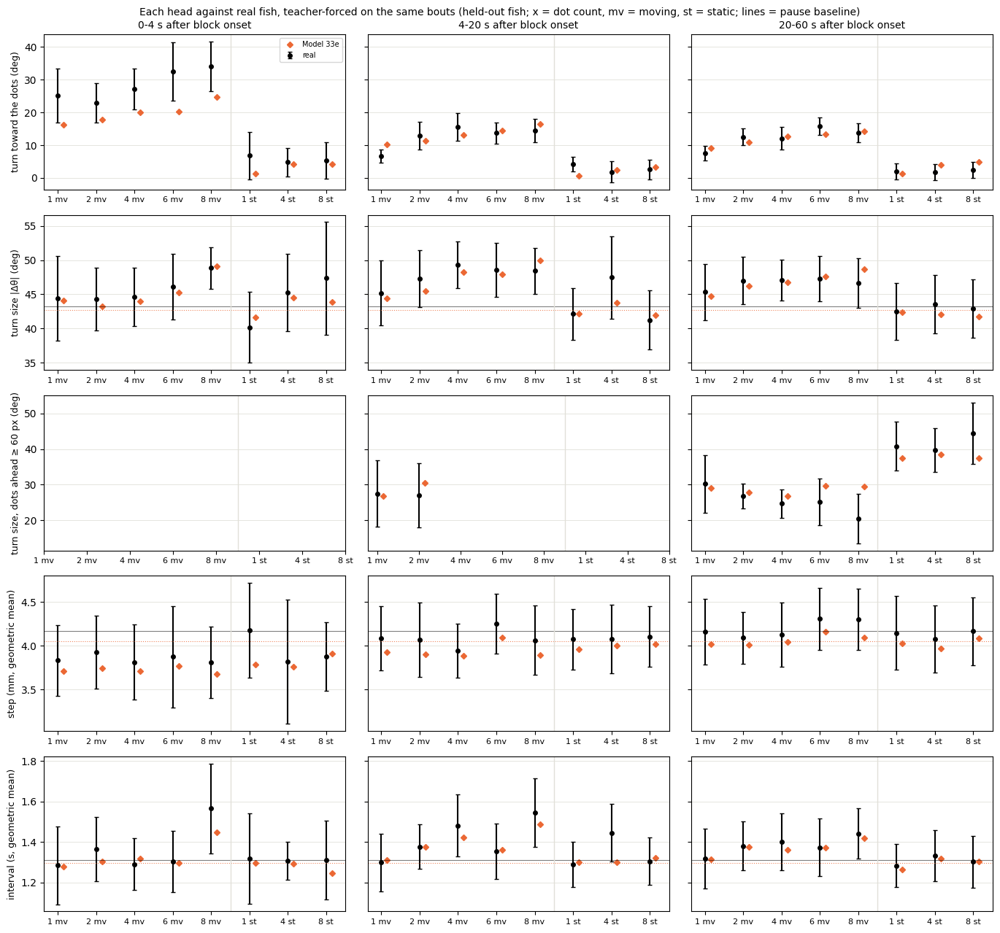

In [17]:
unit_eval.show('33e')

### M6-turn4, seed 101


== held-out likelihood per head (bits per bout)
turn             7.664
displacement     4.492
interval         1.213
joint           13.369

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h4'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h4.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h4.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h4.csv  (15 rows) in 1477s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h4_rej
abs_dtheta_w1                                        7.8373
symbol_js                                            0.0111
dt

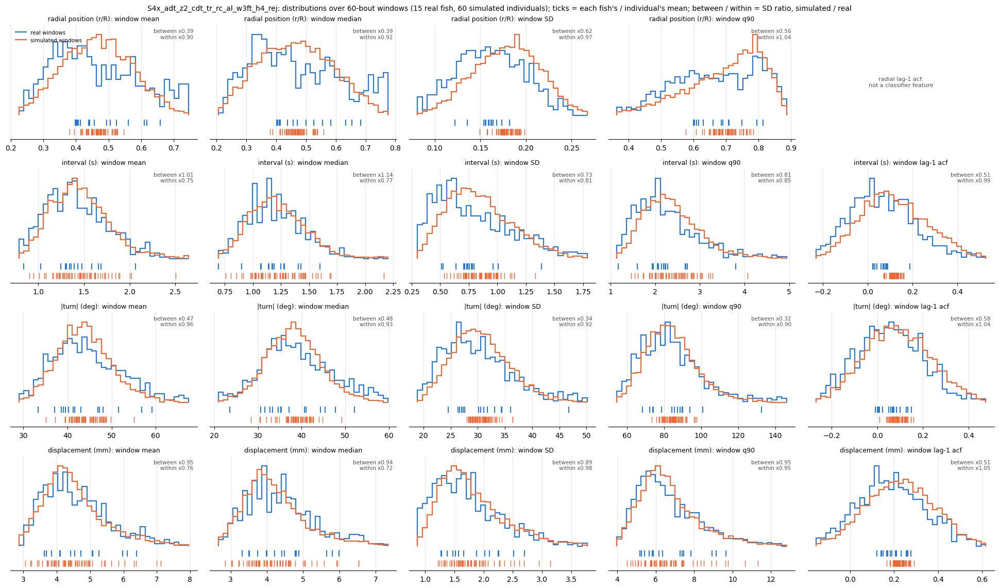


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h4_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.14     1.46  0.15  1.06   3.0   5.0                  22.3 +/- 0.9  20.6 +/- 0.9
d2s3.5    1.69     1.41  2.64   2.3  11.0   9.0                  17.4 +/- 0.9  18.8 +/- 0.6
d4s3.5    0.89     0.51  4.68  4.05  19.0  11.0                  18.7 +/- 1.7  18.1 +/- 0.6
d6s3.5    0.98     0.64  4.62  4.06  13.0  15.0                  16.7 +/- 1.3  16.2 +/- 0.7
d8s3.5    2.07     1.88  4.97  2.84  11.0   9.0                  16.3 +/- 1.0  17.7 +/- 1.1
d1s0     

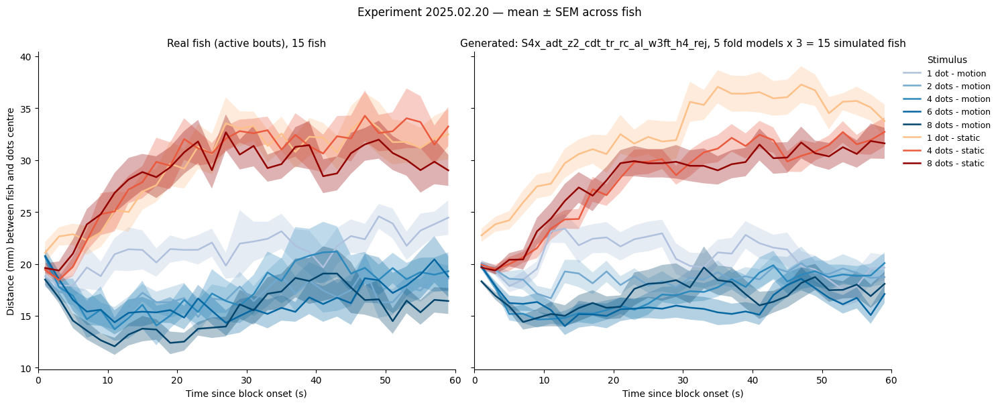


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

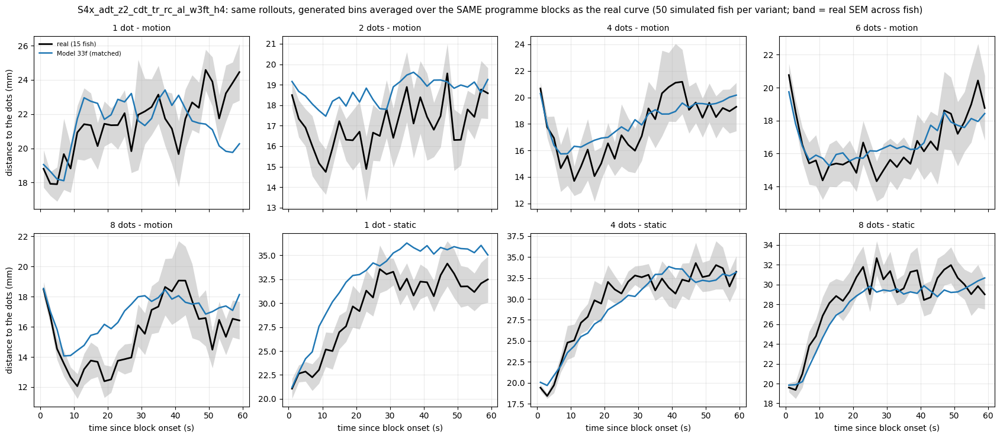


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h4                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.48  23.03       1.55
d2s3.5       17.39  23.58       6.19                           19.01  22.89       3.89
d4s3.5       18.74  23.93       5.19                           19.21  22.81       3.60
d6s3.5       16.69  23.12       6.43                           16.45  22.59       6.14
d8s3.5       16.41  23.36       6.94                           17.34  22.89       5.54

== turn toward the moving dots by dot count
           real  S4x_adt_z

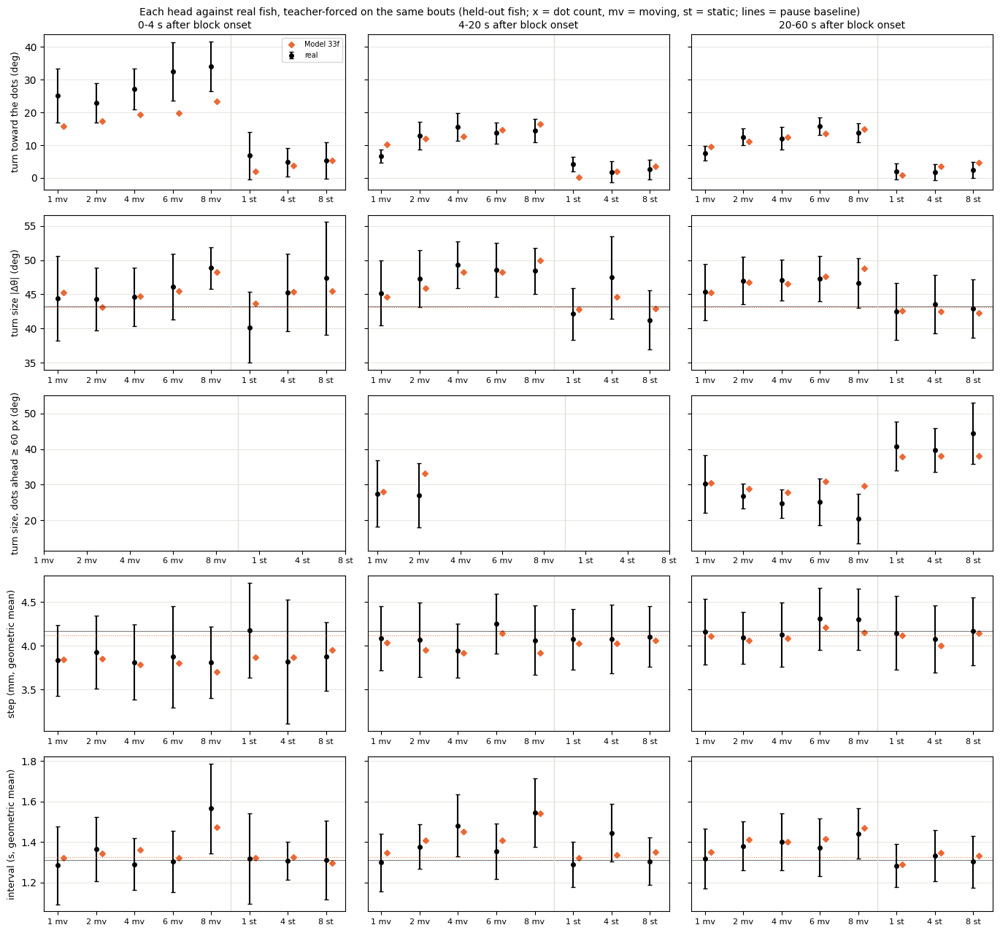

In [18]:
unit_eval.show('33f')

### M6-turn3, seed 0


== held-out likelihood per head (bits per bout)
turn             7.648
displacement     4.506
interval         1.222
joint           13.376

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h3'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h3.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h3.csv  (15 rows) in 850s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h3_rej
abs_dtheta_w1                                        8.1965
symbol_js                                            0.0101
dt_

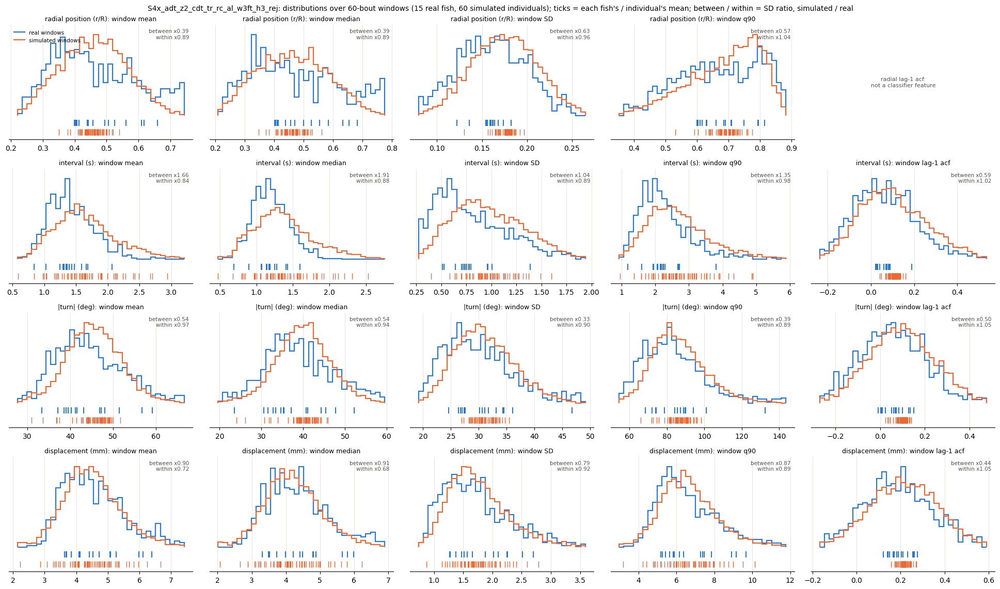


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h3_fold4.pt: 3 rollouts
dropped 10.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.69     1.16  0.15  0.52   3.0   5.0                  22.3 +/- 0.9  20.5 +/- 0.8
d2s3.5    1.17     0.97  2.64  4.28  11.0  15.0                  17.4 +/- 0.9  18.3 +/- 0.7
d4s3.5    1.72     0.95  4.68  3.82  19.0   9.0                  18.7 +/- 1.7  16.7 +/- 0.5
d6s3.5    1.20     0.79  4.62  4.78  13.0  15.0                  16.7 +/- 1.3  16.3 +/- 0.8
d8s3.5    1.84     1.20  4.97  4.99  11.0   9.0                  16.3 +/- 1.0  14.1 +/- 0.5
d1s0     

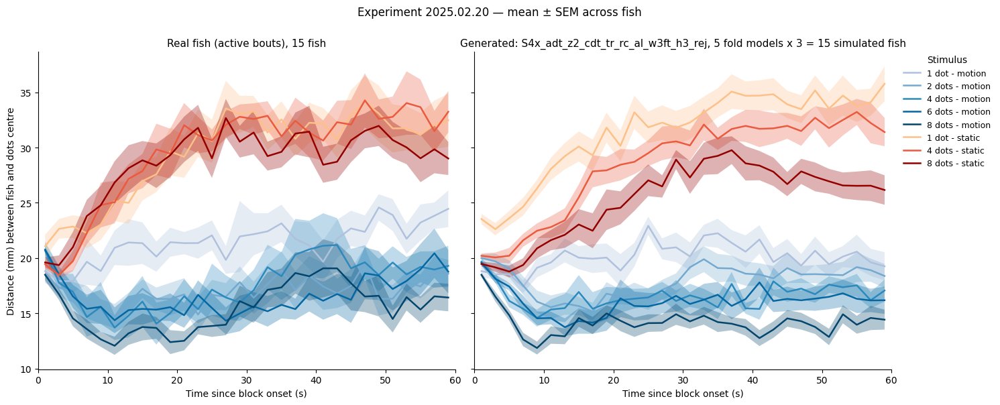


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

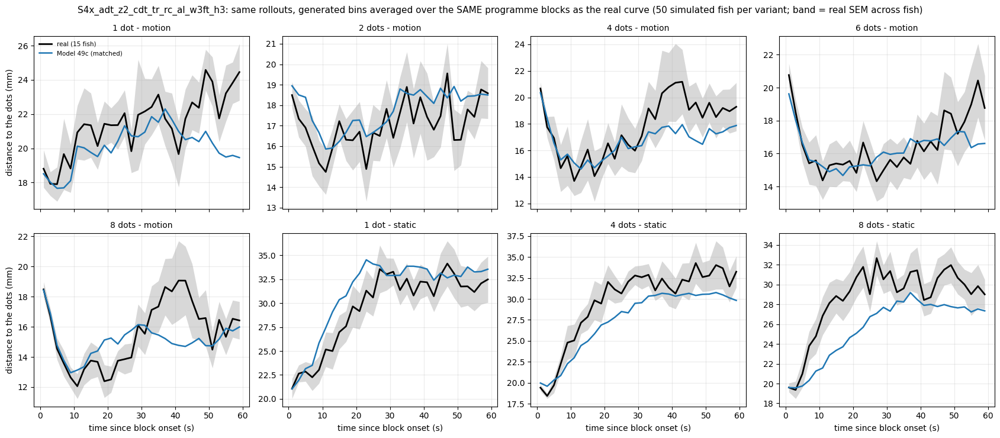


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h3                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           20.96  22.38       1.41
d2s3.5       17.39  23.58       6.19                           18.33  22.33       4.00
d4s3.5       18.74  23.93       5.19                           17.17  22.37       5.20
d6s3.5       16.69  23.12       6.43                           16.06  22.15       6.08
d8s3.5       16.41  23.36       6.94                           14.87  22.38       7.50

== turn toward the moving dots by dot count
           real  S4x_adt_z

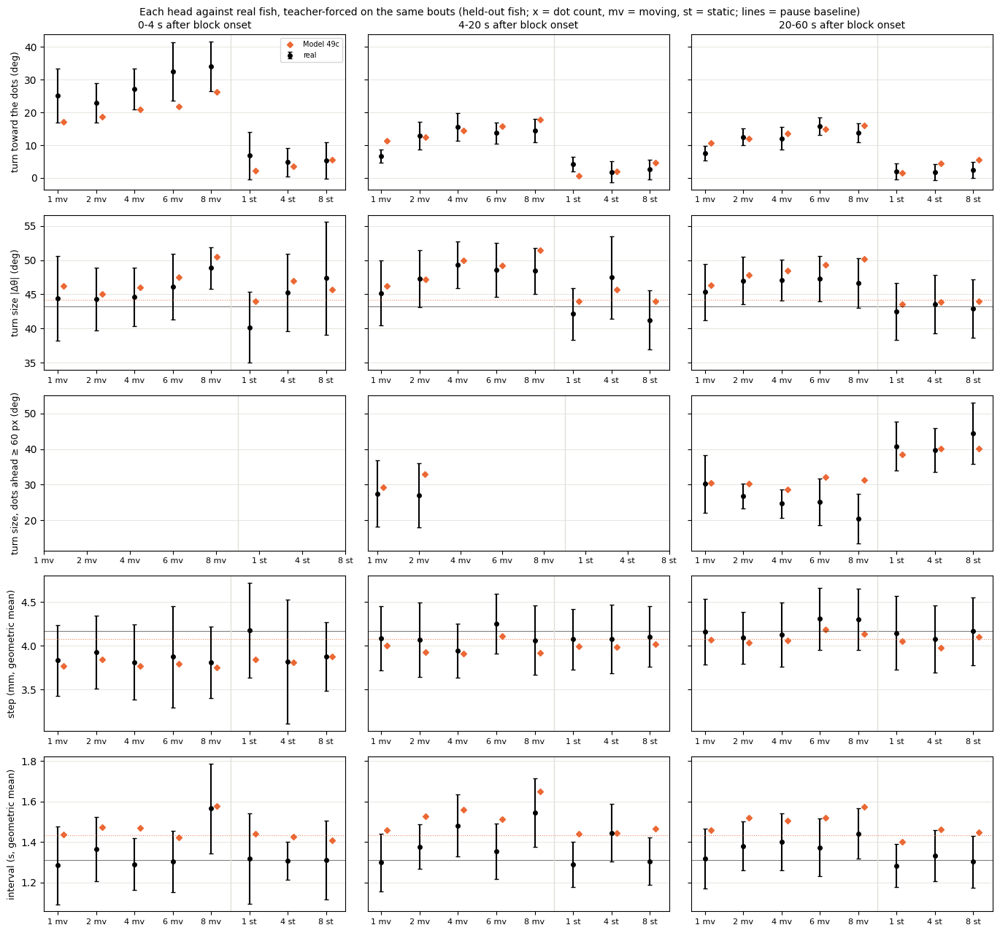

In [19]:
unit_eval.show('49c')

### M6-turn3, seed 101


== held-out likelihood per head (bits per bout)
turn             7.659
displacement     4.496
interval         1.216
joint           13.371

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h3'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h3.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h3.csv  (15 rows) in 784s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h3_rej
abs_dtheta_w1                                        8.1922
symbol_js                                            0.0115
dt_

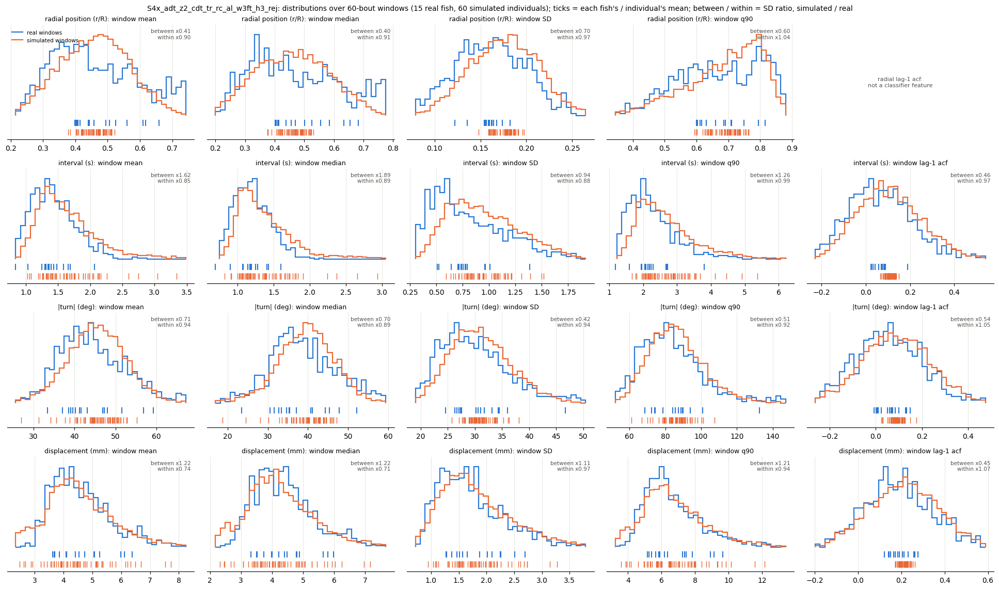


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h3_fold4.pt: 3 rollouts
dropped 12.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.59     1.01  0.15  1.21   3.0   5.0                  22.3 +/- 0.9  23.1 +/- 0.9
d2s3.5    2.27     1.71  2.64  1.89  11.0  11.0                  17.4 +/- 0.9  19.8 +/- 0.9
d4s3.5    1.73     1.05  4.68  3.48  19.0   9.0                  18.7 +/- 1.7  17.3 +/- 1.0
d6s3.5    1.50     1.13  4.62  2.19  13.0   7.0                  16.7 +/- 1.3  17.1 +/- 0.6
d8s3.5    1.81     1.59  4.97  1.66  11.0   5.0                  16.3 +/- 1.0  15.7 +/- 0.8
d1s0     

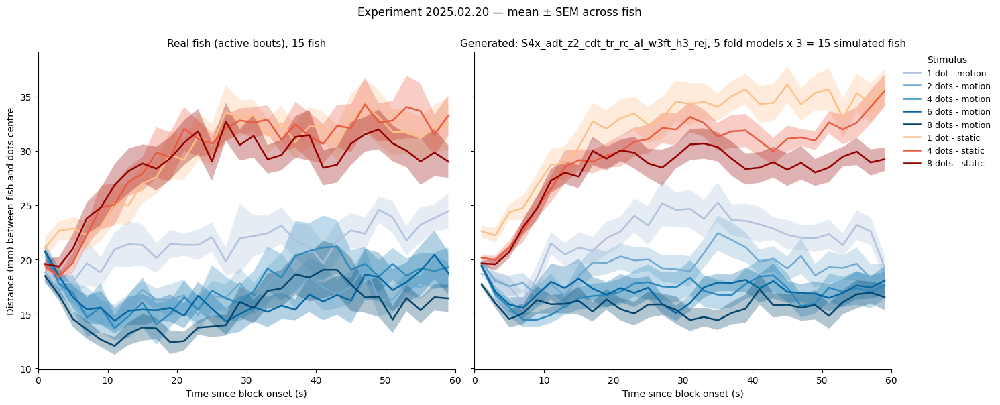


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

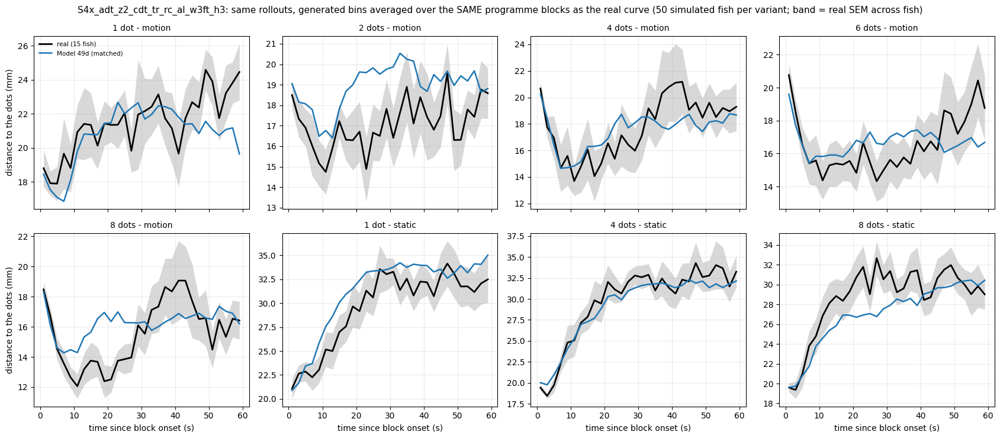


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h3                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.61  23.12       1.52
d2s3.5       17.39  23.58       6.19                           19.34  22.65       3.31
d4s3.5       18.74  23.93       5.19                           17.49  22.74       5.26
d6s3.5       16.69  23.12       6.43                           16.69  22.64       5.95
d8s3.5       16.41  23.36       6.94                           16.08  22.77       6.69

== turn toward the moving dots by dot count
           real  S4x_adt_z

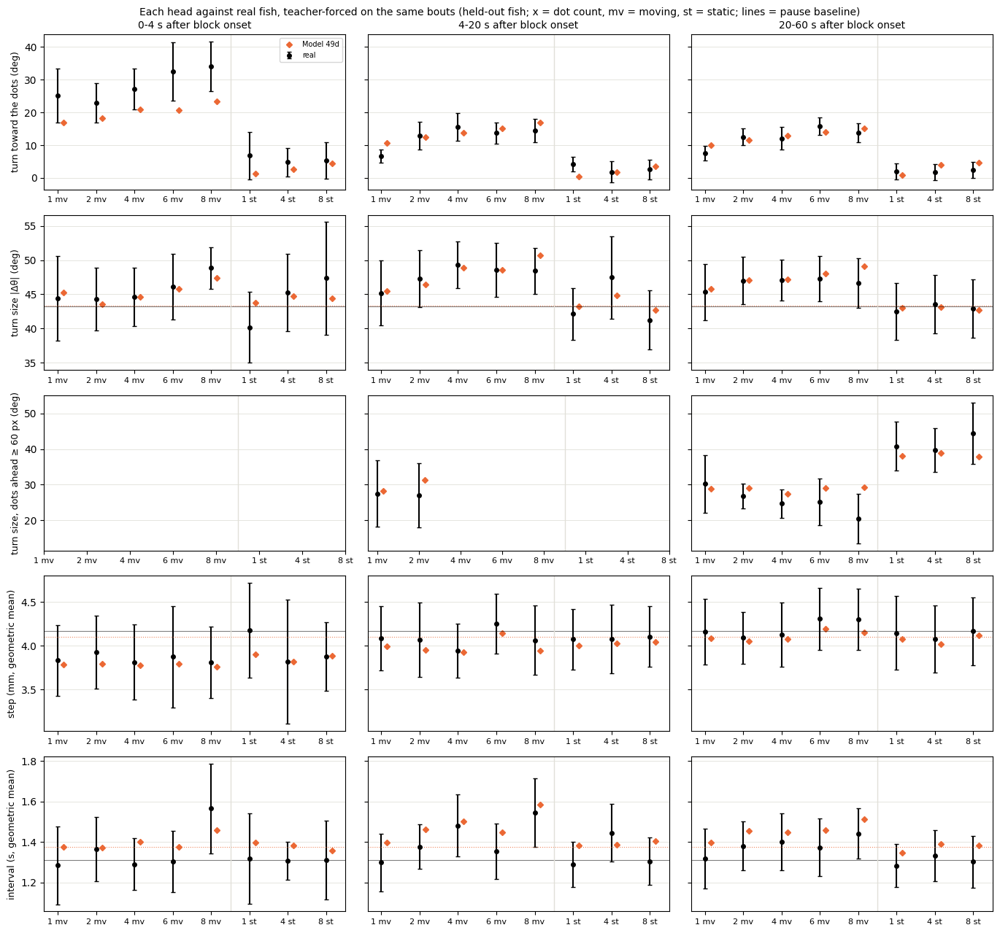

In [20]:
unit_eval.show('49d')

### M6-turn1, seed 0


== held-out likelihood per head (bits per bout)
turn             7.661
displacement     4.489
interval         1.212
joint           13.363

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h1'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h1.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h1.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h1.csv  (15 rows) in 463s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h1_rej
abs_dtheta_w1                                        7.7788
symbol_js                                            0.0090
dt_

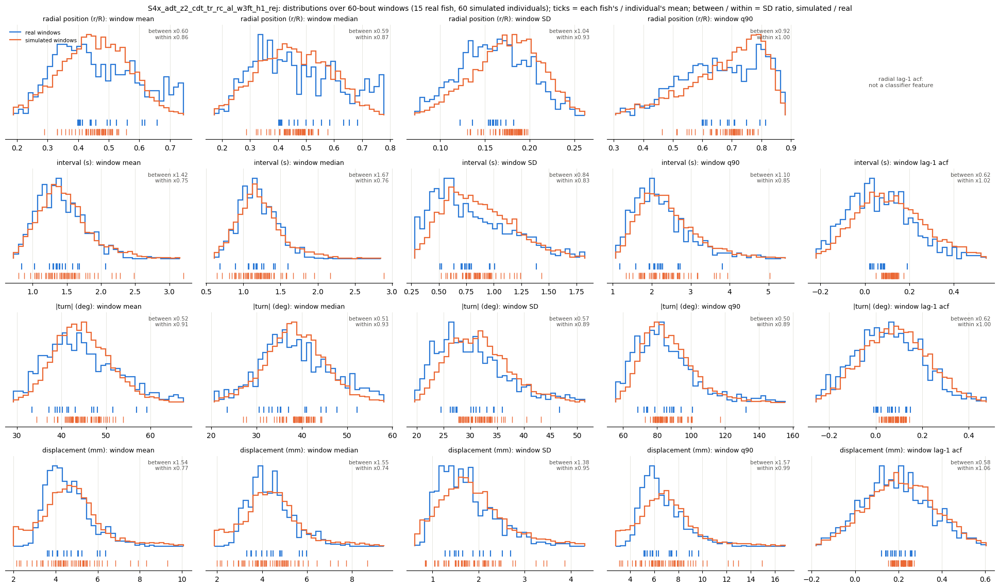


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h1_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.71     1.14  0.15  0.79   3.0   5.0                  22.3 +/- 0.9  20.7 +/- 1.0
d2s3.5    2.32     1.80  2.64   2.8  11.0  19.0                  17.4 +/- 0.9  20.0 +/- 0.8
d4s3.5    1.29     0.80  4.68  2.81  19.0   7.0                  18.7 +/- 1.7  18.1 +/- 1.1
d6s3.5    1.42     0.93  4.62  3.78  13.0   9.0                  16.7 +/- 1.3  16.6 +/- 0.8
d8s3.5    1.30     1.06  4.97  4.09  11.0  11.0                  16.3 +/- 1.0  15.7 +/- 0.7
d1s0     

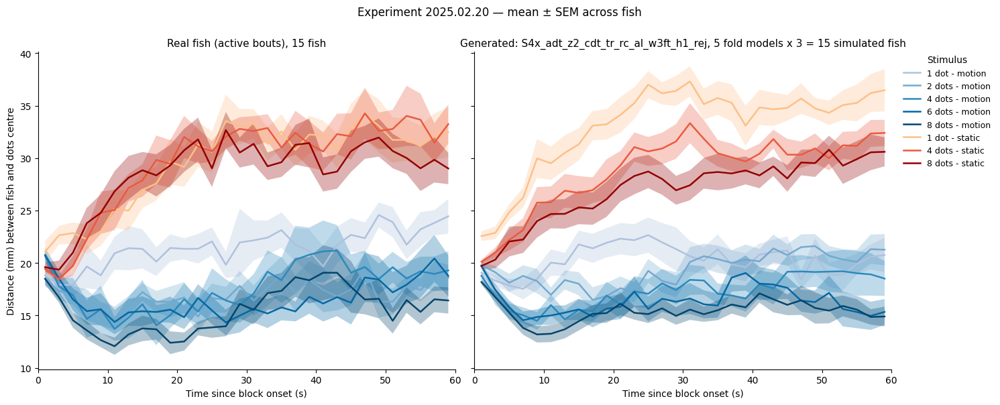


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

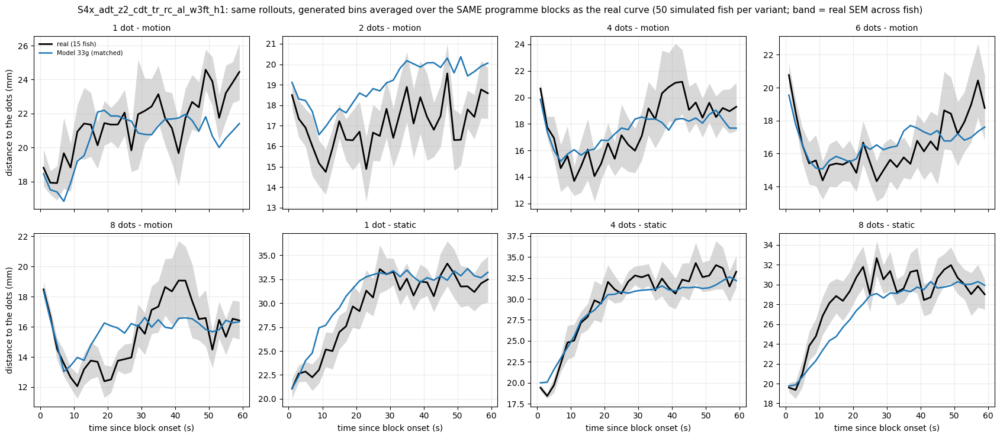


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h1                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.52  22.68       1.16
d2s3.5       17.39  23.58       6.19                           20.10  22.61       2.51
d4s3.5       18.74  23.93       5.19                           18.08  22.68       4.60
d6s3.5       16.69  23.12       6.43                           17.32  22.68       5.37
d8s3.5       16.41  23.36       6.94                           16.00  22.62       6.62

== turn toward the moving dots by dot count
           real  S4x_adt_z

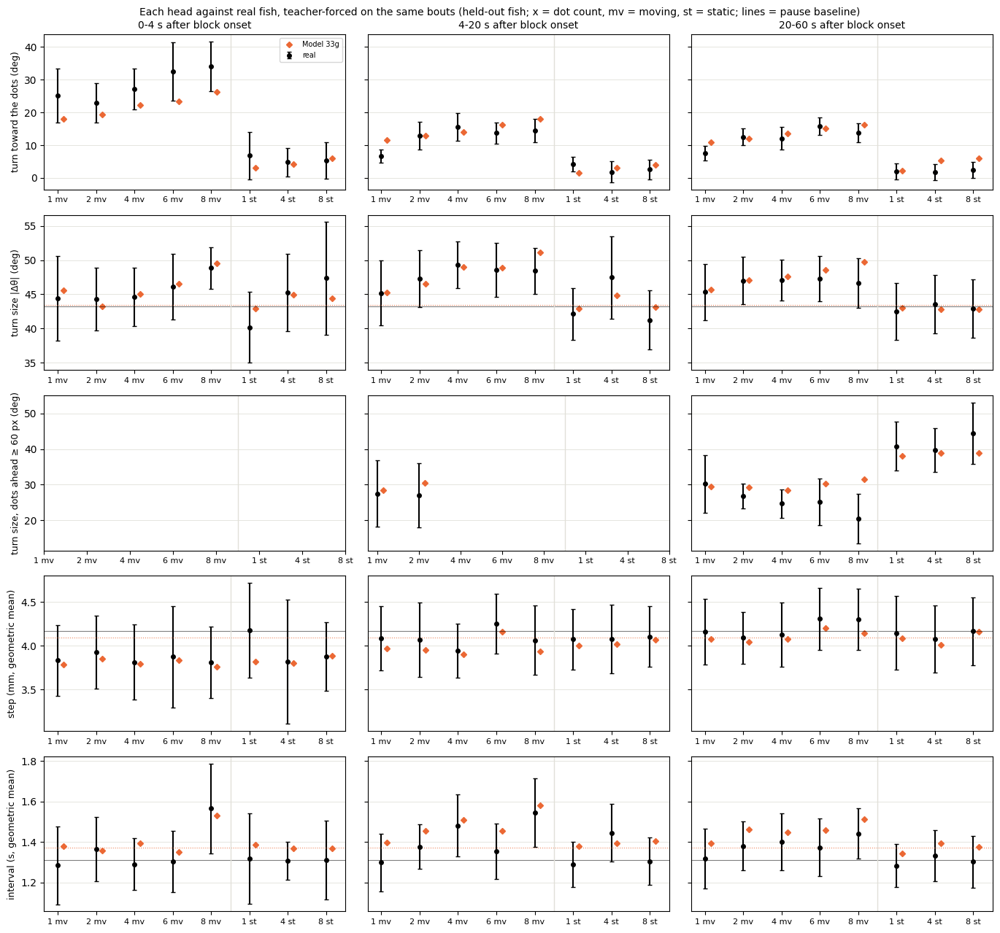

In [21]:
unit_eval.show('33g')

### M6-turn1, seed 101


== held-out likelihood per head (bits per bout)
turn             7.662
displacement     4.478
interval         1.235
joint           13.376

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h1'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h1.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h1.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h1.csv  (15 rows) in 546s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h1_rej
abs_dtheta_w1                                        8.1907
symbol_js                                            0.0135
dt_

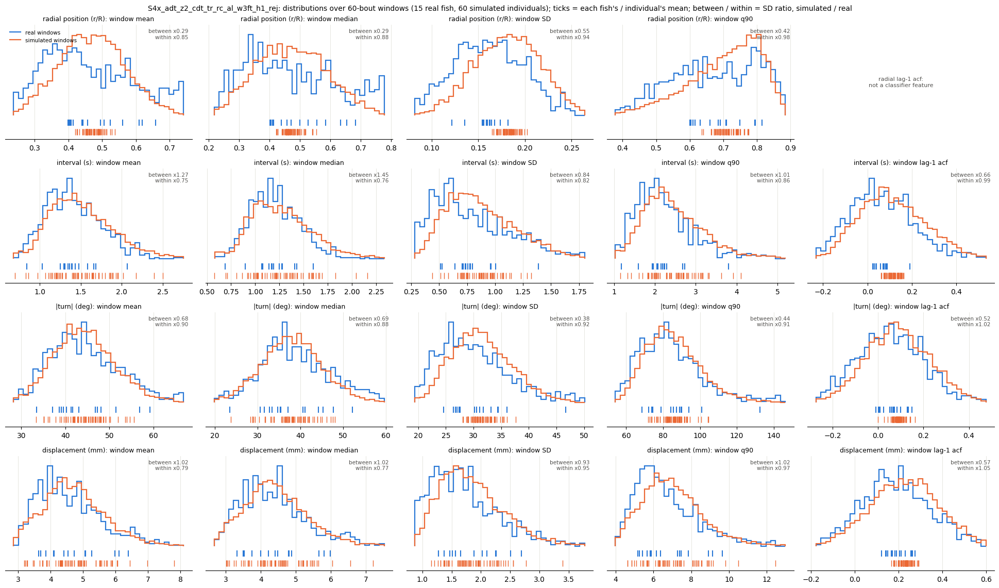


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h1_fold4.pt: 3 rollouts
dropped 10.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.59     1.10  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  22.5 +/- 0.7
d2s3.5    1.88     1.43  2.64  2.59  11.0  11.0                  17.4 +/- 0.9  19.3 +/- 0.7
d4s3.5    1.41     0.75  4.68  4.32  19.0  15.0                  18.7 +/- 1.7  18.3 +/- 1.1
d6s3.5    1.30     0.82  4.62  5.35  13.0  11.0                  16.7 +/- 1.3  15.7 +/- 0.7
d8s3.5    1.69     1.55  4.97  2.64  11.0   9.0                  16.3 +/- 1.0  16.7 +/- 0.8
d1s0     

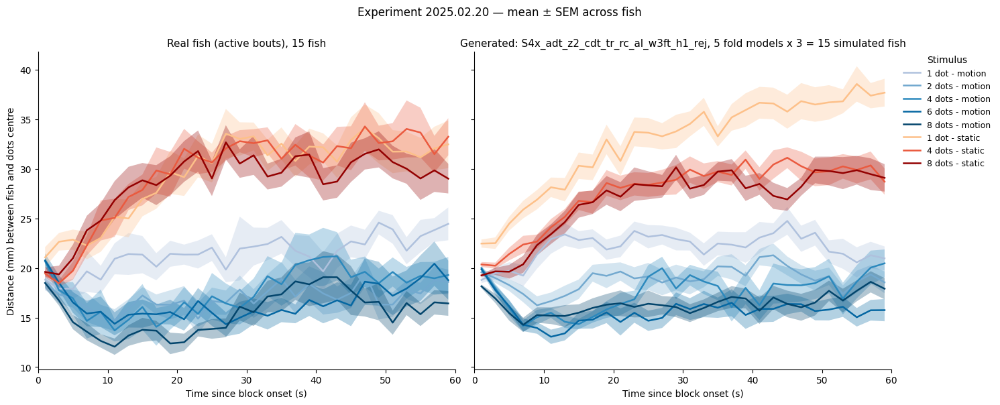


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

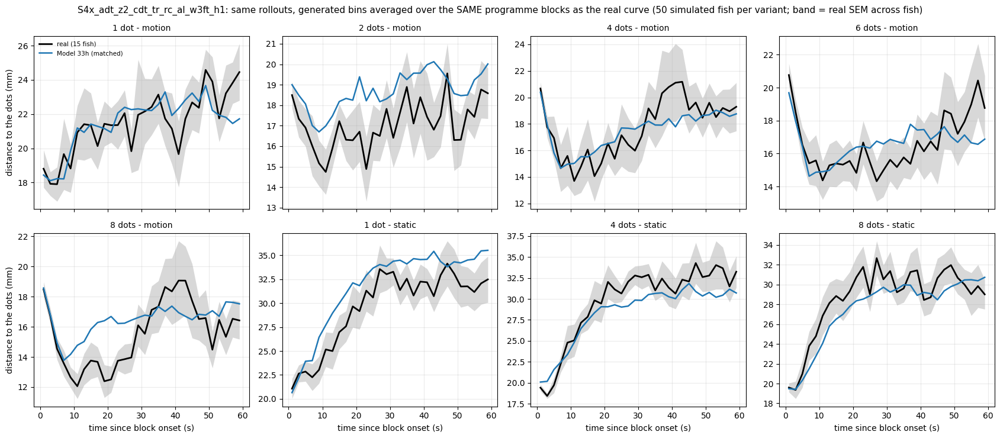


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h1                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.71  23.22       0.51
d2s3.5       17.39  23.58       6.19                           19.57  22.91       3.34
d4s3.5       18.74  23.93       5.19                           18.10  22.84       4.73
d6s3.5       16.69  23.12       6.43                           16.94  22.66       5.72
d8s3.5       16.41  23.36       6.94                           16.53  22.77       6.24

== turn toward the moving dots by dot count
           real  S4x_adt_z

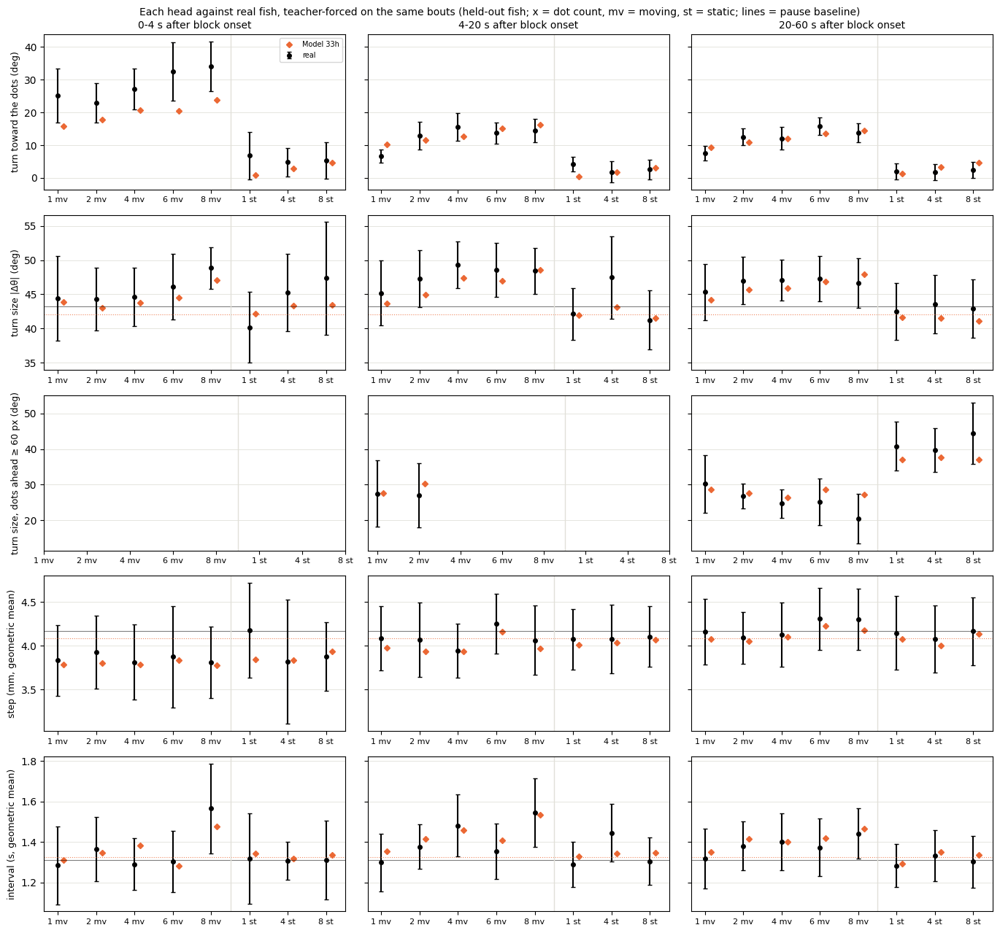

In [22]:
unit_eval.show('33h')

### M6-turn0, seed 0


== held-out likelihood per head (bits per bout)
turn             7.668
displacement     4.505
interval         1.211
joint           13.384

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h0'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h0.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h0.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h0.csv  (15 rows) in 768s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h0_rej
abs_dtheta_w1                                        7.1678
symbol_js                                            0.0083
dt_

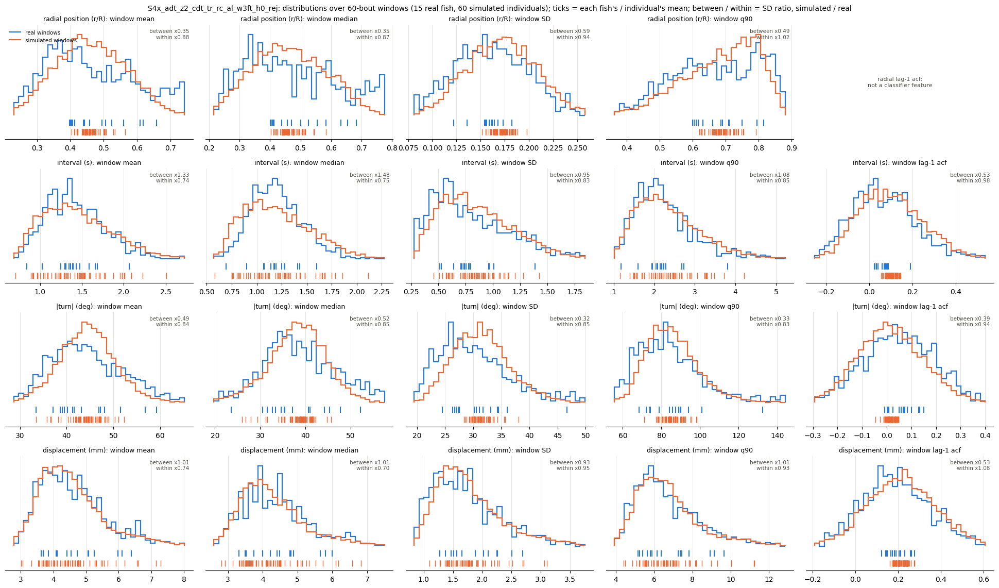


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h0_fold4.pt: 3 rollouts
dropped 10.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.73     1.16  0.15  1.22   3.0   5.0                  22.3 +/- 0.9  20.6 +/- 0.7
d2s3.5    1.37     1.05  2.64  2.24  11.0   9.0                  17.4 +/- 0.9  18.8 +/- 0.7
d4s3.5    2.28     1.31  4.68  4.57  19.0   9.0                  18.7 +/- 1.7  15.8 +/- 0.5
d6s3.5    1.36     1.01  4.62   3.4  13.0   9.0                  16.7 +/- 1.3  17.6 +/- 1.0
d8s3.5    1.50     1.43  4.97  2.24  11.0   7.0                  16.3 +/- 1.0  16.8 +/- 0.4
d1s0     

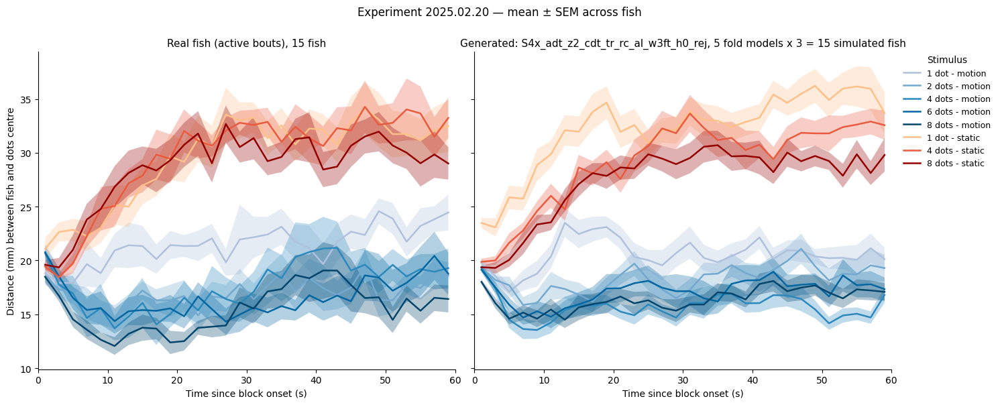


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

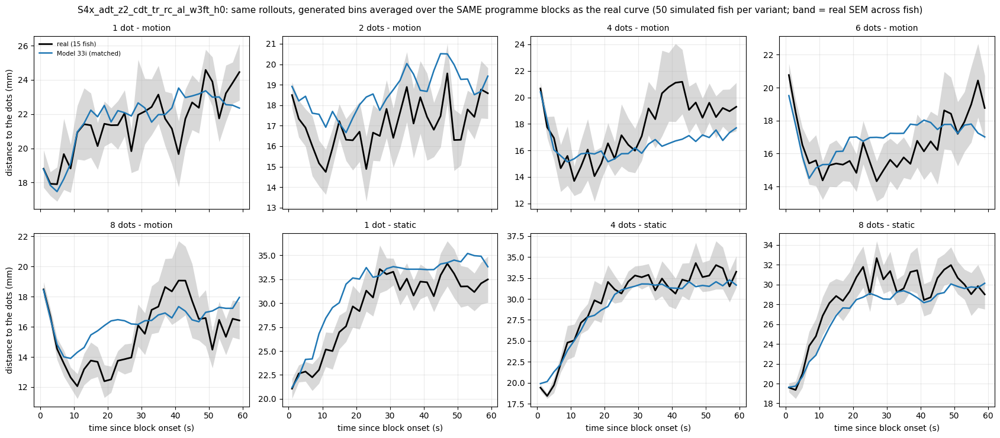


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h0                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.44  22.83       0.40
d2s3.5       17.39  23.58       6.19                           19.55  22.75       3.20
d4s3.5       18.74  23.93       5.19                           16.99  22.67       5.68
d6s3.5       16.69  23.12       6.43                           17.46  22.88       5.41
d8s3.5       16.41  23.36       6.94                           17.16  22.66       5.50

== turn toward the moving dots by dot count
           real  S4x_adt_z

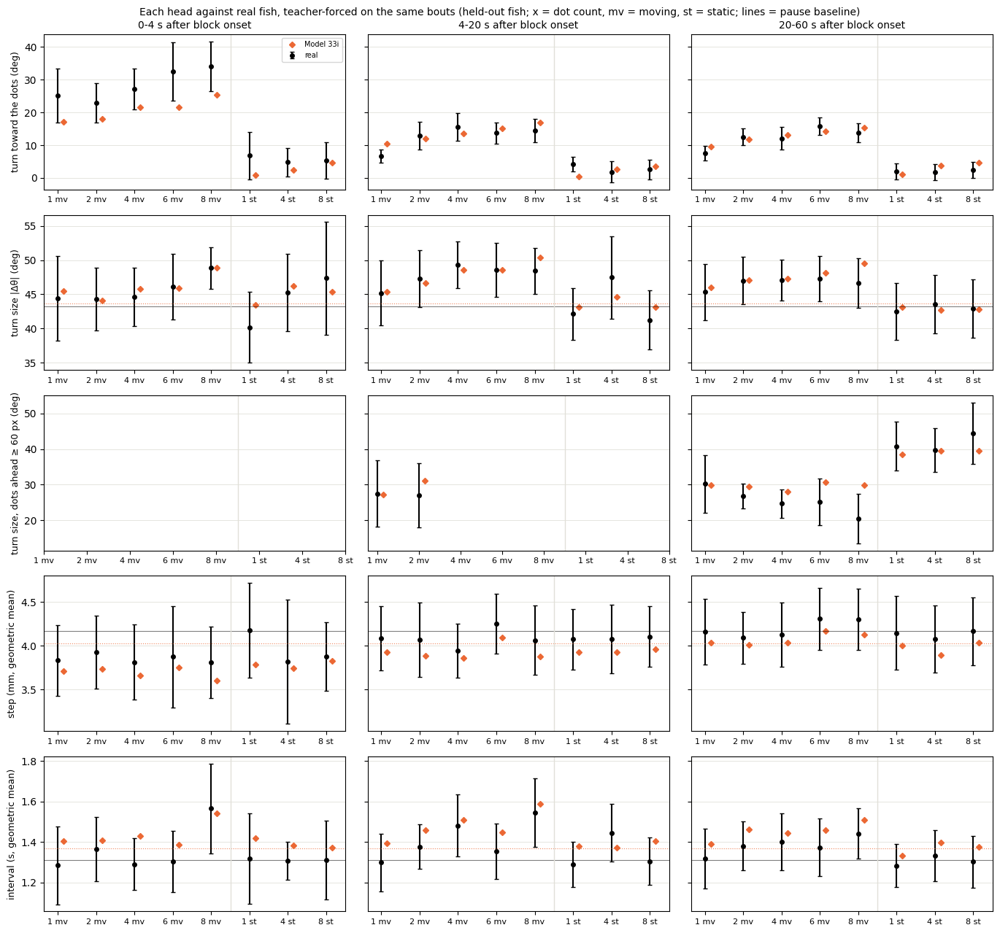

In [23]:
unit_eval.show('33i')

### M6-turn0, seed 101


== held-out likelihood per head (bits per bout)
turn             7.690
displacement     4.502
interval         1.245
joint           13.438

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_h0'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h0.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h0.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_h0.csv  (15 rows) in 682s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_h0_rej
abs_dtheta_w1                                        7.1415
symbol_js                                            0.0090
dt_

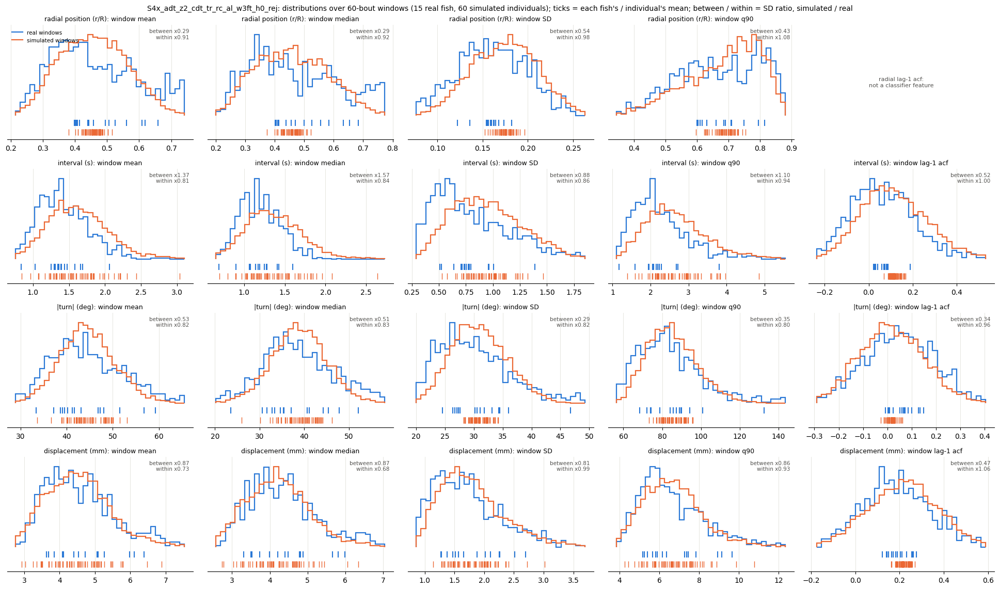


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_h0_fold4.pt: 3 rollouts
dropped 10.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.52     1.06  0.15  0.47   3.0   5.0                  22.3 +/- 0.9  20.8 +/- 0.8
d2s3.5    1.52     1.20  2.64  2.55  11.0   9.0                  17.4 +/- 0.9  18.8 +/- 0.8
d4s3.5    1.64     0.97  4.68   4.6  19.0   9.0                  18.7 +/- 1.7  18.6 +/- 0.9
d6s3.5    1.85     1.33  4.62  2.94  13.0   7.0                  16.7 +/- 1.3  17.6 +/- 1.0
d8s3.5    1.72     1.69  4.97  2.06  11.0   9.0                  16.3 +/- 1.0  17.2 +/- 0.8
d1s0     

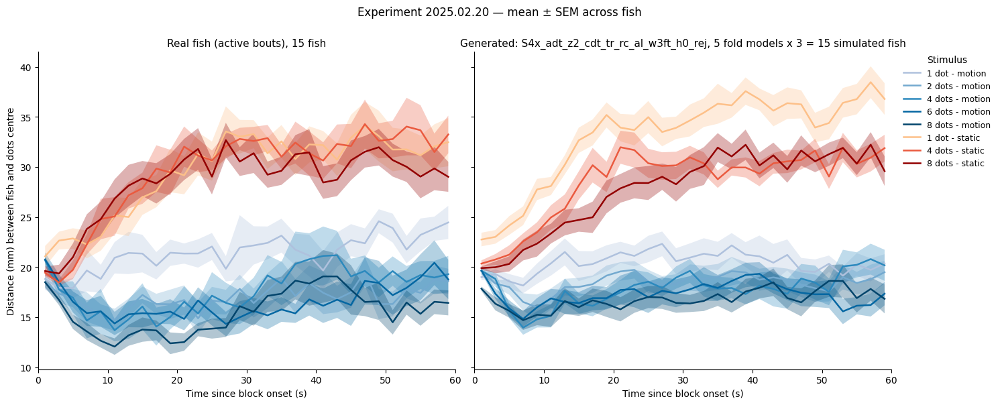


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

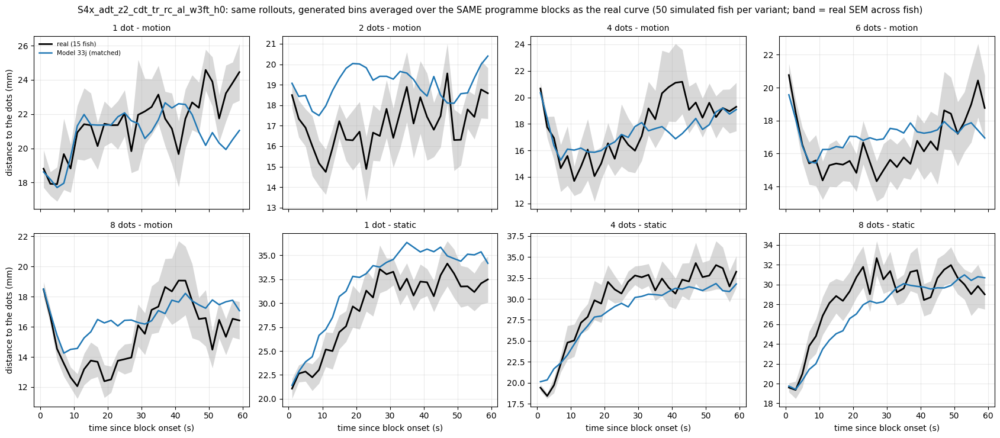


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_h0                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           20.98  22.54       1.56
d2s3.5       17.39  23.58       6.19                           18.70  22.54       3.84
d4s3.5       18.74  23.93       5.19                           18.20  22.67       4.47
d6s3.5       16.69  23.12       6.43                           17.44  22.38       4.94
d8s3.5       16.41  23.36       6.94                           16.84  22.54       5.70

== turn toward the moving dots by dot count
           real  S4x_adt_z

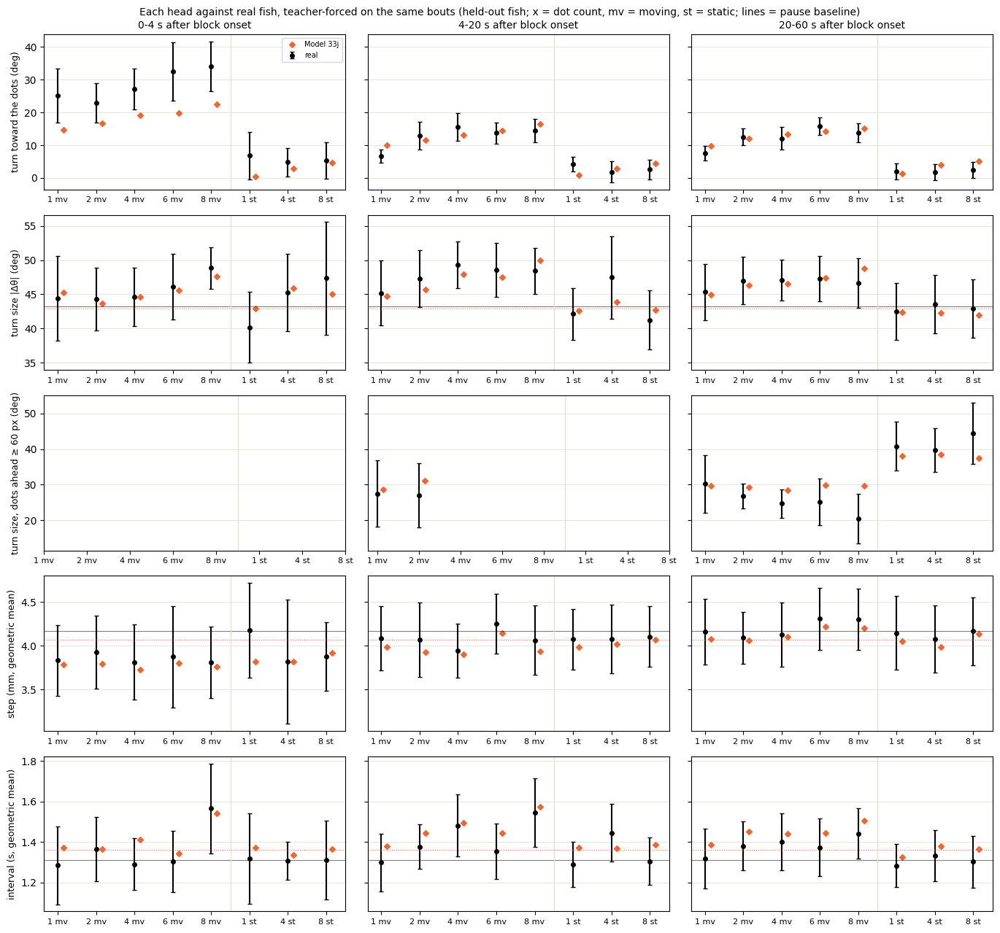

In [24]:
unit_eval.show('33j')

### M6-kin5, seed 0


== held-out likelihood per head (bits per bout)
turn             7.661
displacement     4.509
interval         1.224
joint           13.394

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5.csv  (15 rows) in 1003s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5_rej
abs_dtheta_w1                                         7.9102
symbol_js                                             0.

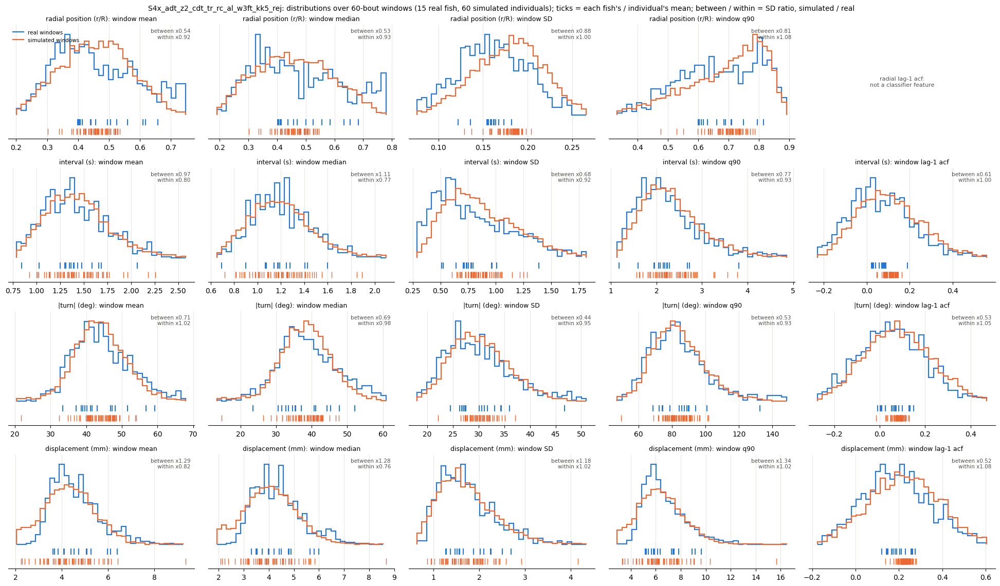


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5_fold4.pt: 3 rollouts
dropped 11.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.85     1.33  0.15  0.06   3.0   5.0                  22.3 +/- 0.9  21.9 +/- 1.0
d2s3.5    2.49     1.95  2.64  2.07  11.0   9.0                  17.4 +/- 0.9  20.1 +/- 0.9
d4s3.5    1.01     0.60  4.68  4.97  19.0  11.0                  18.7 +/- 1.7  18.4 +/- 0.6
d6s3.5    1.43     1.06  4.62  2.66  13.0   7.0                  16.7 +/- 1.3  17.6 +/- 0.9
d8s3.5    2.34     2.06  4.97  2.11  11.0   9.0                  16.3 +/- 1.0  17.3 +/- 0.8
d1s0    

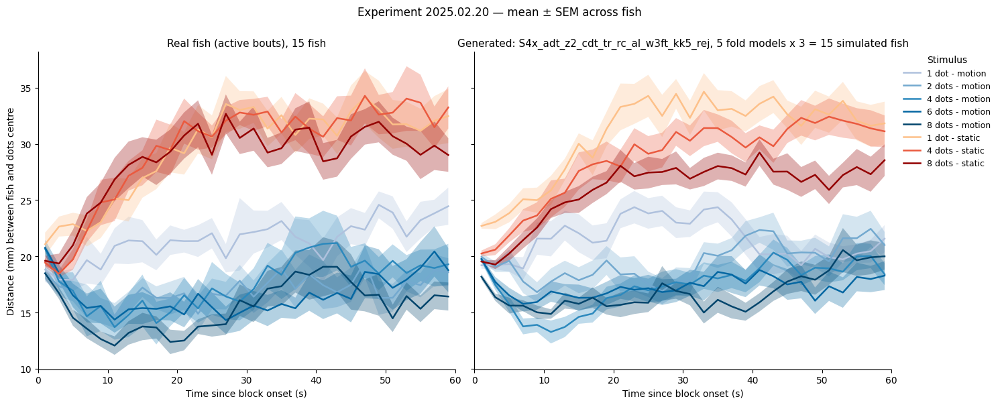


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

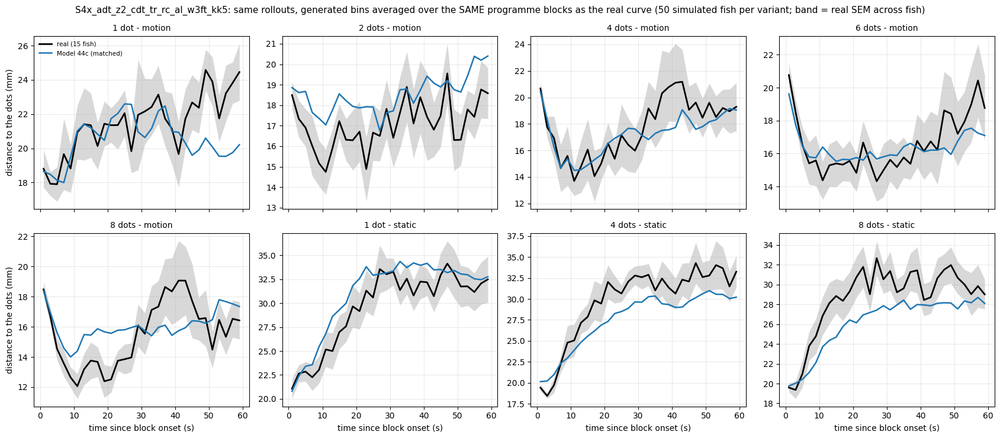


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            21.47  22.24       0.77
d2s3.5       17.39  23.58       6.19                            19.16  22.34       3.17
d4s3.5       18.74  23.93       5.19                            18.06  22.25       4.19
d6s3.5       16.69  23.12       6.43                            16.68  22.07       5.39
d8s3.5       16.41  23.36       6.94                            16.54  22.27       5.73

== turn toward the moving dots by dot count
           real  S

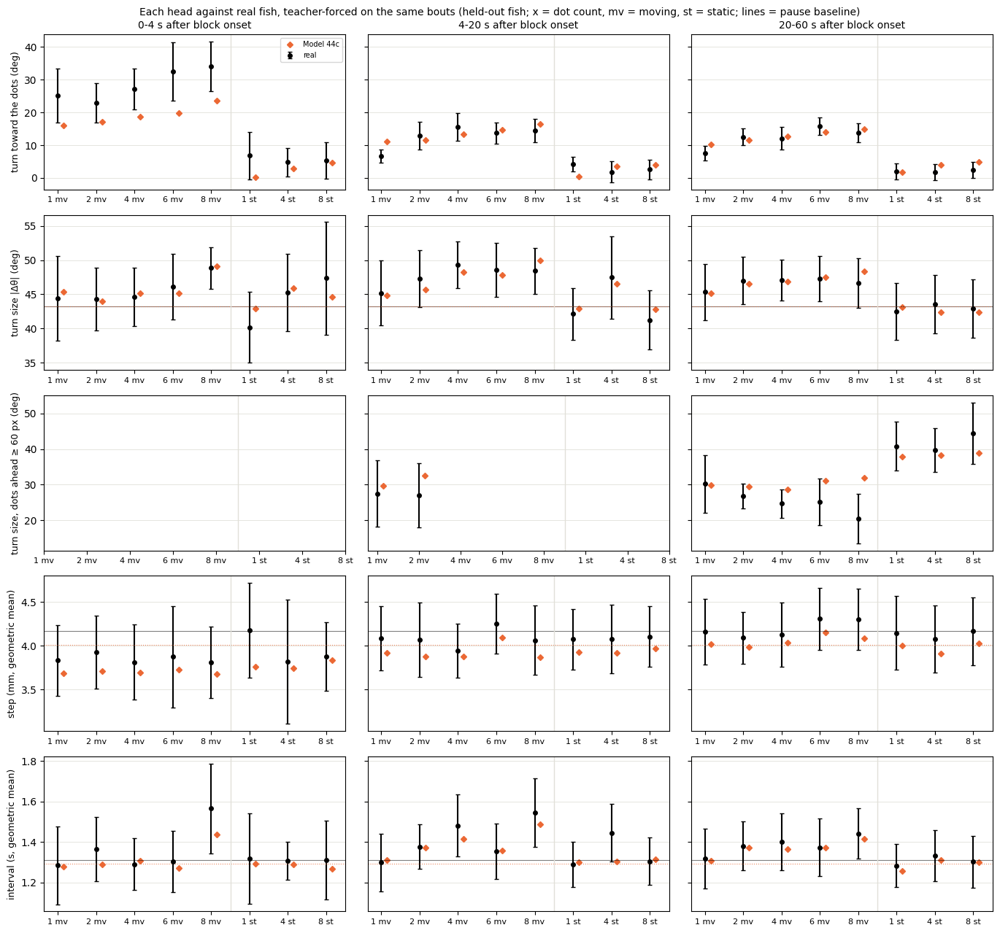

In [25]:
unit_eval.show('44c')

### M6-kin5, seed 101


== held-out likelihood per head (bits per bout)
turn             7.656
displacement     4.505
interval         1.223
joint           13.384

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5.csv  (15 rows) in 883s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5_rej
abs_dtheta_w1                                         8.0599
symbol_js                                             0.0

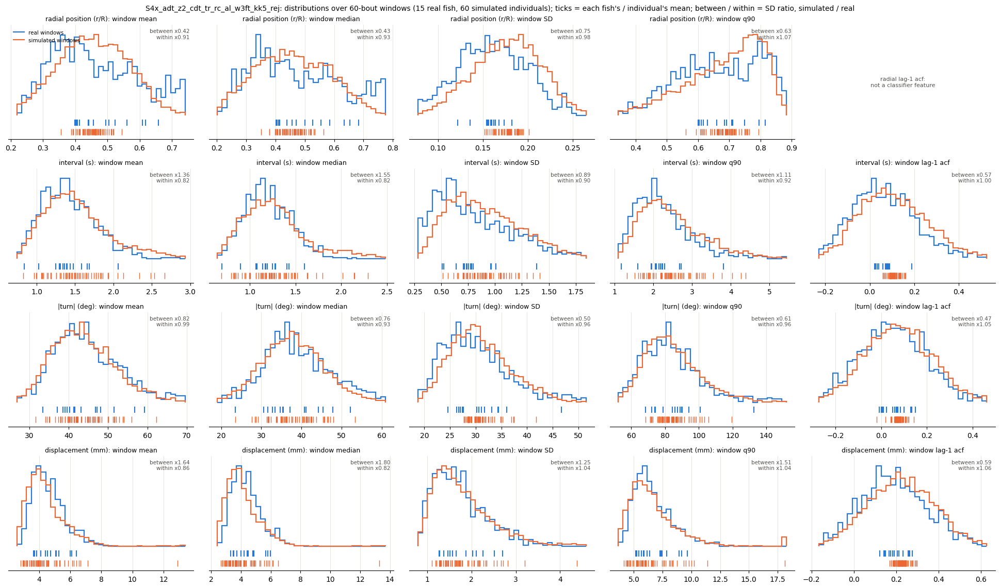


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.43     0.97  0.15  0.42   3.0   5.0                  22.3 +/- 0.9  21.9 +/- 0.9
d2s3.5    1.90     1.54  2.64  2.33  11.0  11.0                  17.4 +/- 0.9  19.0 +/- 1.5
d4s3.5    1.43     0.79  4.68  3.36  19.0  15.0                  18.7 +/- 1.7  17.3 +/- 0.9
d6s3.5    1.24     0.87  4.62  3.61  13.0   9.0                  16.7 +/- 1.3  17.3 +/- 1.2
d8s3.5    2.07     1.95  4.97  2.28  11.0   7.0                  16.3 +/- 1.0  17.2 +/- 0.8
d1s0    

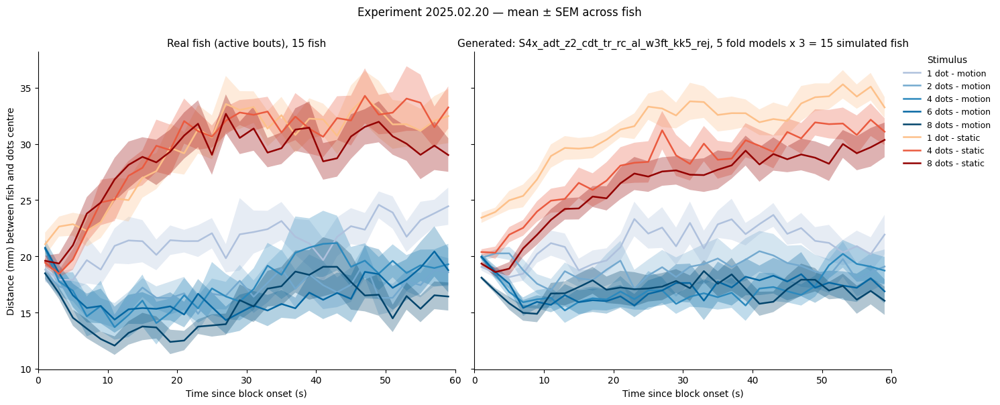


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

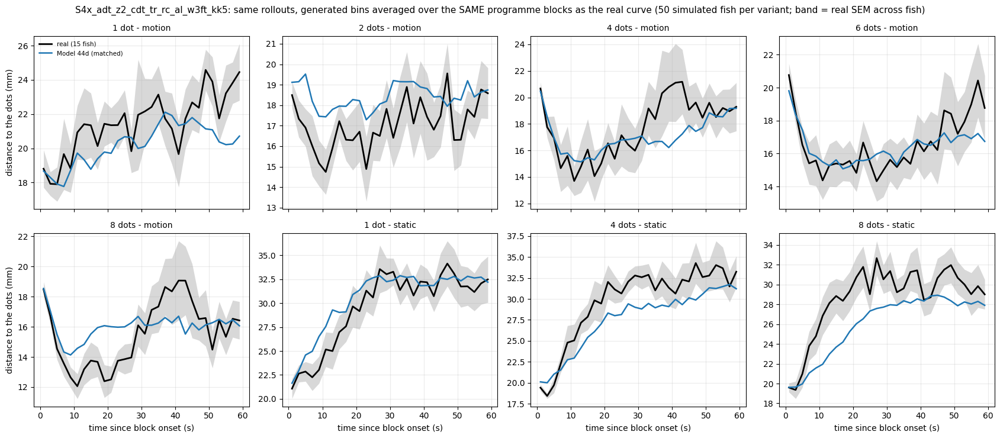


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk5                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            21.17  22.22       1.06
d2s3.5       17.39  23.58       6.19                            18.42  22.04       3.62
d4s3.5       18.74  23.93       5.19                            17.83  22.00       4.17
d6s3.5       16.69  23.12       6.43                            16.40  22.10       5.70
d8s3.5       16.41  23.36       6.94                            16.60  21.82       5.22

== turn toward the moving dots by dot count
           real  S

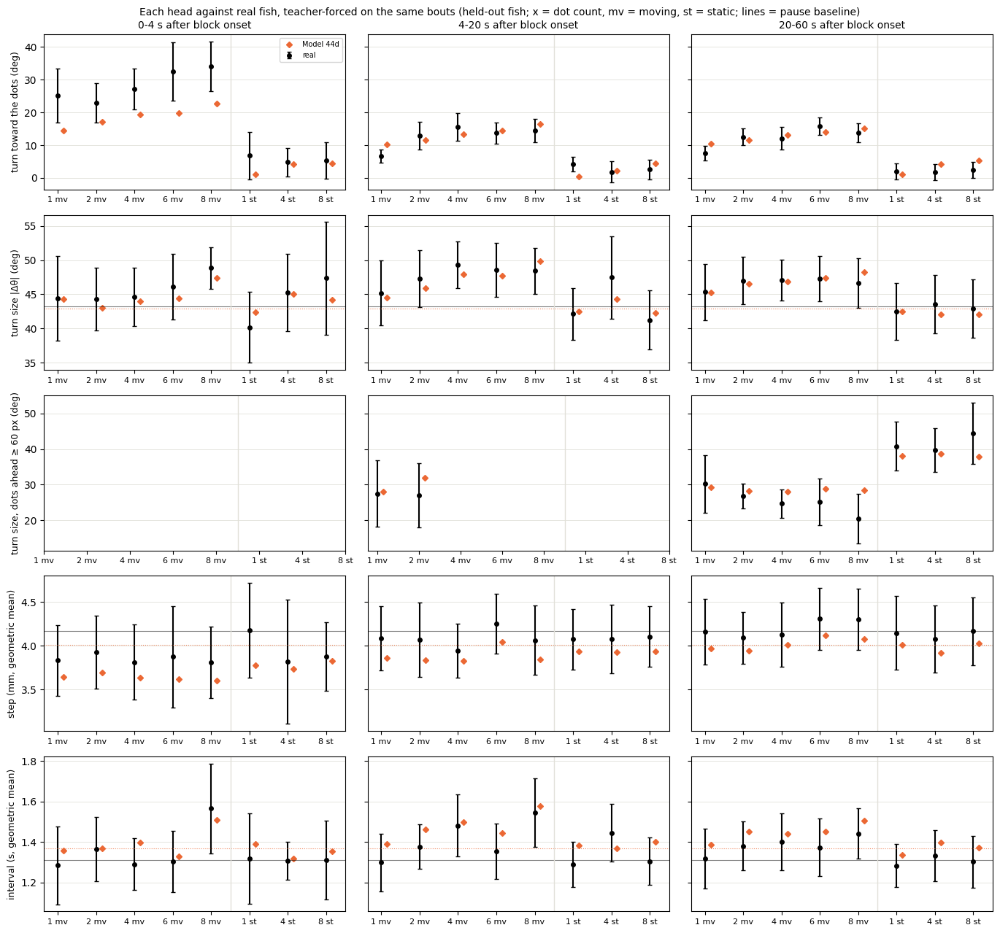

In [26]:
unit_eval.show('44d')

### M6-kin4, seed 0


== held-out likelihood per head (bits per bout)
turn             7.670
displacement     4.521
interval         1.227
joint           13.418

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4.csv  (15 rows) in 1002s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4_rej
abs_dtheta_w1                                         8.0443
symbol_js                                             0.

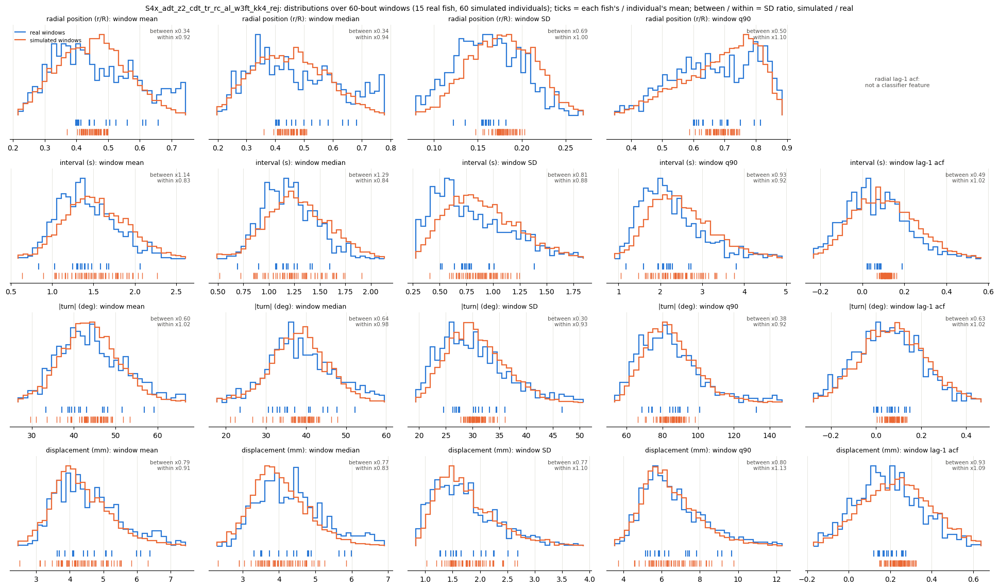


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4_fold4.pt: 3 rollouts
dropped 9.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.79     1.20  0.15  0.56   3.0   5.0                  22.3 +/- 0.9  20.3 +/- 0.6
d2s3.5    1.57     1.22  2.64  2.67  11.0  11.0                  17.4 +/- 0.9  19.0 +/- 0.6
d4s3.5    1.46     0.77  4.68  4.03  19.0  15.0                  18.7 +/- 1.7  17.1 +/- 0.6
d6s3.5    1.36     0.97  4.62  3.43  13.0   9.0                  16.7 +/- 1.3  17.2 +/- 0.7
d8s3.5    1.64     1.43  4.97  2.89  11.0  13.0                  16.3 +/- 1.0  16.4 +/- 0.7
d1s0     

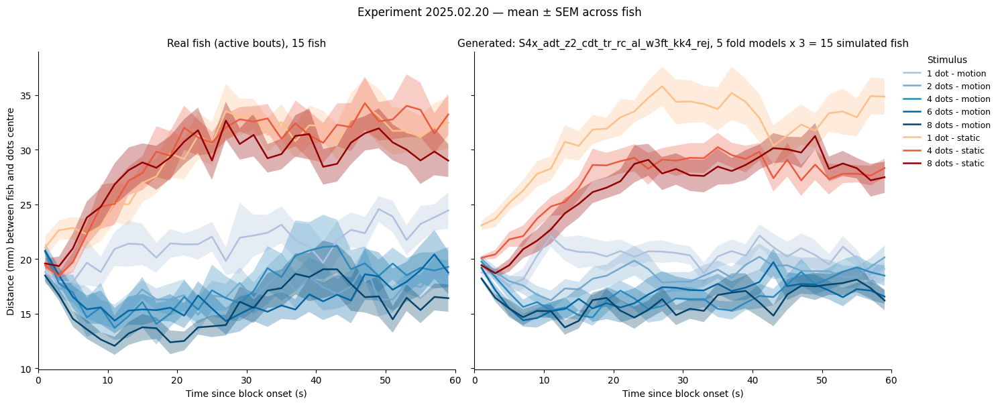


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

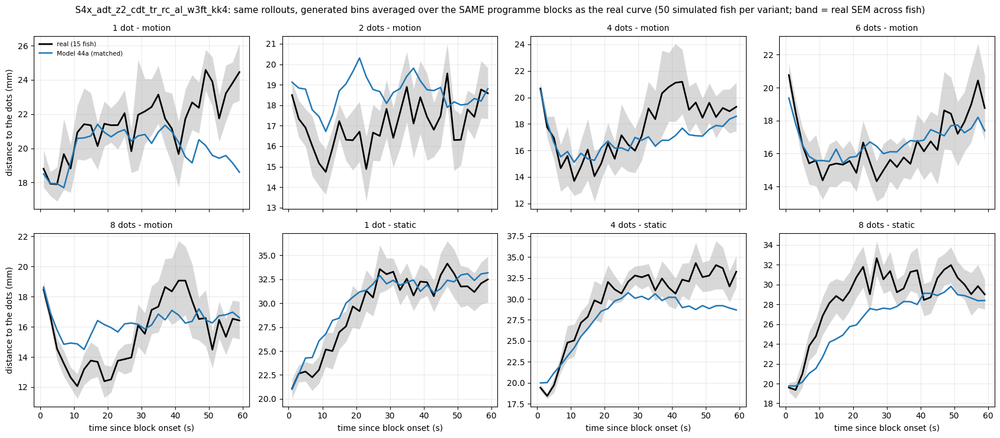


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            20.16  21.79       1.63
d2s3.5       17.39  23.58       6.19                            18.89  21.76       2.87
d4s3.5       18.74  23.93       5.19                            17.05  21.80       4.75
d6s3.5       16.69  23.12       6.43                            17.07  21.81       4.74
d8s3.5       16.41  23.36       6.94                            16.21  21.70       5.49

== turn toward the moving dots by dot count
           real  S

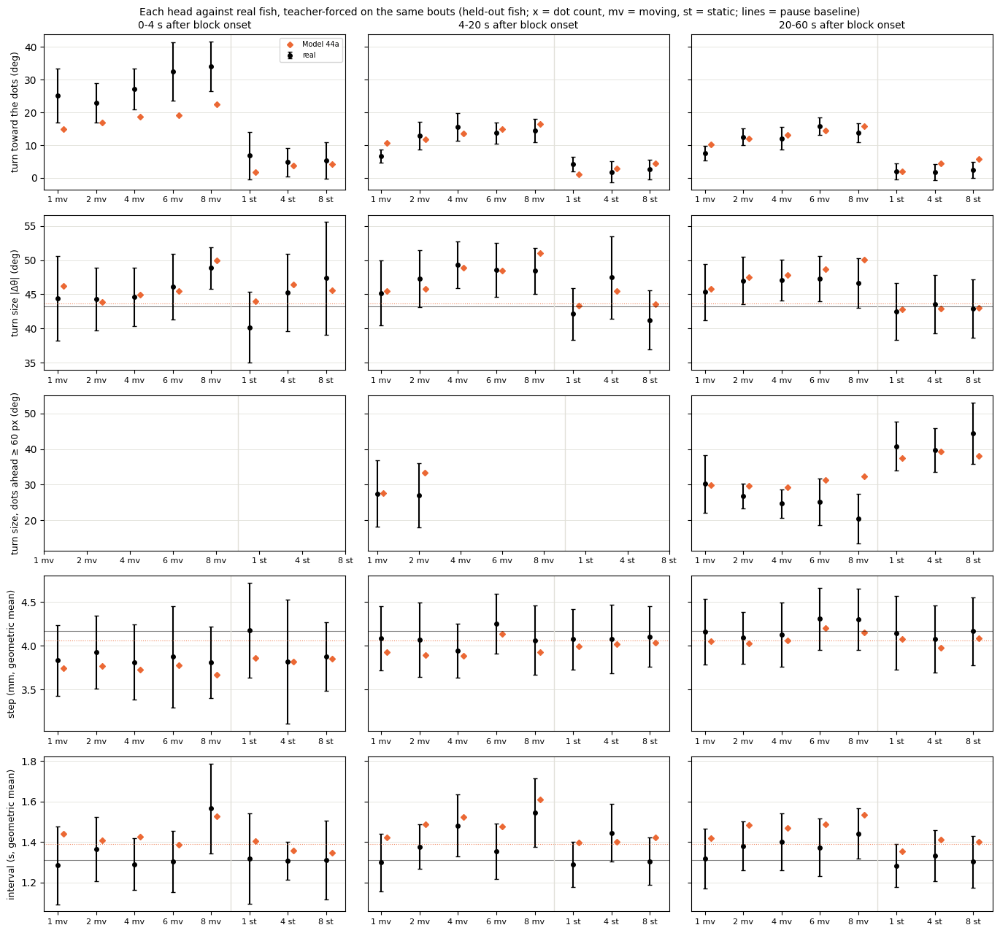

In [27]:
unit_eval.show('44a')

### M6-kin4, seed 101


== held-out likelihood per head (bits per bout)
turn             7.650
displacement     4.506
interval         1.239
joint           13.395

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4.csv  (15 rows) in 835s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4_rej
abs_dtheta_w1                                         8.3365
symbol_js                                             0.0

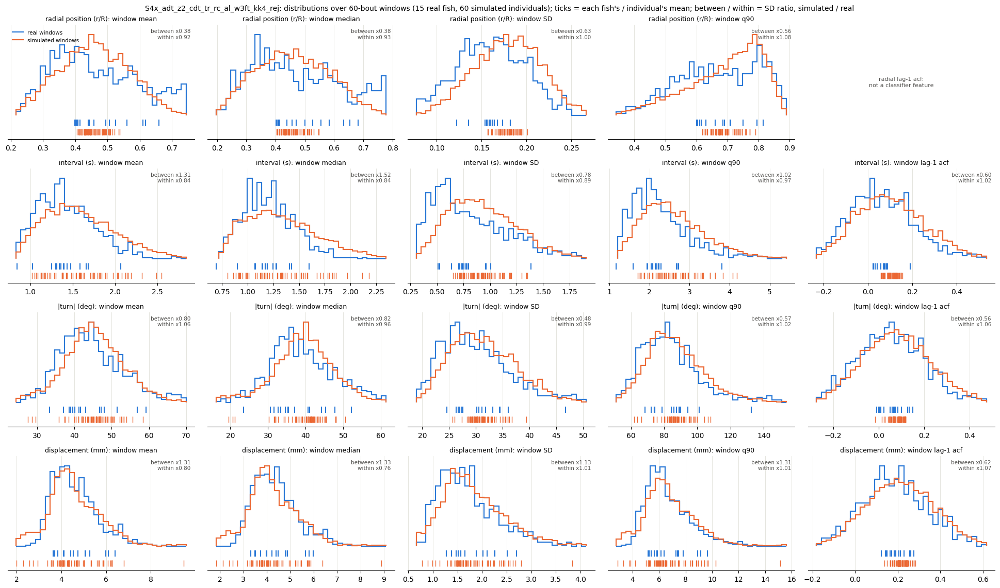


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4_fold4.pt: 3 rollouts
dropped 10.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.40     0.93  0.15  0.55   3.0   5.0                  22.3 +/- 0.9  22.8 +/- 1.0
d2s3.5    2.14     1.77  2.64  1.56  11.0   9.0                  17.4 +/- 0.9  19.2 +/- 1.0
d4s3.5    2.11     1.21  4.68  3.27  19.0   9.0                  18.7 +/- 1.7  16.9 +/- 0.8
d6s3.5    1.41     0.95  4.62  3.45  13.0  19.0                  16.7 +/- 1.3  16.5 +/- 0.7
d8s3.5    1.58     1.40  4.97  2.92  11.0  15.0                  16.3 +/- 1.0  16.1 +/- 0.7
d1s0    

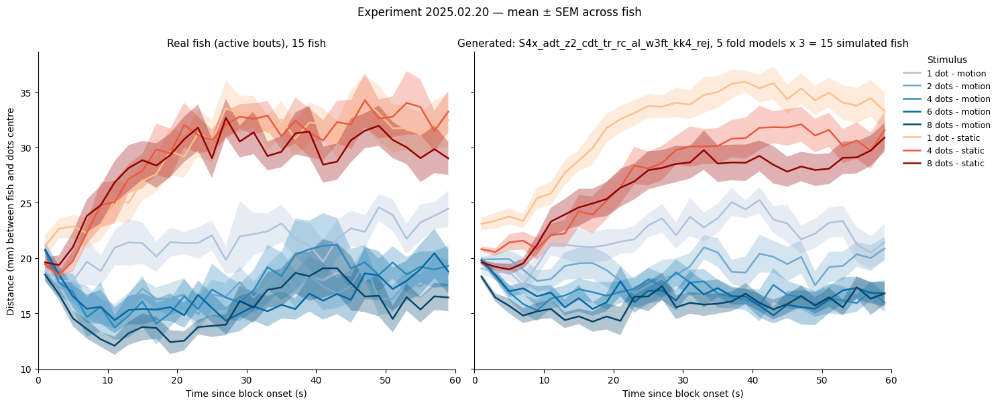


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

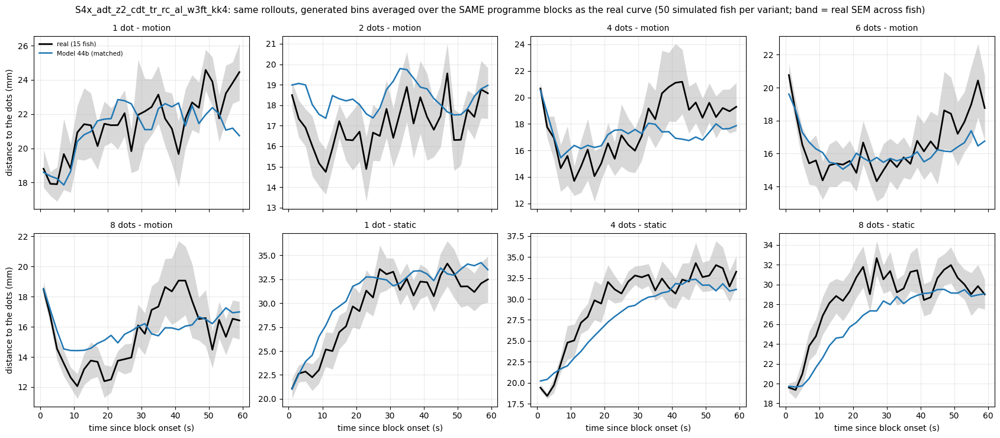


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk4                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            22.46  22.13      -0.33
d2s3.5       17.39  23.58       6.19                            18.14  22.16       4.01
d4s3.5       18.74  23.93       5.19                            17.61  22.29       4.68
d6s3.5       16.69  23.12       6.43                            16.05  21.76       5.71
d8s3.5       16.41  23.36       6.94                            16.26  22.01       5.75

== turn toward the moving dots by dot count
           real  S

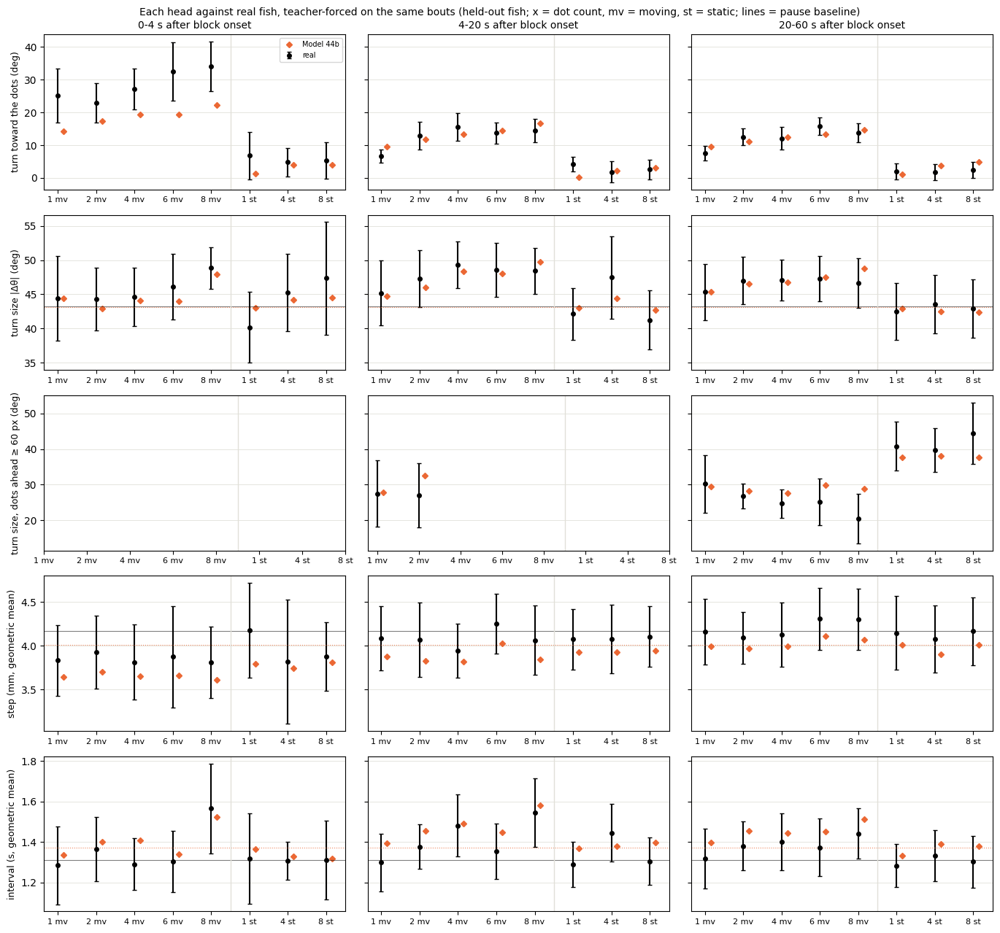

In [28]:
unit_eval.show('44b')

### M6-kin2, seed 0


== held-out likelihood per head (bits per bout)
turn             7.654
displacement     4.514
interval         1.225
joint           13.394

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2.csv  (15 rows) in 873s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2_rej
abs_dtheta_w1                                         7.3868
symbol_js                                             0.0

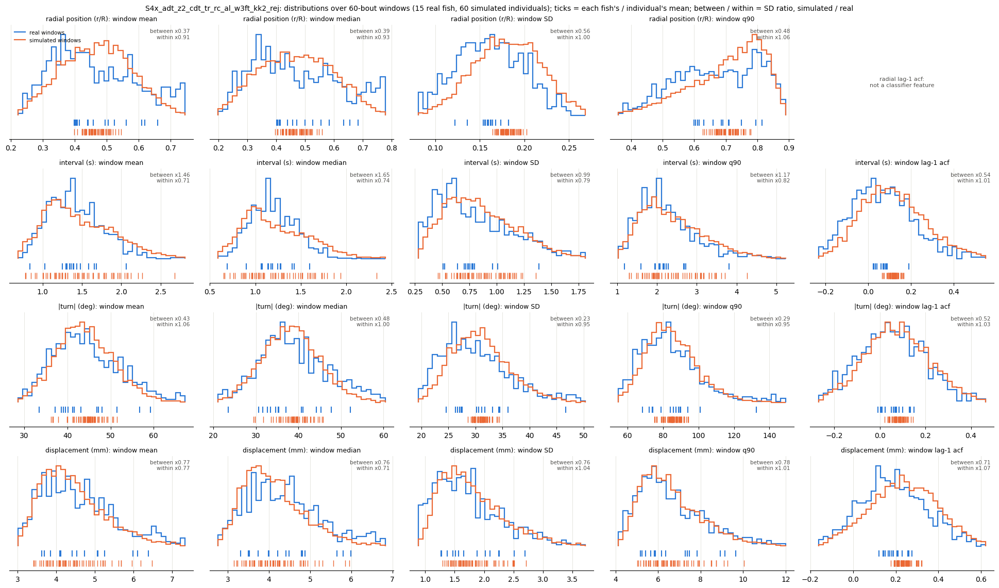


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2_fold4.pt: 3 rollouts
dropped 11.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.58     1.14  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.7 +/- 0.7
d2s3.5    2.04     1.67  2.64  0.87  11.0   9.0                  17.4 +/- 0.9  18.9 +/- 0.7
d4s3.5    1.14     0.67  4.68  3.92  19.0  11.0                  18.7 +/- 1.7  17.9 +/- 1.0
d6s3.5    1.17     0.82  4.62  3.29  13.0  19.0                  16.7 +/- 1.3  16.7 +/- 0.5
d8s3.5    1.85     1.74  4.97  2.97  11.0   9.0                  16.3 +/- 1.0  16.9 +/- 0.8
d1s0    

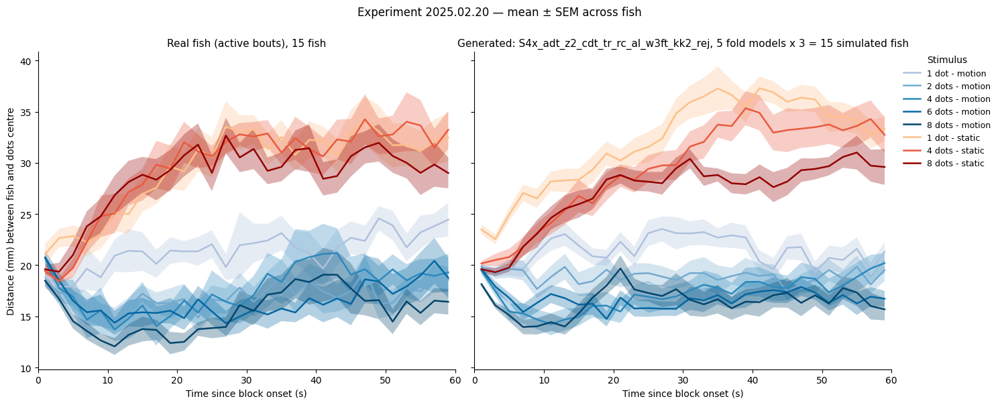


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

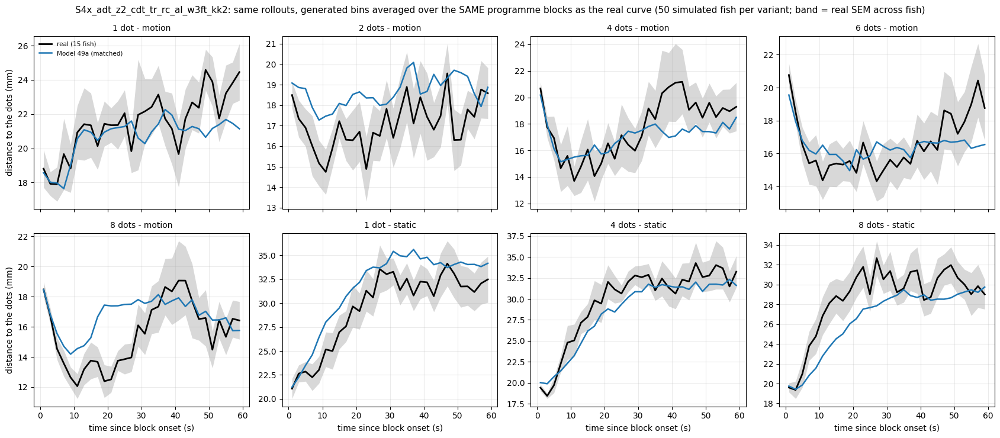


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            22.11  23.18       1.07
d2s3.5       17.39  23.58       6.19                            19.38  22.67       3.29
d4s3.5       18.74  23.93       5.19                            17.98  22.92       4.94
d6s3.5       16.69  23.12       6.43                            17.02  22.69       5.67
d8s3.5       16.41  23.36       6.94                            18.00  22.73       4.73

== turn toward the moving dots by dot count
           real  S

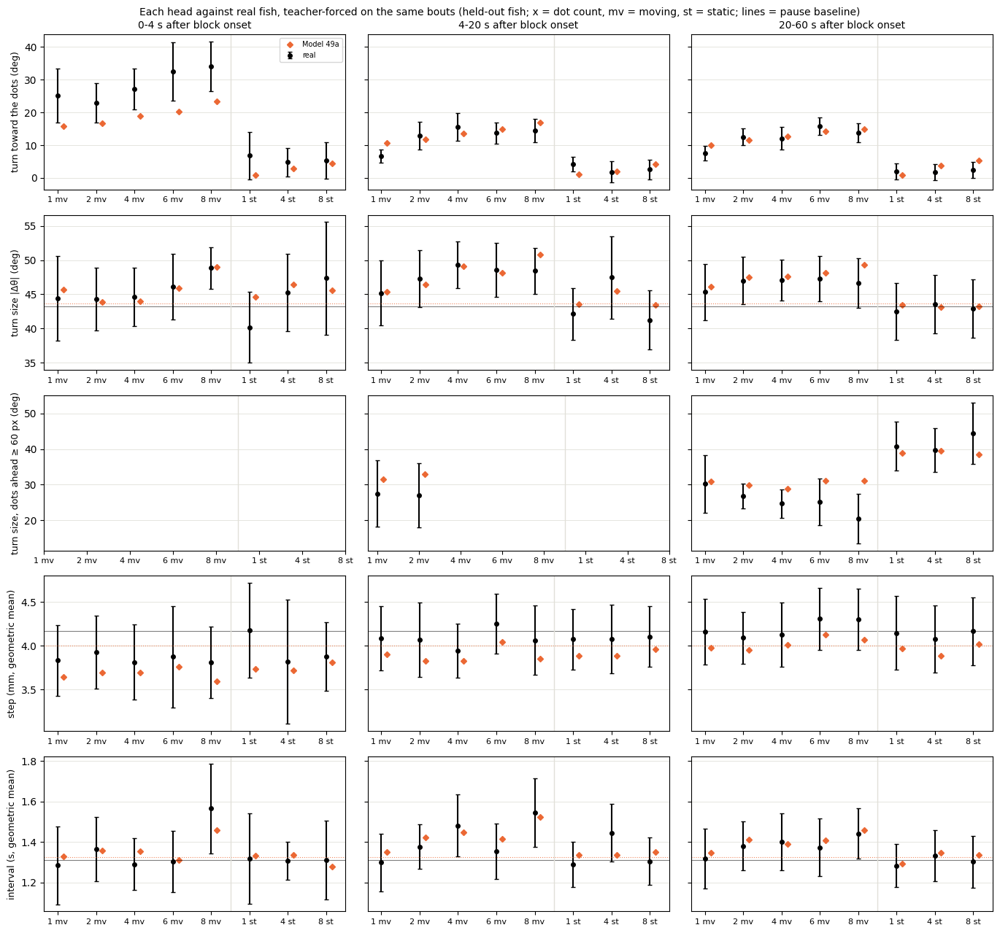

In [29]:
unit_eval.show('49a')

### M6-kin2, seed 101


== held-out likelihood per head (bits per bout)
turn             7.667
displacement     4.529
interval         1.240
joint           13.436

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2.csv  (15 rows) in 785s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2_rej
abs_dtheta_w1                                         7.8856
symbol_js                                             0.0

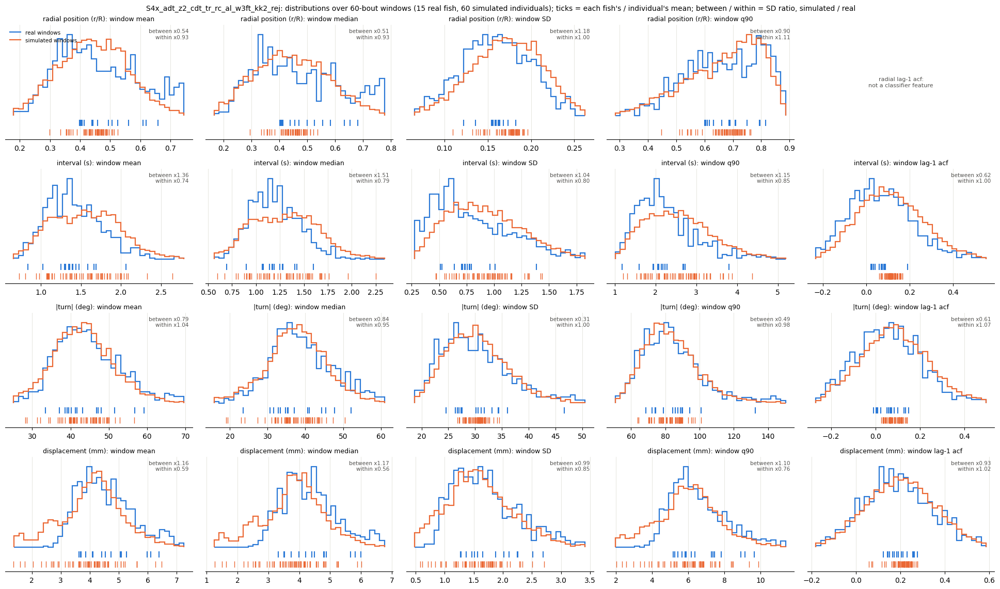


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2_fold4.pt: 3 rollouts
dropped 11.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.34     0.91  0.15   0.7   3.0   5.0                  22.3 +/- 0.9  21.8 +/- 0.5
d2s3.5    1.97     1.55  2.64  2.62  11.0  19.0                  17.4 +/- 0.9  19.5 +/- 0.6
d4s3.5    1.33     0.75  4.68  3.13  19.0  11.0                  18.7 +/- 1.7  17.4 +/- 0.7
d6s3.5    1.25     0.86  4.62  3.83  13.0  15.0                  16.7 +/- 1.3  17.7 +/- 1.1
d8s3.5    1.74     1.62  4.97  3.22  11.0   9.0                  16.3 +/- 1.0  16.4 +/- 0.6
d1s0    

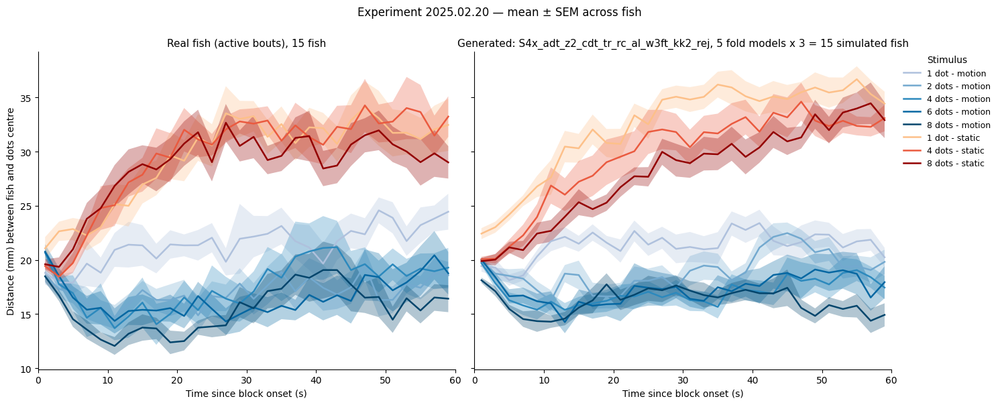


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

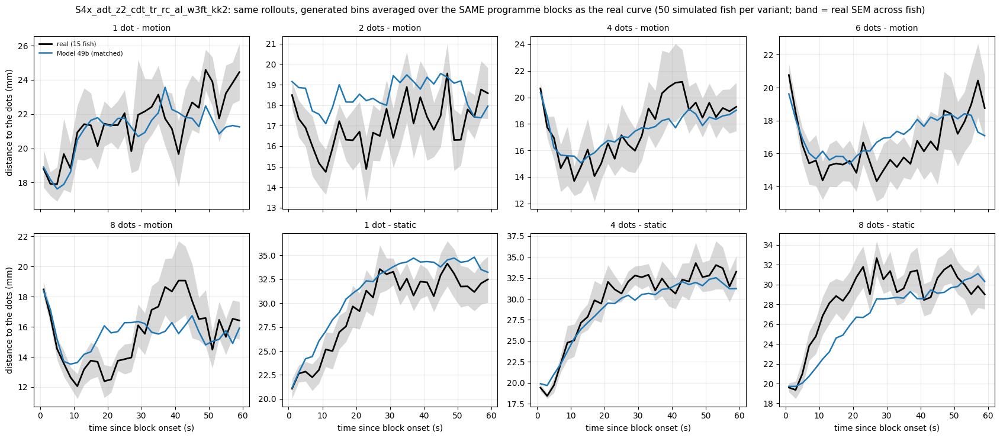


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk2                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            21.89  22.30       0.41
d2s3.5       17.39  23.58       6.19                            18.45  22.17       3.72
d4s3.5       18.74  23.93       5.19                            18.09  22.07       3.98
d6s3.5       16.69  23.12       6.43                            17.26  22.07       4.81
d8s3.5       16.41  23.36       6.94                            15.83  22.04       6.20

== turn toward the moving dots by dot count
           real  S

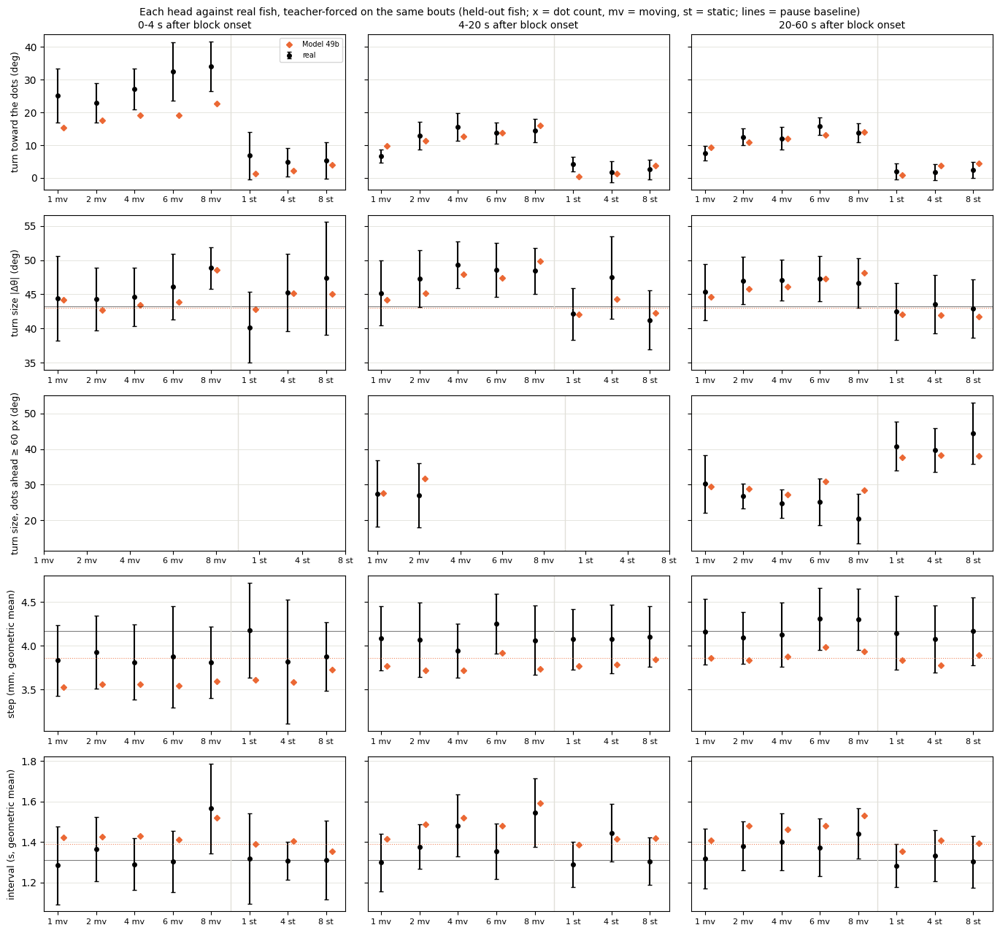

In [30]:
unit_eval.show('49b')

### M6-kin1, seed 0


== held-out likelihood per head (bits per bout)


turn             7.661
displacement     4.514
interval         1.246
joint           13.420

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1.csv  (15 rows) in 705s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1_rej
abs_dtheta_w1                                         8.1876
symbol_js                                             0.0114
dt_w1                                       

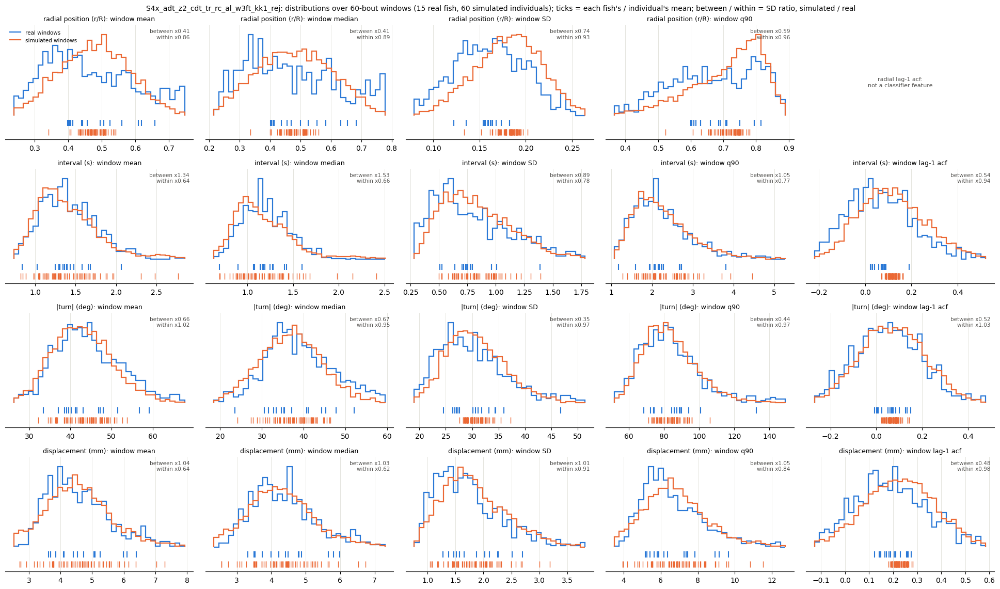


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1_fold4.pt: 3 rollouts
dropped 12.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.35     0.87  0.15  1.01   3.0   7.0                  22.3 +/- 0.9  22.3 +/- 1.0
d2s3.5    2.38     1.83  2.64  3.47  11.0  11.0                  17.4 +/- 0.9  20.4 +/- 0.8
d4s3.5    1.53     0.91  4.68  3.99  19.0   9.0                  18.7 +/- 1.7  17.7 +/- 0.8
d6s3.5    1.91     1.46  4.62  2.99  13.0  11.0                  16.7 +/- 1.3  18.5 +/- 0.7
d8s3.5    1.84     1.75  4.97  2.42  11.0  13.0                  16.3 +/- 1.0  17.1 +/- 0.9
d1s0    

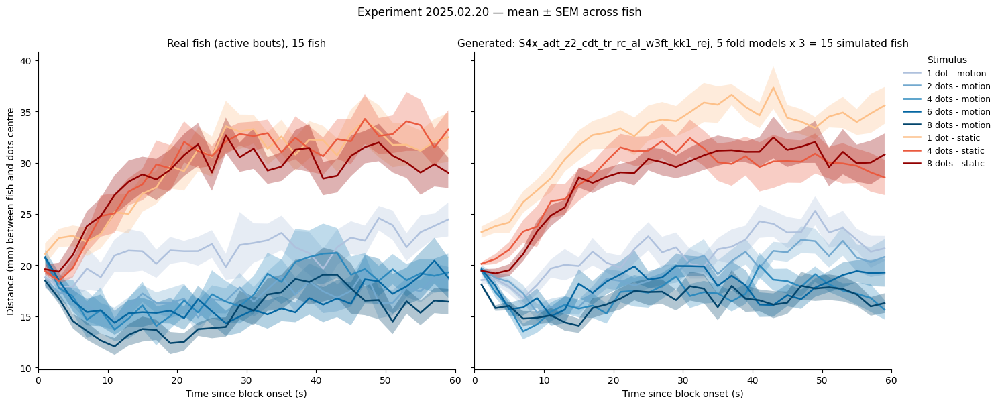


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

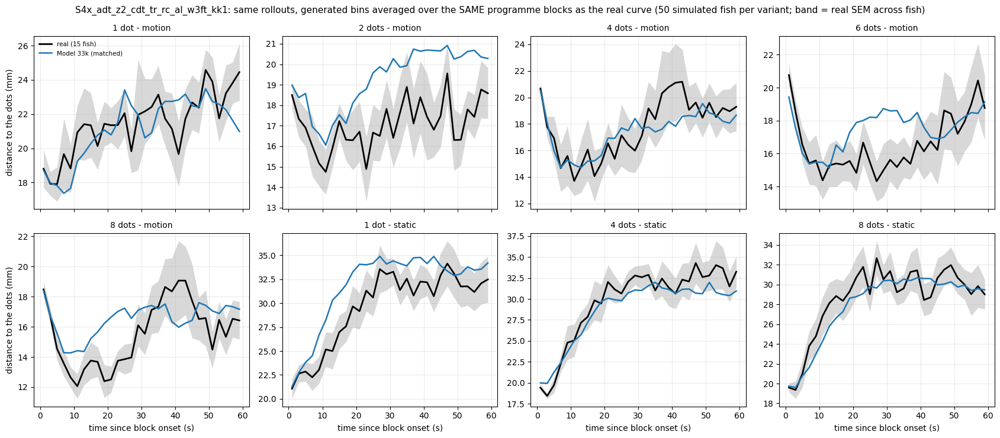


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            22.49  23.52       1.02
d2s3.5       17.39  23.58       6.19                            20.59  23.34       2.75
d4s3.5       18.74  23.93       5.19                            18.02  23.67       5.65
d6s3.5       16.69  23.12       6.43                            17.90  23.63       5.72
d8s3.5       16.41  23.36       6.94                            17.45  23.44       5.99

== turn toward the moving dots by dot count
           real  S

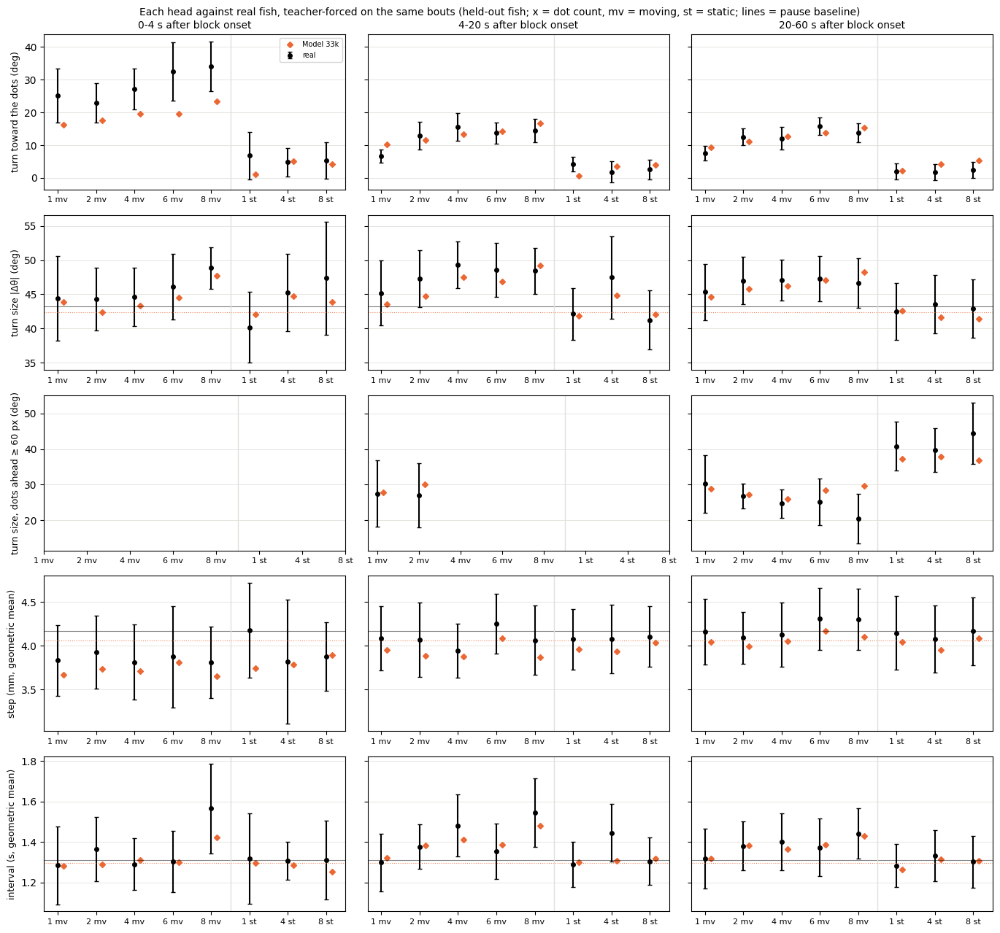

In [31]:
unit_eval.show('33k')

### M6-kin1, seed 101


== held-out likelihood per head (bits per bout)
turn             7.661
displacement     4.512
interval         1.250
joint           13.423

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1.csv  (15 rows) in 559s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1_rej
abs_dtheta_w1                                         8.0745
symbol_js                                             0.0

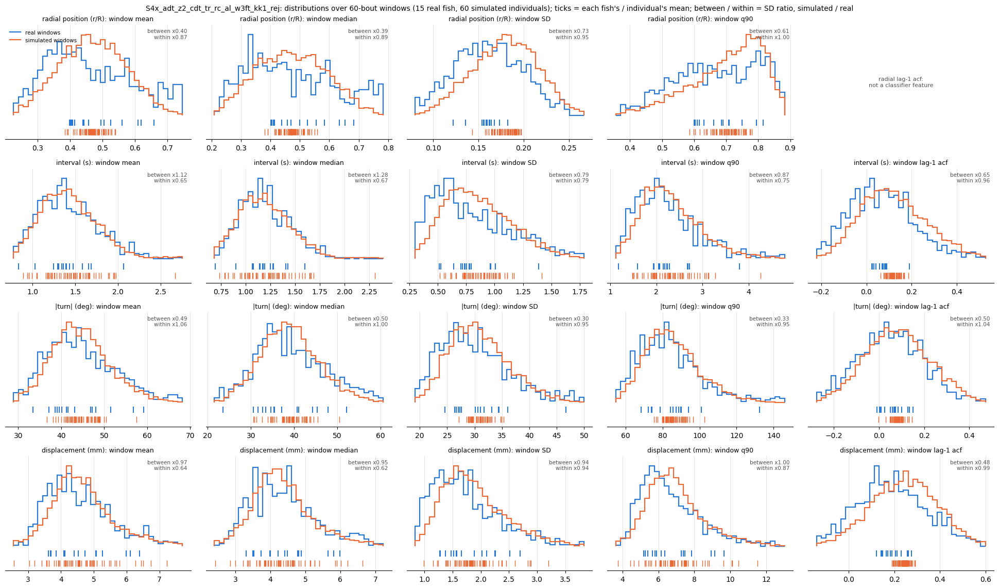


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1_fold4.pt: 3 rollouts
dropped 10.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.64     1.09  0.15  0.76   3.0   5.0                  22.3 +/- 0.9  20.5 +/- 0.7
d2s3.5    1.76     1.39  2.64  2.33  11.0   9.0                  17.4 +/- 0.9  19.3 +/- 0.5
d4s3.5    1.54     0.85  4.68  4.34  19.0  13.0                  18.7 +/- 1.7  17.3 +/- 0.9
d6s3.5    1.36     0.98  4.62  4.14  13.0  11.0                  16.7 +/- 1.3  16.8 +/- 0.7
d8s3.5    1.67     1.41  4.97  2.87  11.0   7.0                  16.3 +/- 1.0  15.8 +/- 0.8
d1s0    

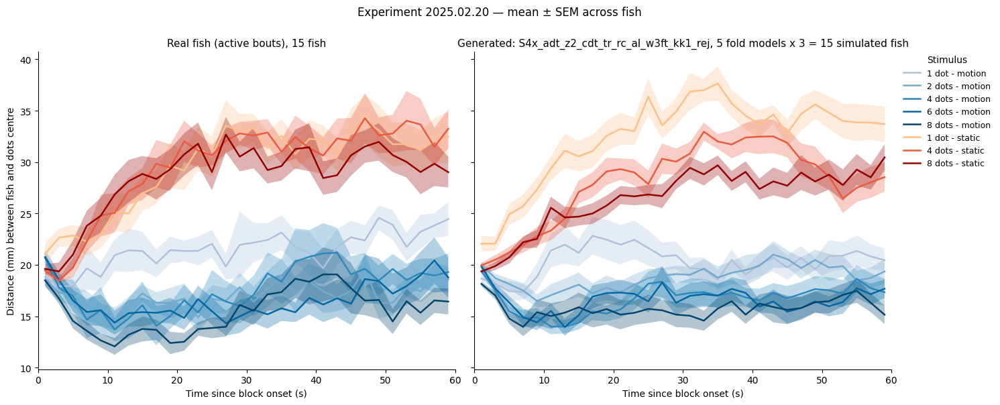


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

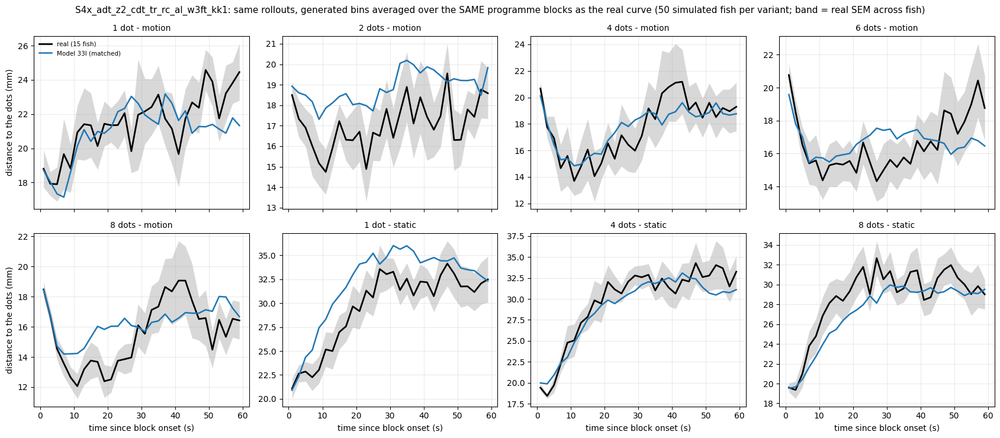


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk1                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            21.38  22.68       1.30
d2s3.5       17.39  23.58       6.19                            19.44  22.66       3.22
d4s3.5       18.74  23.93       5.19                            18.23  22.95       4.72
d6s3.5       16.69  23.12       6.43                            17.00  22.94       5.94
d8s3.5       16.41  23.36       6.94                            16.71  22.72       6.01

== turn toward the moving dots by dot count
           real  S

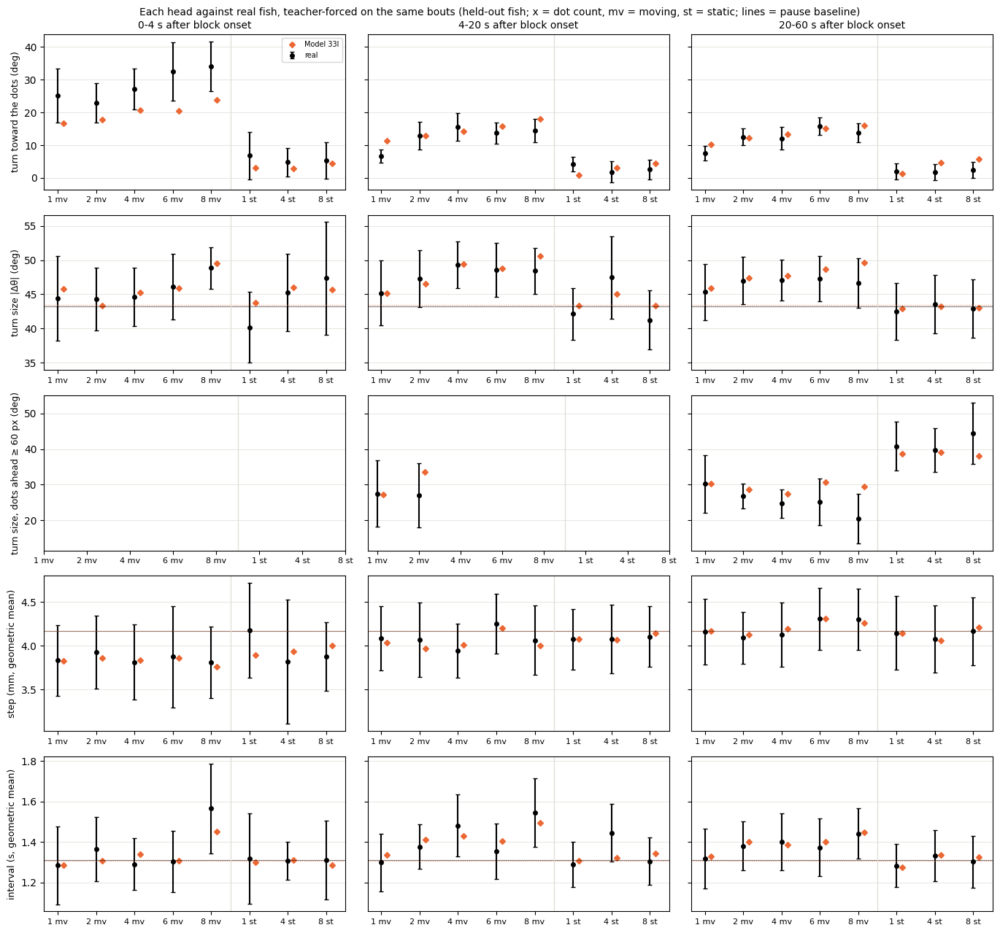

In [32]:
unit_eval.show('33l')

### M6-kin0, seed 0


== held-out likelihood per head (bits per bout)
turn             7.690
displacement     4.671
interval         1.345
joint           13.707

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0.csv  (15 rows) in 1475s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0_rej
abs_dtheta_w1                                         7.3882
symbol_js                                             0.

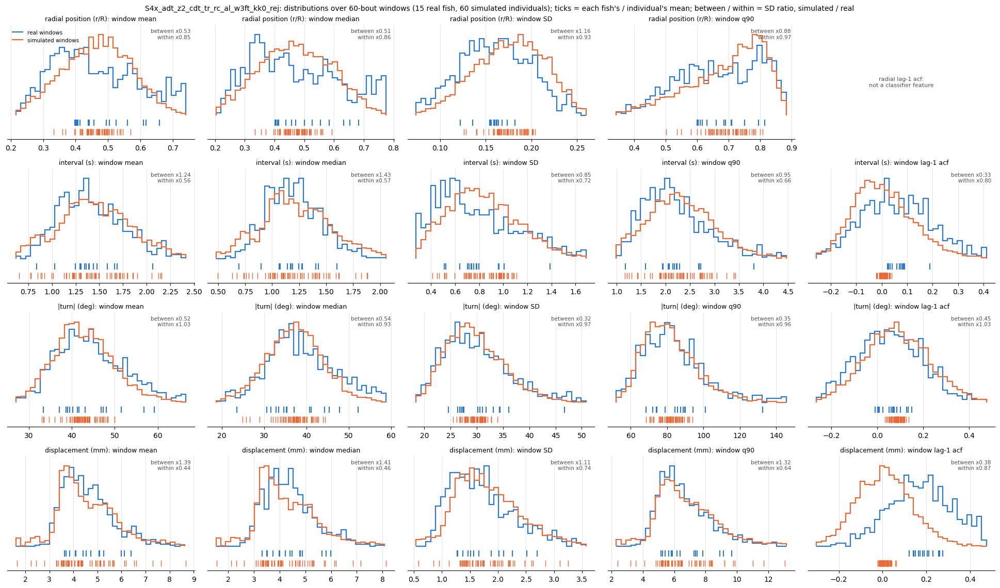


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0_fold4.pt: 3 rollouts
dropped 12.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.57     1.01  0.15  0.51   3.0   5.0                  22.3 +/- 0.9  23.2 +/- 1.4
d2s3.5    2.23     1.76  2.64  1.58  11.0   9.0                  17.4 +/- 0.9  19.8 +/- 1.2
d4s3.5    1.76     1.13  4.68  3.91  19.0   9.0                  18.7 +/- 1.7  20.5 +/- 1.3
d6s3.5    1.82     1.36  4.62   3.3  13.0   9.0                  16.7 +/- 1.3  18.4 +/- 1.3
d8s3.5    2.15     2.05  4.97  2.67  11.0   9.0                  16.3 +/- 1.0  17.5 +/- 1.0
d1s0    

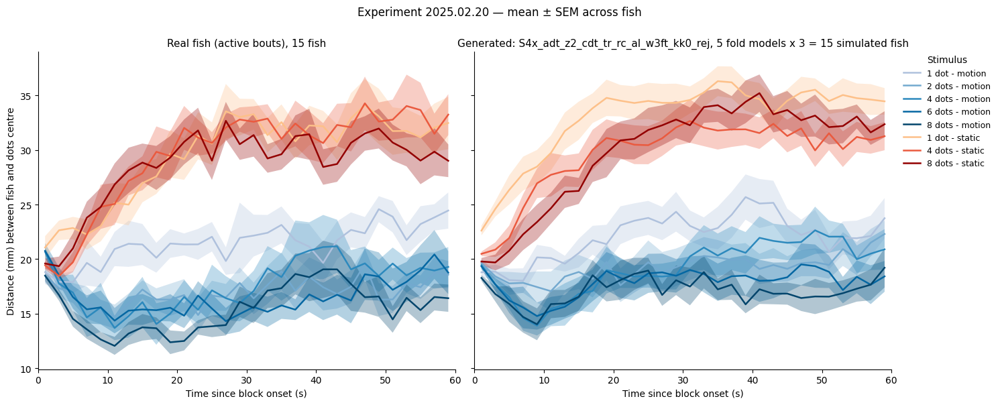


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

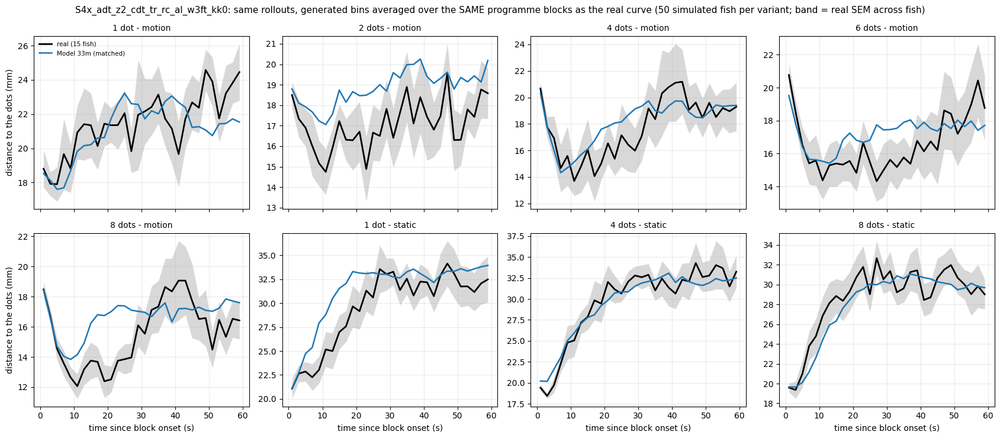


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            22.86  23.43       0.57
d2s3.5       17.39  23.58       6.19                            19.24  23.05       3.82
d4s3.5       18.74  23.93       5.19                            20.01  23.38       3.36
d6s3.5       16.69  23.12       6.43                            17.45  23.21       5.76
d8s3.5       16.41  23.36       6.94                            17.33  23.25       5.92

== turn toward the moving dots by dot count
           real  S

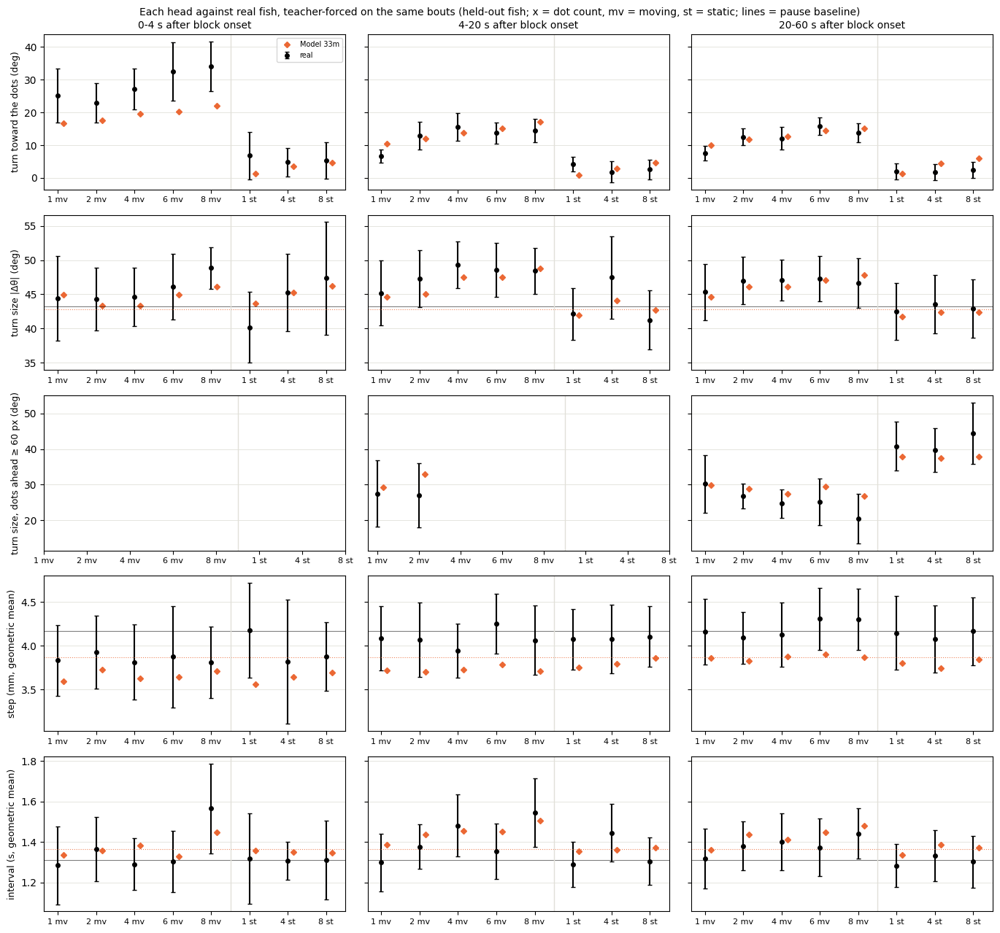

In [33]:
unit_eval.show('33m')

### M6-kin0, seed 101


== held-out likelihood per head (bits per bout)
turn             7.710
displacement     4.635
interval         1.324
joint           13.670

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0.csv  (15 rows) in 453s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0_rej
abs_dtheta_w1                                         7.9100
symbol_js                                             0.0

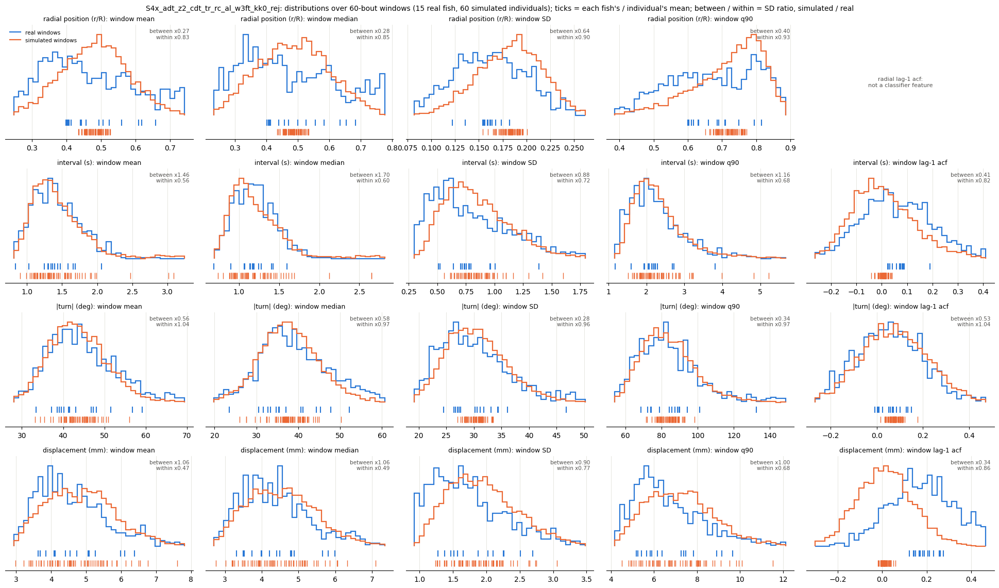


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0_fold4.pt: 3 rollouts
dropped 10.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.25     0.81  0.15  0.73   3.0   5.0                  22.3 +/- 0.9  21.5 +/- 0.8
d2s3.5    1.59     1.29  2.64  1.18  11.0   9.0                  17.4 +/- 0.9  18.8 +/- 1.2
d4s3.5    1.38     0.79  4.68  5.15  19.0   9.0                  18.7 +/- 1.7  17.8 +/- 1.1
d6s3.5    1.28     0.91  4.62  3.34  13.0   9.0                  16.7 +/- 1.3  17.3 +/- 0.7
d8s3.5    1.57     1.39  4.97  3.92  11.0  13.0                  16.3 +/- 1.0  16.5 +/- 0.8
d1s0    

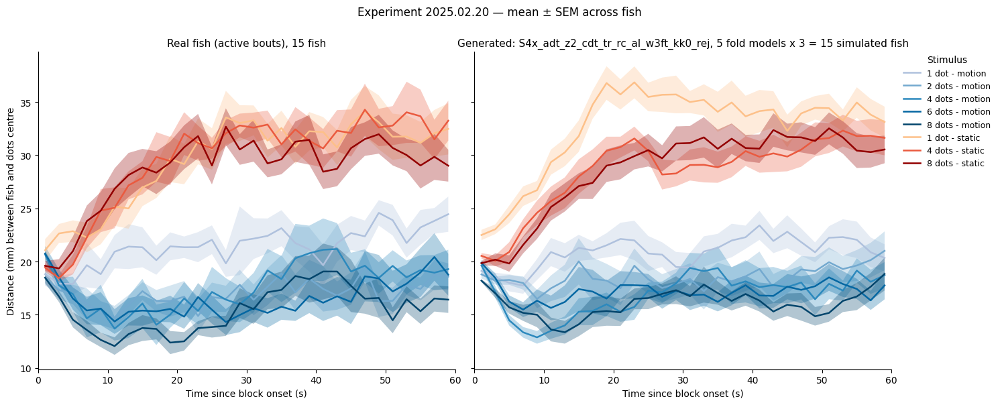


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

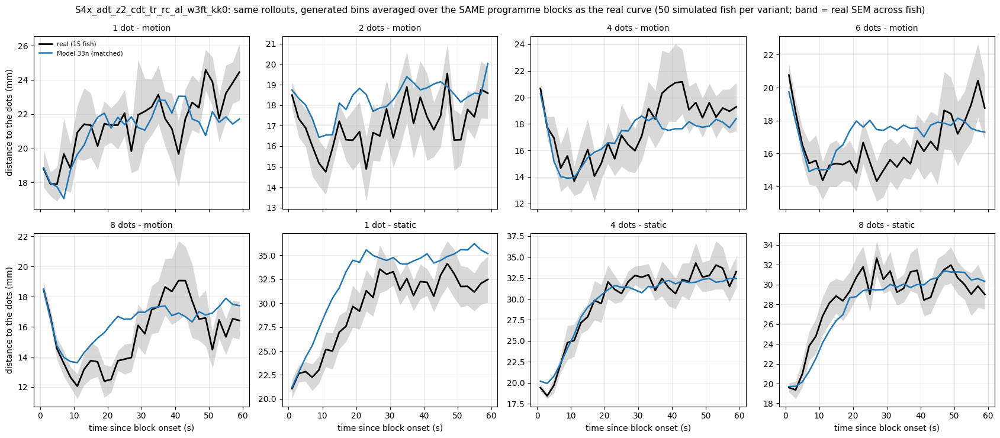


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_kk0                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            21.79  22.65       0.86
d2s3.5       17.39  23.58       6.19                            18.14  22.69       4.54
d4s3.5       18.74  23.93       5.19                            17.79  22.86       5.08
d6s3.5       16.69  23.12       6.43                            17.35  22.92       5.57
d8s3.5       16.41  23.36       6.94                            16.75  22.82       6.07

== turn toward the moving dots by dot count
           real  S

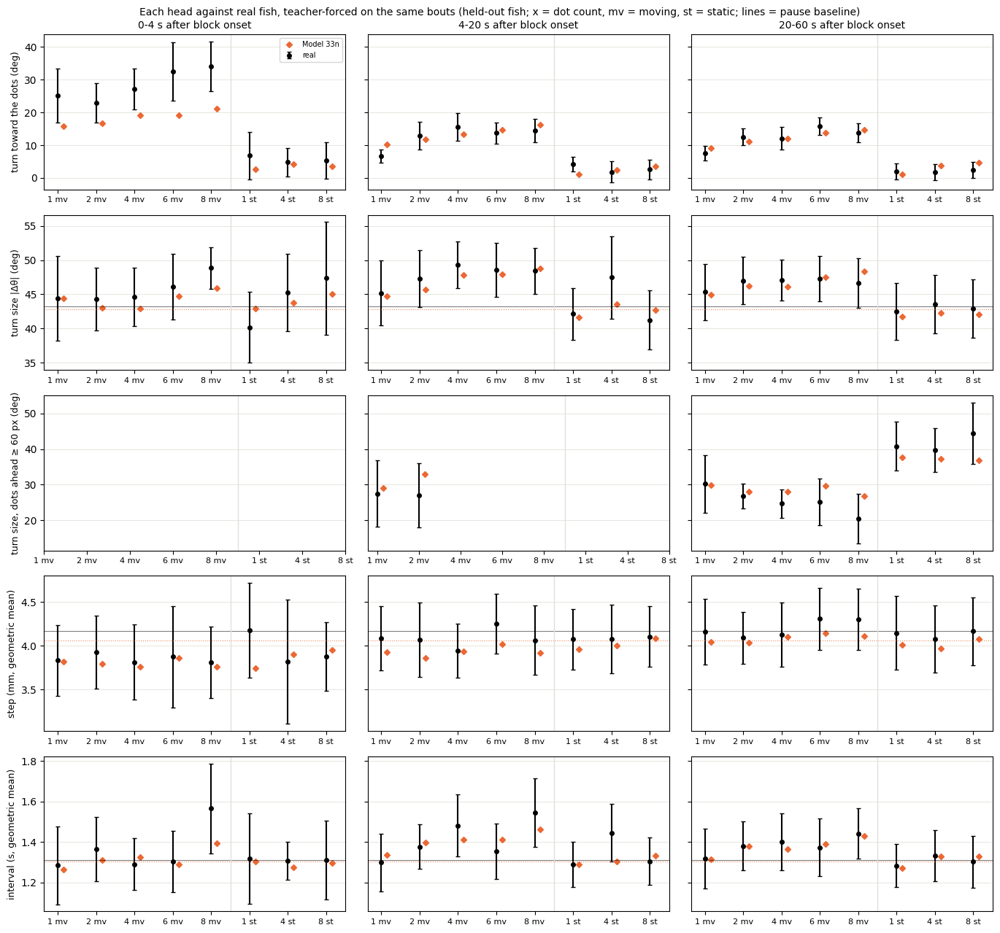

In [34]:
unit_eval.show('33n')

### M6-block clock, seed 0


== held-out likelihood per head (bits per bout)
turn             7.666
displacement     4.513
interval         1.217
joint           13.396

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_nck'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_nck.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_nck.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_nck.csv  (15 rows) in 417s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_nck_rej
abs_dtheta_w1                                         8.3854
symbol_js                                             0.0

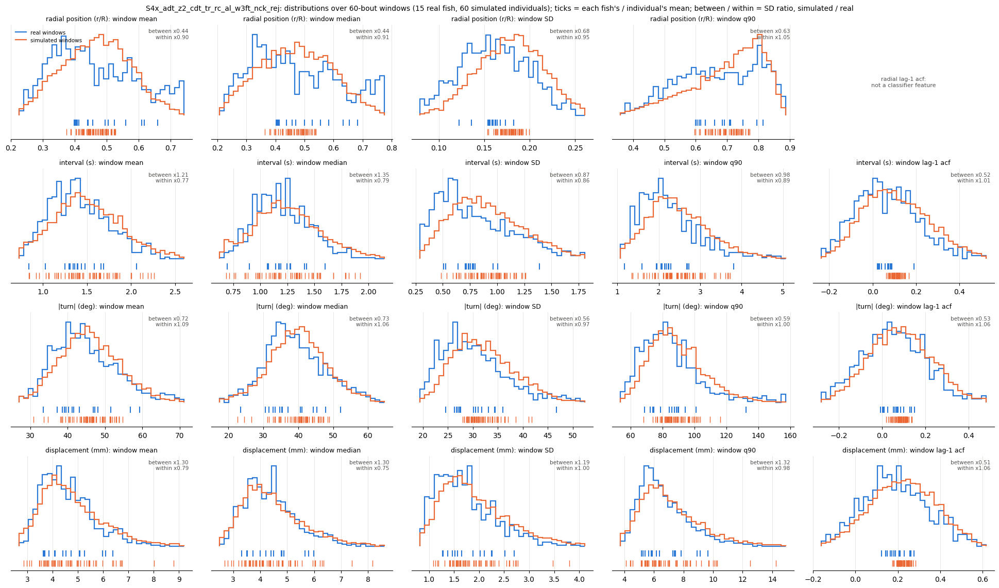


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_nck_fold4.pt: 3 rollouts
dropped 11.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.76     1.22  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  23.0 +/- 0.8
d2s3.5    1.04     0.83  2.64   3.2  11.0   9.0                  17.4 +/- 0.9  18.3 +/- 0.7
d4s3.5    1.38     0.87  4.68  2.79  19.0   7.0                  18.7 +/- 1.7  19.3 +/- 0.7
d6s3.5    1.32     0.92  4.62  4.12  13.0  19.0                  16.7 +/- 1.3  17.3 +/- 0.7
d8s3.5    2.19     2.16  4.97  2.54  11.0   7.0                  16.3 +/- 1.0  17.5 +/- 0.8
d1s0    

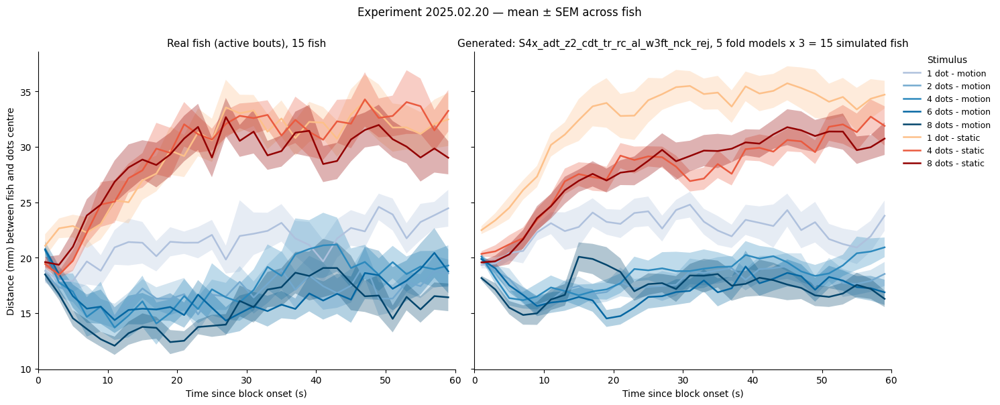


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

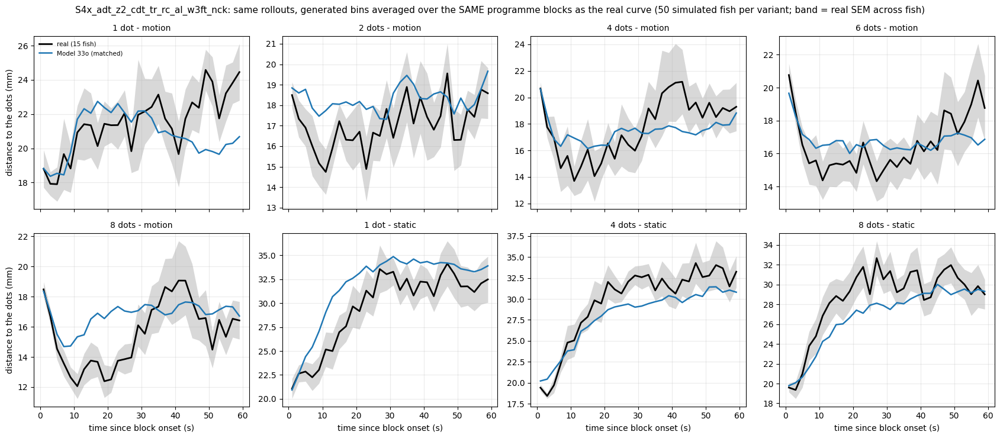


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_nck                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            21.83  23.36       1.53
d2s3.5       17.39  23.58       6.19                            18.29  23.02       4.73
d4s3.5       18.74  23.93       5.19                            18.55  23.11       4.55
d6s3.5       16.69  23.12       6.43                            17.17  23.41       6.24
d8s3.5       16.41  23.36       6.94                            17.50  22.95       5.45

== turn toward the moving dots by dot count
           real  S

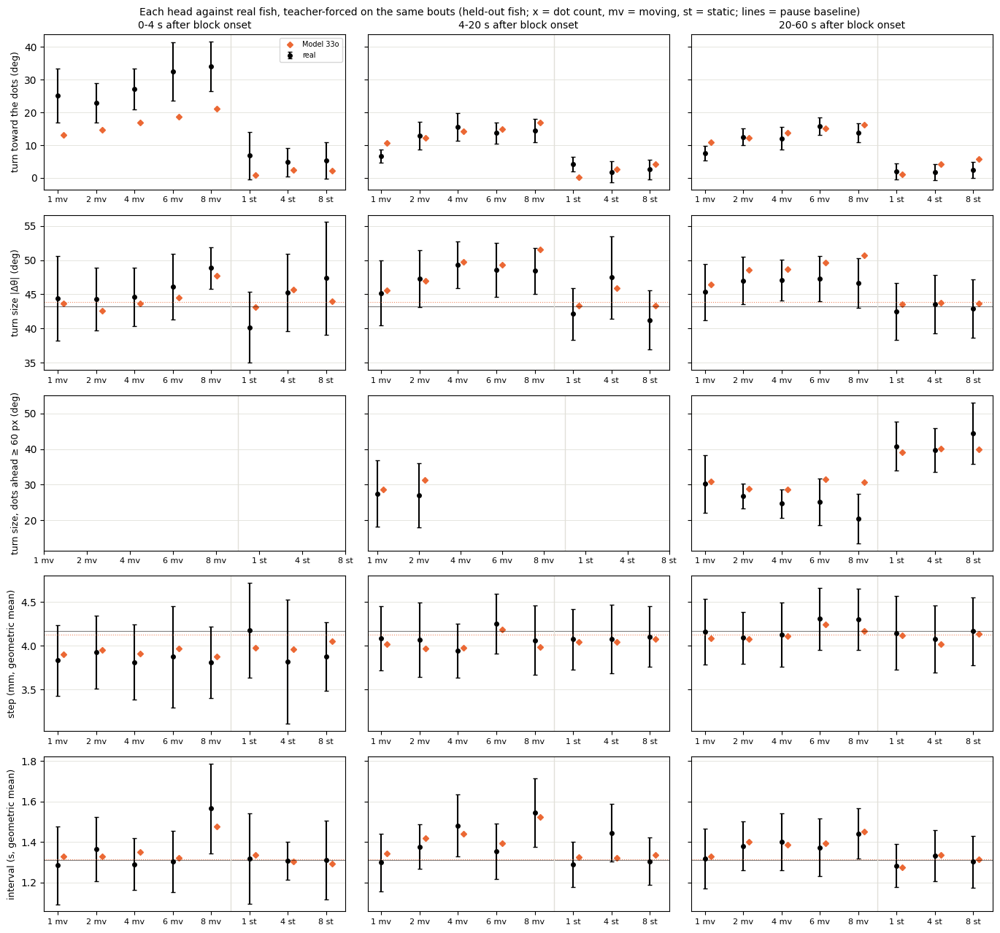

In [35]:
unit_eval.show('33o')

### M6-block clock, seed 101


== held-out likelihood per head (bits per bout)
turn             7.669
displacement     4.504
interval         1.212
joint           13.385

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_nck'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_nck.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_nck.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_nck.csv  (15 rows) in 683s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_nck_rej
abs_dtheta_w1                                         8.8494
symbol_js                                             0.0

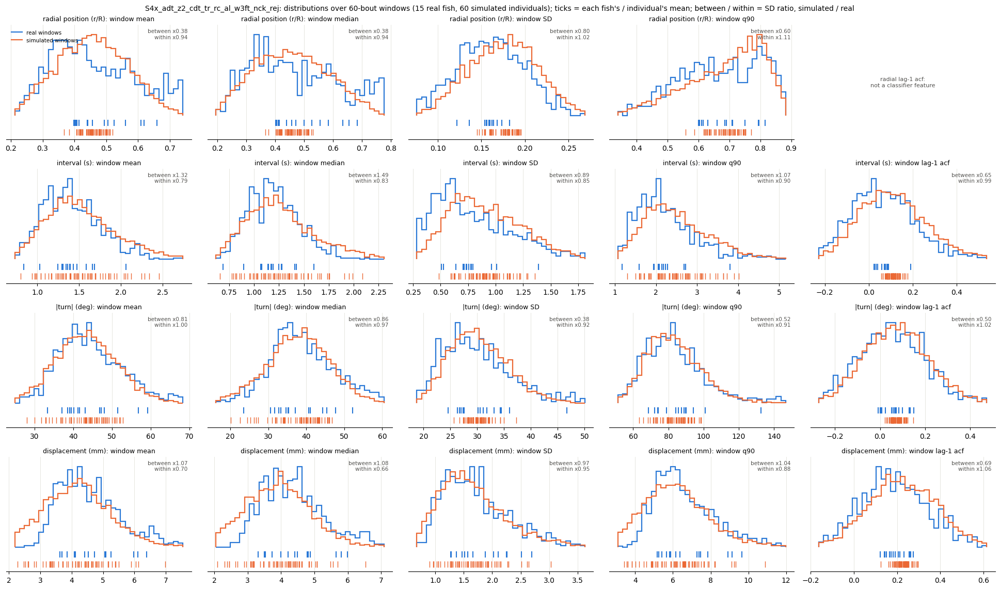


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_nck_fold4.pt: 3 rollouts
dropped 12.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.68     1.12  0.15  0.36   3.0   5.0                  22.3 +/- 0.9  20.1 +/- 0.6
d2s3.5    1.42     1.20  2.64  1.81  11.0  19.0                  17.4 +/- 0.9  18.1 +/- 0.7
d4s3.5    2.15     1.21  4.68   3.9  19.0  19.0                  18.7 +/- 1.7  15.8 +/- 0.7
d6s3.5    1.17     0.78  4.62  4.78  13.0  11.0                  16.7 +/- 1.3  16.1 +/- 0.8
d8s3.5    1.63     1.61  4.97  2.63  11.0  13.0                  16.3 +/- 1.0  16.6 +/- 0.7
d1s0    

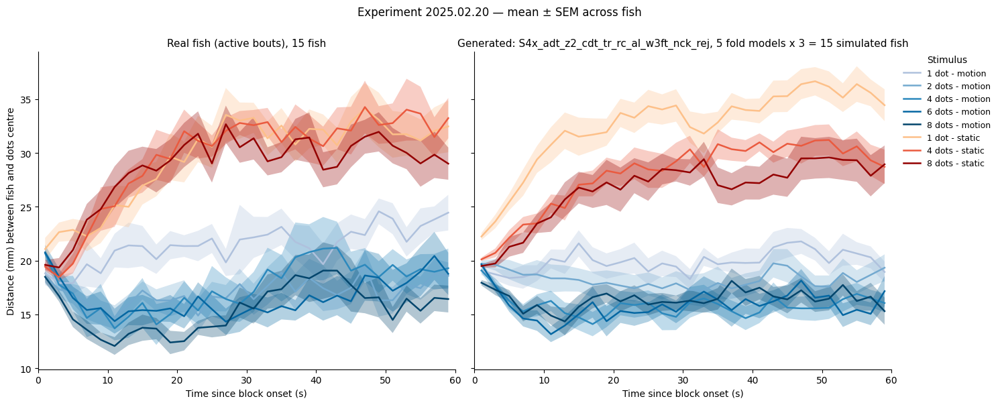


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

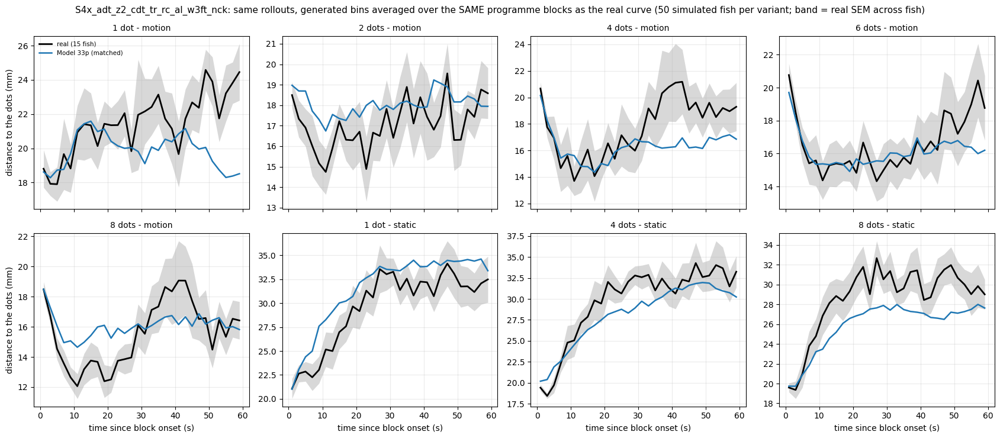


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_nck                  
           plateau   null attraction                          plateau   null attraction
cond_label                                                                             
d1s3.5       22.41  23.57       1.16                            19.95  22.11       2.17
d2s3.5       17.39  23.58       6.19                            18.35  21.82       3.47
d4s3.5       18.74  23.93       5.19                            16.36  21.99       5.64
d6s3.5       16.69  23.12       6.43                            15.96  22.00       6.04
d8s3.5       16.41  23.36       6.94                            16.49  21.92       5.43

== turn toward the moving dots by dot count
           real  S

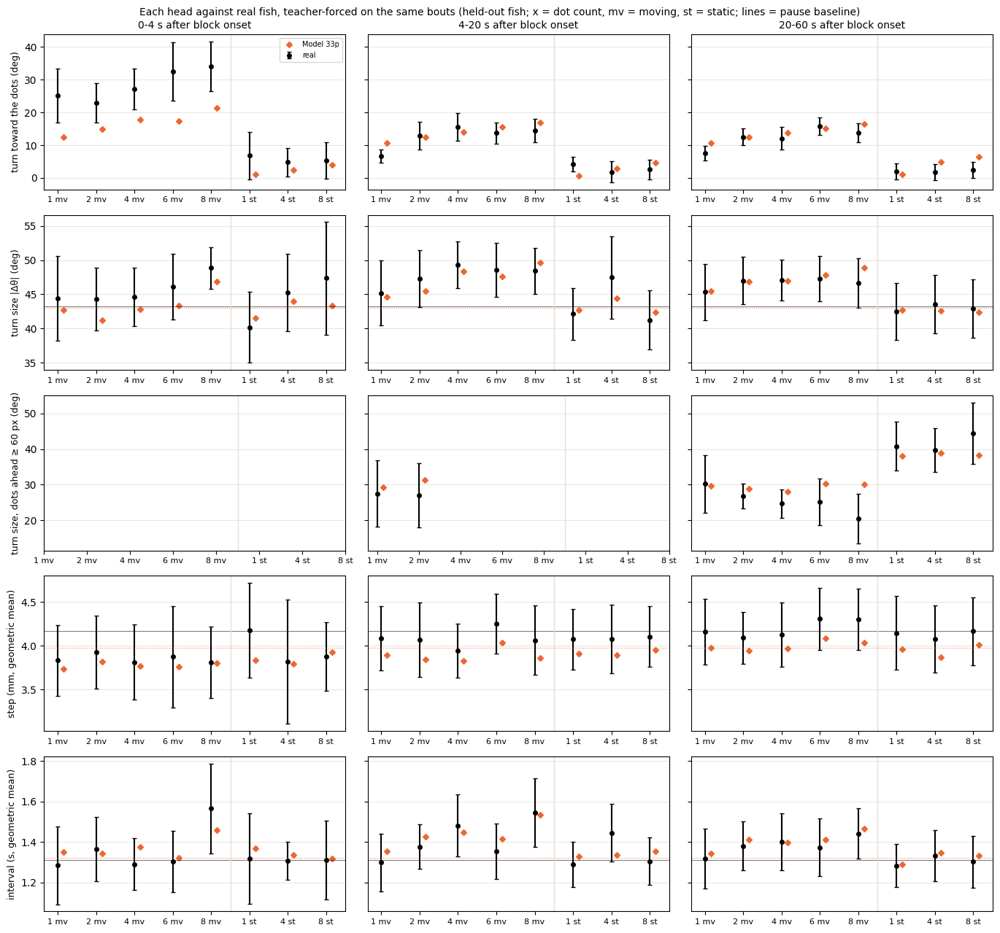

In [36]:
unit_eval.show('33p')

### M6-run clock, seed 0


== held-out likelihood per head (bits per bout)
turn             7.660
displacement     4.498
interval         1.222
joint           13.380

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv  (15 rows) in 3958s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_al_w3ft_rej
abs_dtheta_w1                                  7.7210
symbol_js                                      0.0096
dt_w1                                       

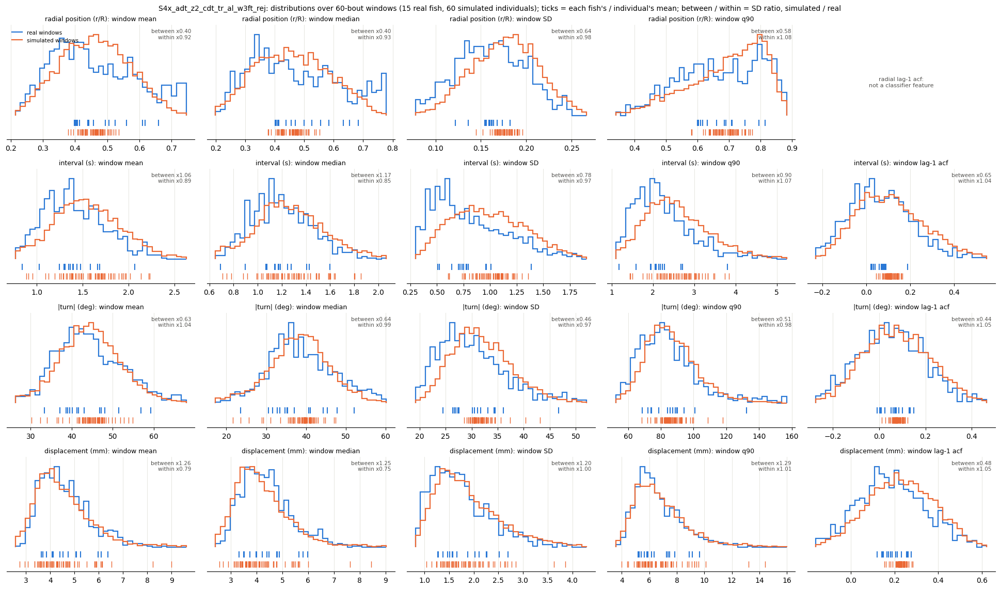


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_al_w3ft_fold4.pt: 3 rollouts
dropped 12.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.88  0.15  0.31   3.0   3.0                  22.3 +/- 0.9  22.7 +/- 0.9
d2s3.5    3.72     2.94  2.64  0.89  11.0   7.0                  17.4 +/- 0.9  21.3 +/- 1.0
d4s3.5    1.77     1.09  4.68  2.34  19.0   7.0                  18.7 +/- 1.7  19.7 +/- 1.1
d6s3.5    1.55     1.17  4.62  3.67  13.0   9.0                  16.7 +/- 1.3  18.1 +/- 0.7
d8s3.5    2.02     1.96  4.97  2.31  11.0   7.0                  16.3 +/- 1.0  17.9 +/- 0.7
d1s0      3.40 

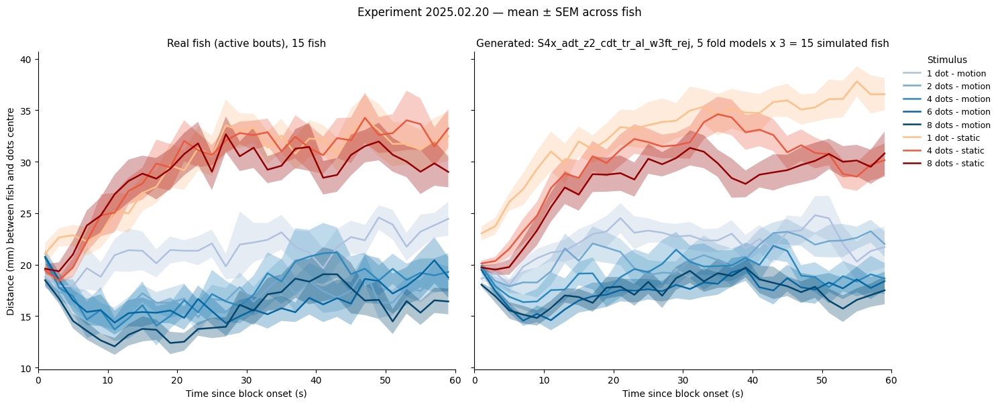


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

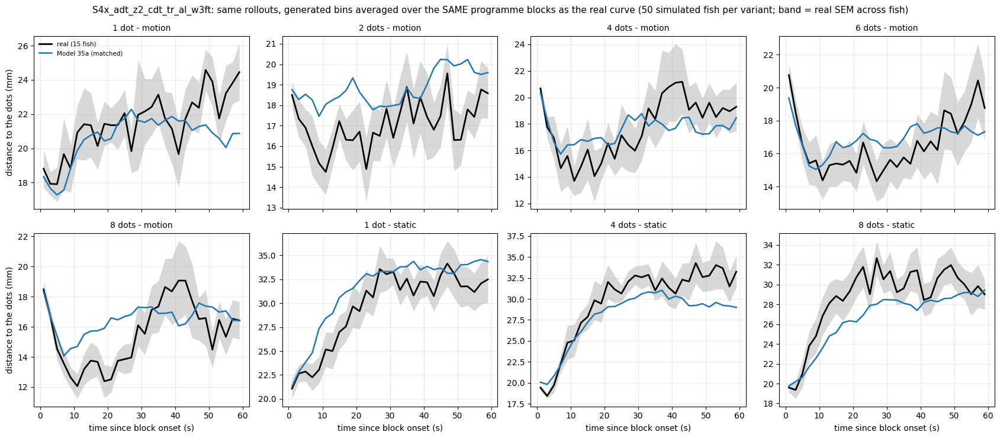


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_al_w3ft                  
           plateau   null attraction                   plateau   null attraction
cond_label                                                                      
d1s3.5       22.41  23.57       1.16                     21.68  22.78       1.09
d2s3.5       17.39  23.58       6.19                     19.87  22.95       3.08
d4s3.5       18.74  23.93       5.19                     18.67  23.22       4.55
d6s3.5       16.69  23.12       6.43                     17.41  22.81       5.39
d8s3.5       16.41  23.36       6.94                     17.41  22.80       5.39

== turn toward the moving dots by dot count
           real  S4x_adt_z2_cdt_tr_al_w3ft
win    N                       

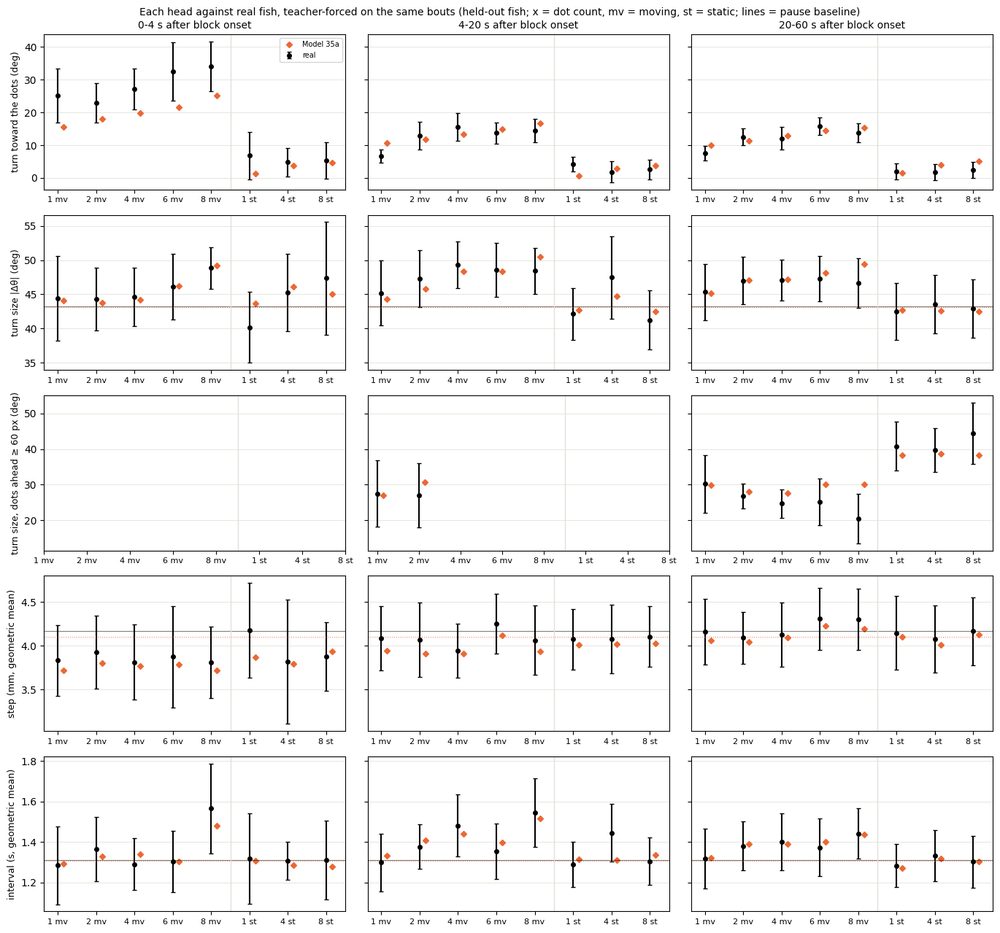

In [37]:
unit_eval.show('35a')

### M6-run clock, seed 101


== held-out likelihood per head (bits per bout)
turn             7.664
displacement     4.508
interval         1.208
joint           13.380

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv  (15 rows) in 2680s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_al_w3ft_rej
abs_dtheta_w1                                  9.1976
symbol_js                                      0.0136
dt_w1                                       

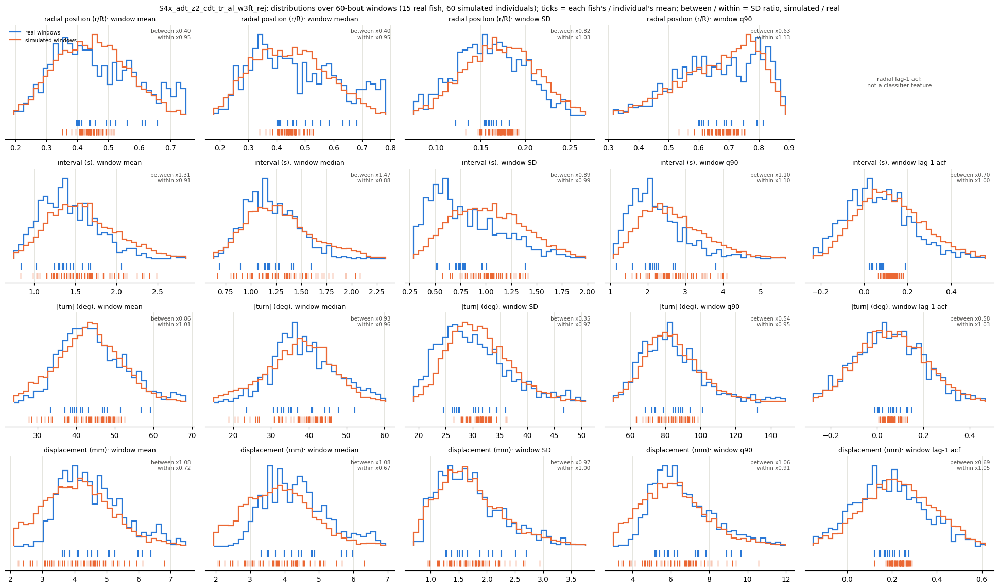


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_al_w3ft_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.00     1.34  0.15  0.79   3.0   7.0                  22.3 +/- 0.9  20.1 +/- 0.9
d2s3.5    1.76     1.46  2.64  1.35  11.0   9.0                  17.4 +/- 0.9  18.1 +/- 0.8
d4s3.5    1.96     1.09  4.68  3.46  19.0   9.0                  18.7 +/- 1.7  16.1 +/- 0.7
d6s3.5    1.26     0.82  4.62  4.19  13.0  19.0                  16.7 +/- 1.3  16.0 +/- 0.8
d8s3.5    1.67     1.56  4.97  2.09  11.0   9.0                  16.3 +/- 1.0  16.2 +/- 0.7
d1s0      2.03 

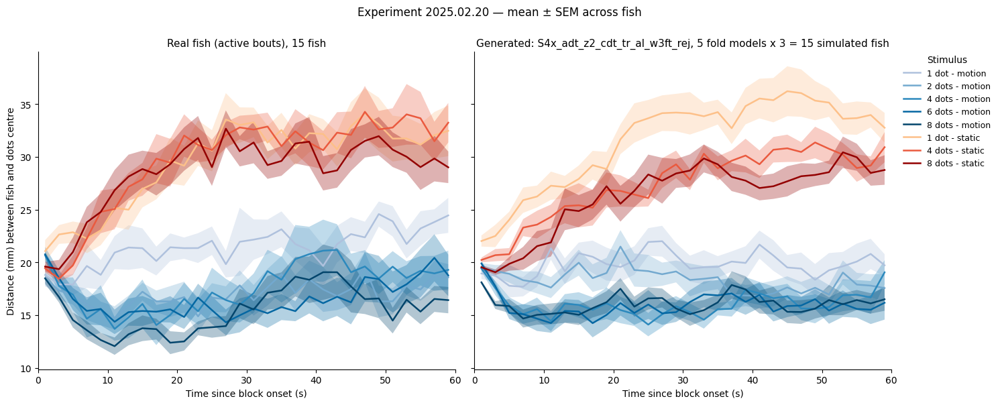


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

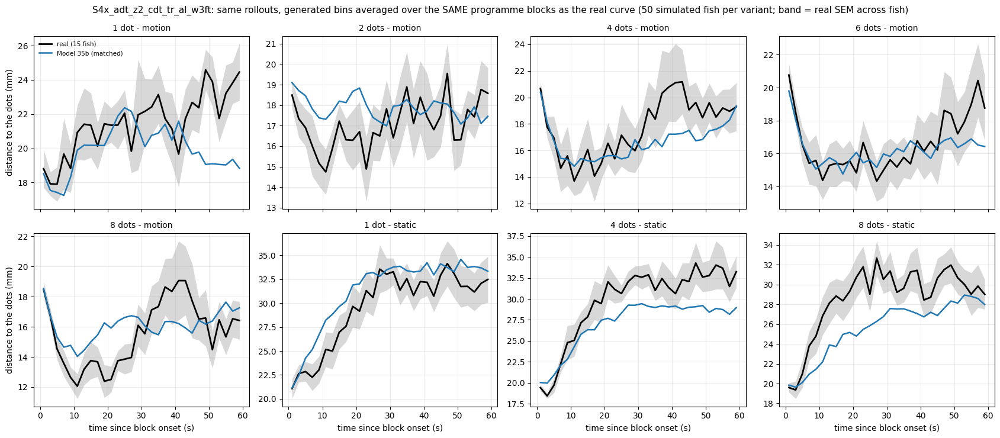


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_al_w3ft                  
           plateau   null attraction                   plateau   null attraction
cond_label                                                                      
d1s3.5       22.41  23.57       1.16                     20.46  21.94       1.48
d2s3.5       17.39  23.58       6.19                     18.71  21.81       3.10
d4s3.5       18.74  23.93       5.19                     16.73  21.97       5.24
d6s3.5       16.69  23.12       6.43                     16.02  21.75       5.73
d8s3.5       16.41  23.36       6.94                     16.12  21.66       5.55

== turn toward the moving dots by dot count
           real  S4x_adt_z2_cdt_tr_al_w3ft
win    N                       

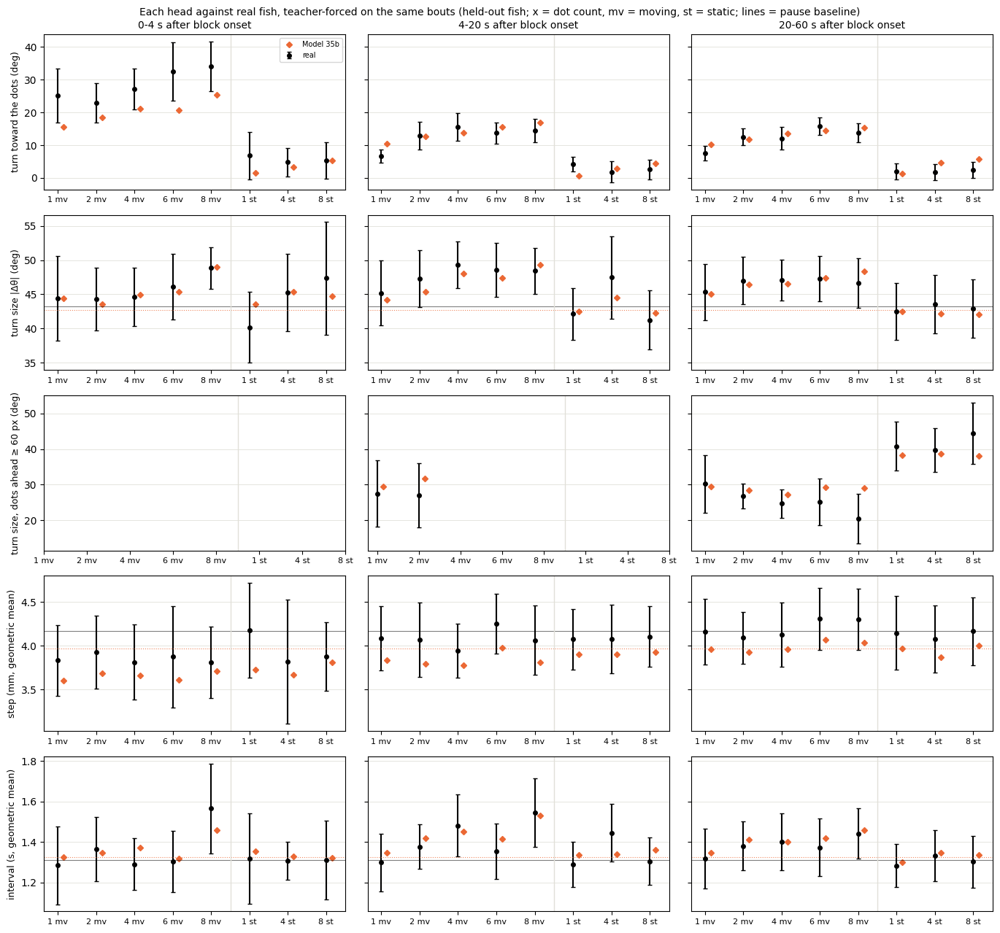

In [38]:
unit_eval.show('35b')

### M6-x3, seed 0


== held-out likelihood per head (bits per bout)
turn             7.659
displacement     4.503
interval         1.217
joint           13.380

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al.csv  (15 rows) in 2728s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_rej
abs_dtheta_w1                                8.6017
symbol_js                                    0.0116
dt_w1                                        0.4133
dist_w

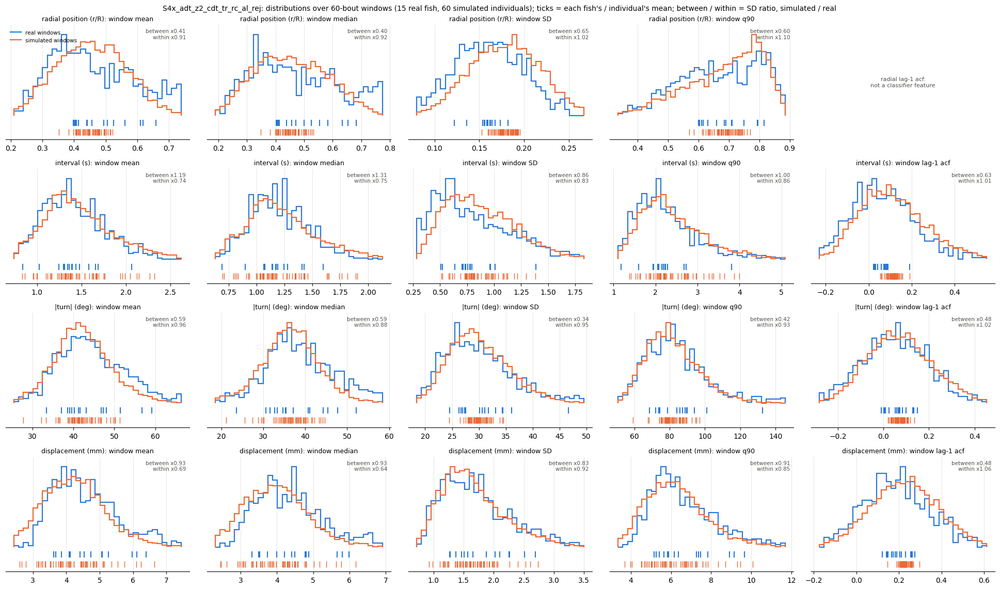


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_fold4.pt: 3 rollouts
dropped 10.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.16     1.43  0.15  0.63   3.0   5.0                  22.3 +/- 0.9  19.8 +/- 0.4
d2s3.5    1.60     1.25  2.64  3.33  11.0   9.0                  17.4 +/- 0.9  19.1 +/- 0.7
d4s3.5    1.31     0.83  4.68  2.82  19.0  11.0                  18.7 +/- 1.7  18.6 +/- 0.5
d6s3.5    1.97     1.46  4.62  3.14  13.0   9.0                  16.7 +/- 1.3  19.0 +/- 0.7
d8s3.5    1.92     1.91  4.97  1.61  11.0   9.0                  16.3 +/- 1.0  17.1 +/- 0.3
d1s0      2.76   

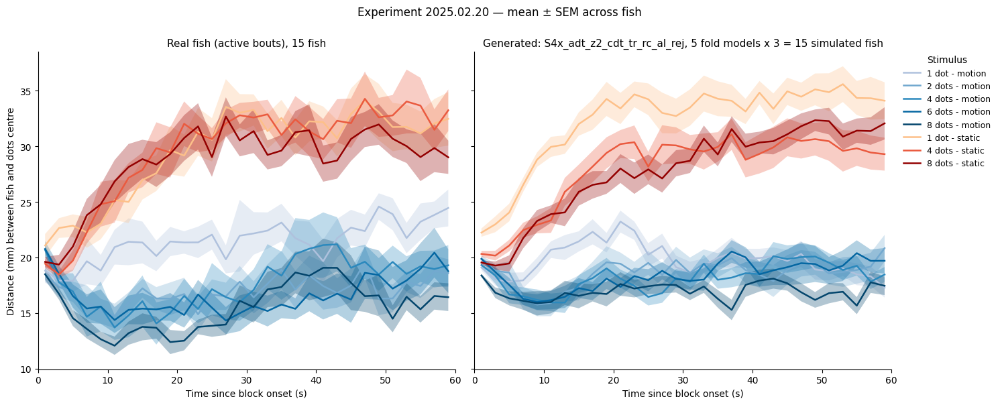


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

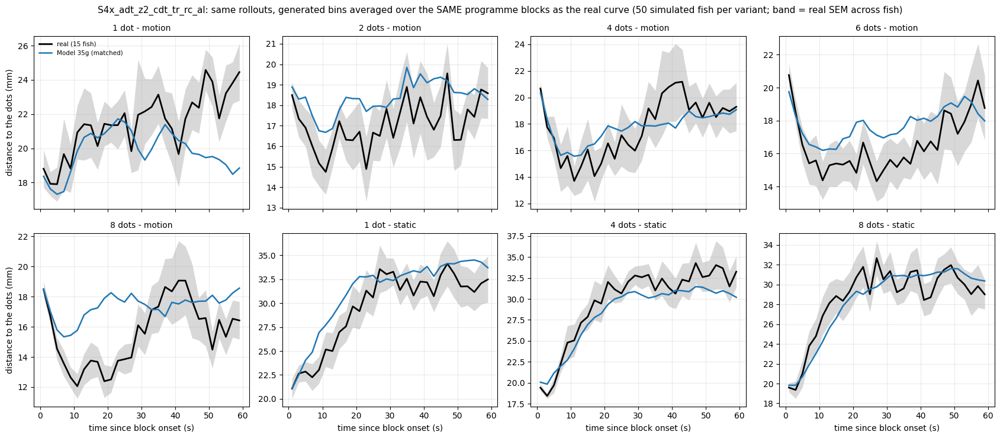


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al                  
           plateau   null attraction                 plateau   null attraction
cond_label                                                                    
d1s3.5       22.41  23.57       1.16                   20.09  22.11       2.01
d2s3.5       17.39  23.58       6.19                   18.82  21.86       3.05
d4s3.5       18.74  23.93       5.19                   18.23  21.77       3.54
d6s3.5       16.69  23.12       6.43                   18.59  21.93       3.33
d8s3.5       16.41  23.36       6.94                   17.40  21.85       4.45

== turn toward the moving dots by dot count
           real  S4x_adt_z2_cdt_tr_rc_al
win    N                                
0-20 s 1

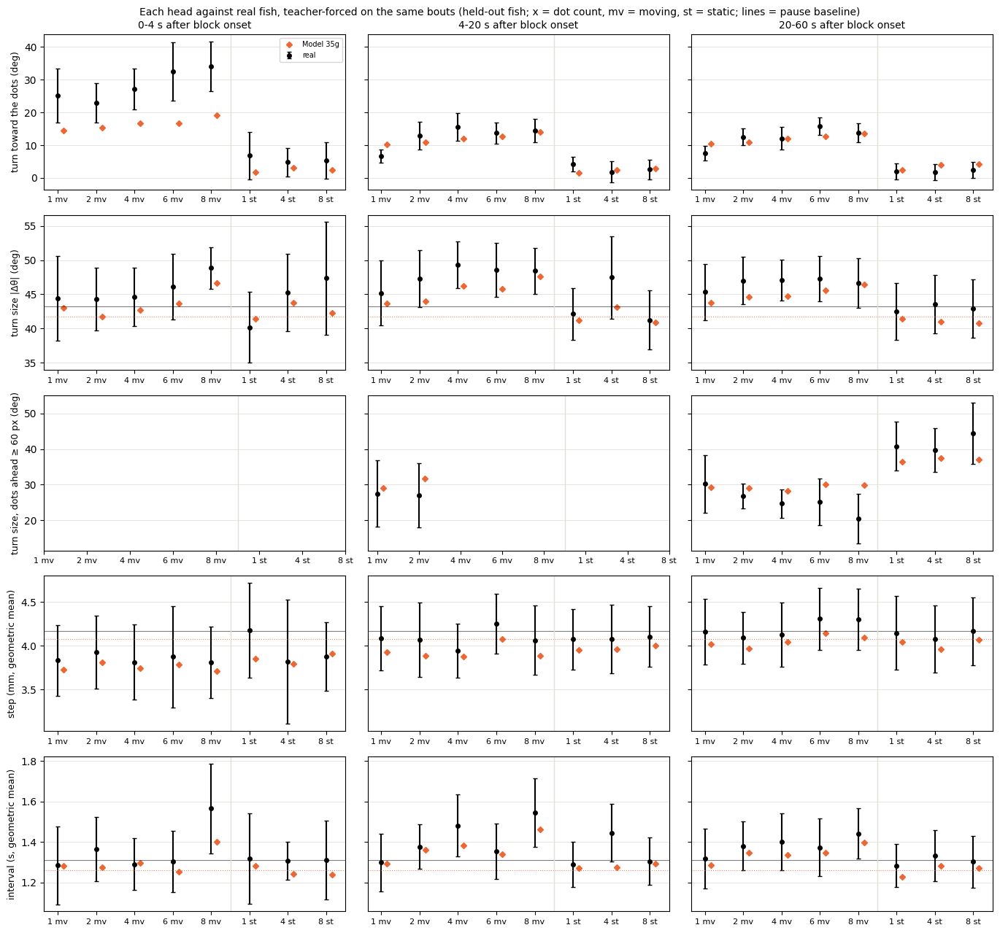

In [39]:
unit_eval.show('35g')

### M6-x3, seed 101


== held-out likelihood per head (bits per bout)
turn             7.647
displacement     4.502
interval         1.227
joint           13.376

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al.csv  (15 rows) in 1455s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_rej
abs_dtheta_w1                                8.5974
symbol_js                                    0.0131
dt_w1                                        0.3922
dist_w

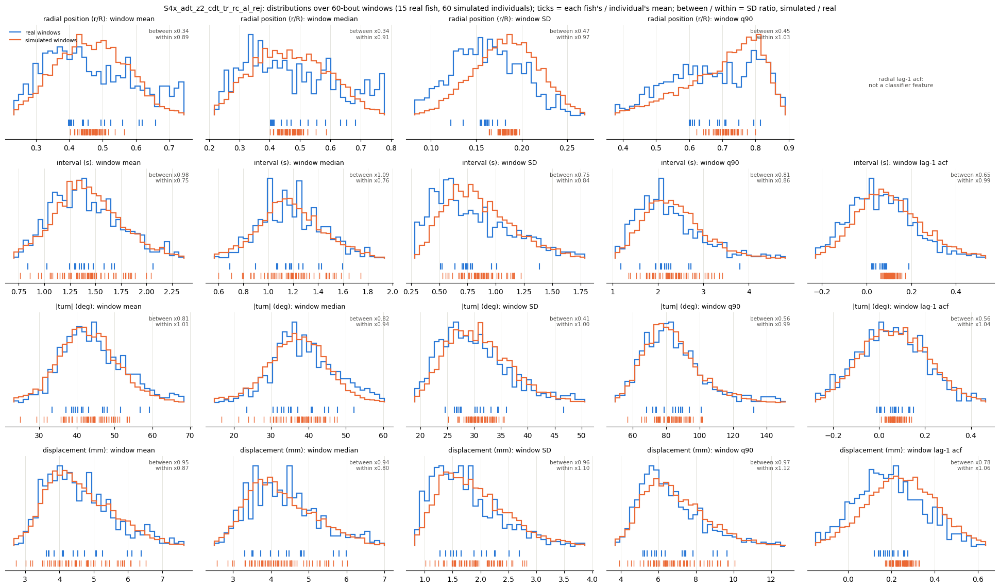


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_fold4.pt: 3 rollouts
dropped 12.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.03     1.38  0.15  0.94   3.0   5.0                  22.3 +/- 0.9  19.8 +/- 0.7
d2s3.5    1.58     1.30  2.64  2.05  11.0   9.0                  17.4 +/- 0.9  18.3 +/- 0.8
d4s3.5    1.37     0.81  4.68  3.01  19.0  13.0                  18.7 +/- 1.7  17.9 +/- 0.9
d6s3.5    1.50     1.05  4.62   3.0  13.0  19.0                  16.7 +/- 1.3  17.3 +/- 0.7
d8s3.5    2.05     2.07  4.97  1.91  11.0   9.0                  16.3 +/- 1.0  17.7 +/- 0.8
d1s0      1.54   

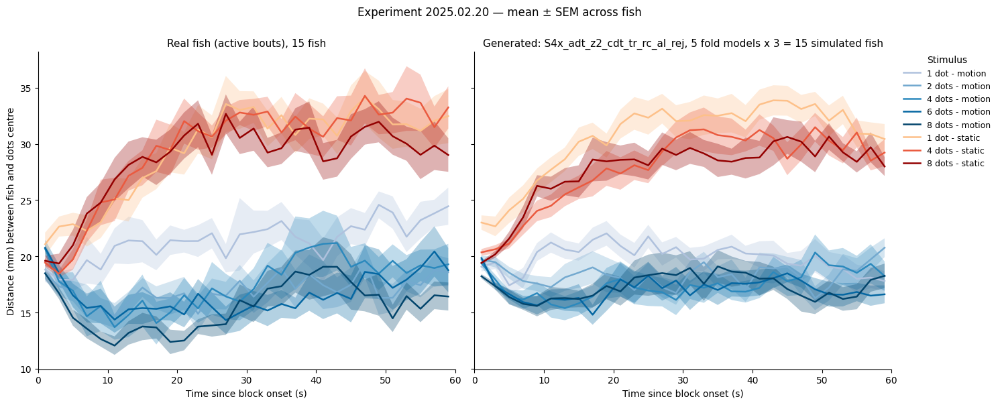


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

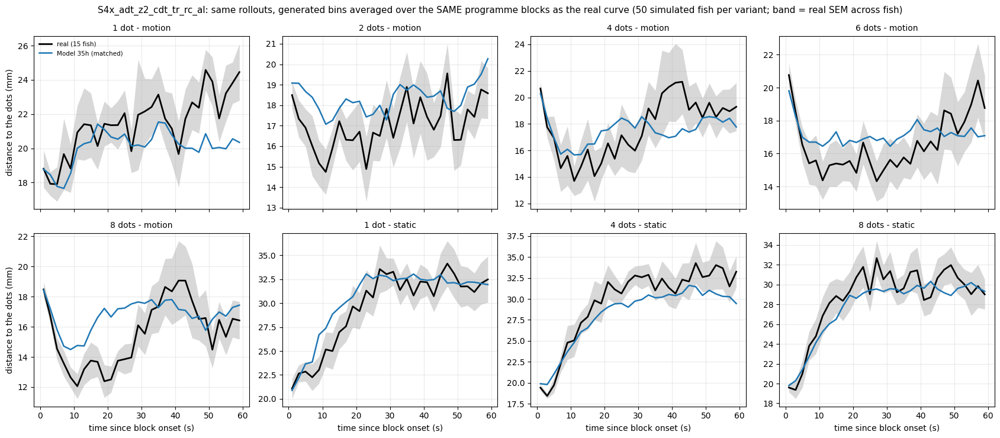


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al                  
           plateau   null attraction                 plateau   null attraction
cond_label                                                                    
d1s3.5       22.41  23.57       1.16                   20.59  22.67       2.08
d2s3.5       17.39  23.58       6.19                   18.77  22.61       3.85
d4s3.5       18.74  23.93       5.19                   18.05  22.43       4.37
d6s3.5       16.69  23.12       6.43                   17.46  22.57       5.12
d8s3.5       16.41  23.36       6.94                   17.58  22.79       5.21

== turn toward the moving dots by dot count
           real  S4x_adt_z2_cdt_tr_rc_al
win    N                                
0-20 s 1

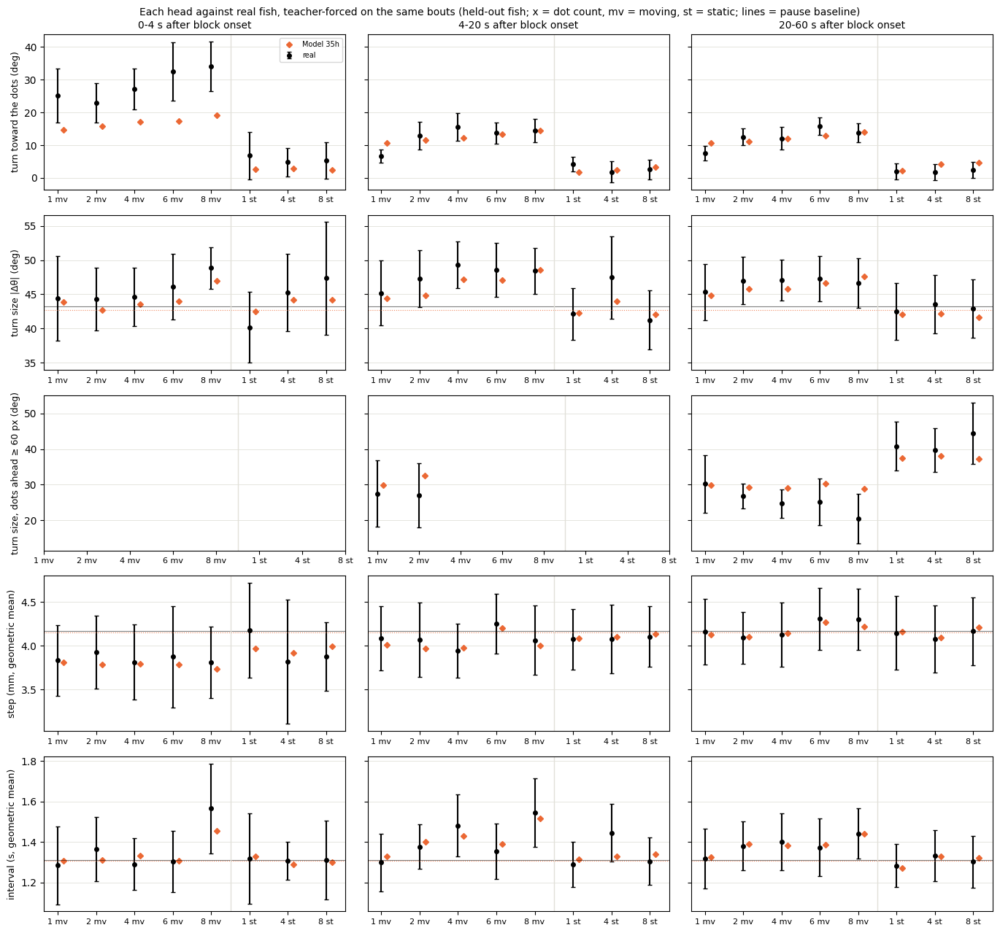

In [40]:
unit_eval.show('35h')

### M6-z, seed 0


== held-out likelihood per head (bits per bout)
turn             7.664
displacement     4.532
interval         1.415
joint           13.611

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4x_adt_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_cdt_tr_rc_al_w3ft.csv  (15 rows) in 809s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                  6.4009
symbol_js                                      0.0068
dt_w1                                        

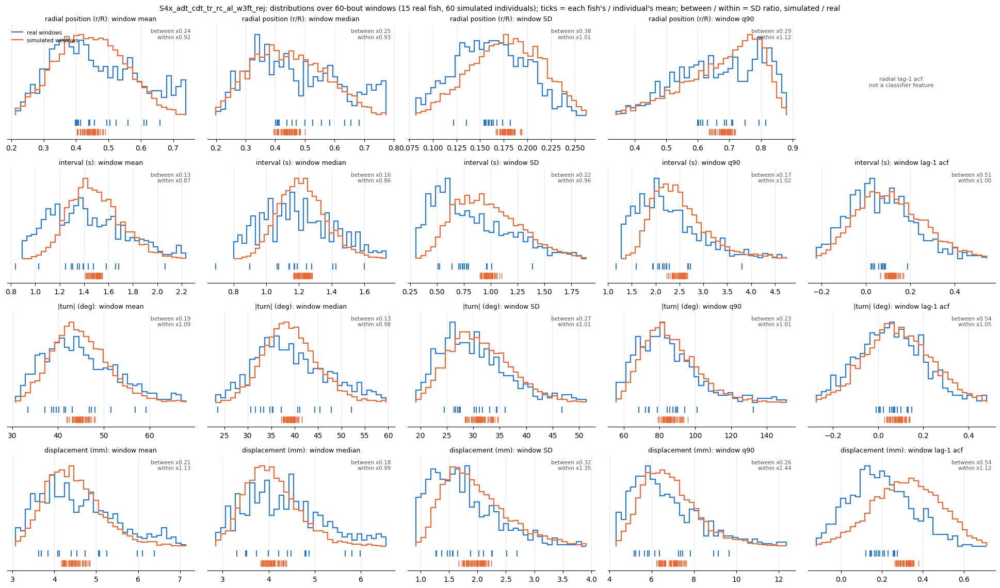


== distance to the dots across the block
  S4x_adt_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.64     1.09  0.15  0.89   3.0   7.0                  22.3 +/- 0.9  20.8 +/- 0.9
d2s3.5    1.31     1.01  2.64  2.63  11.0   9.0                  17.4 +/- 0.9  18.2 +/- 0.6
d4s3.5    1.07     0.65  4.68  4.08  19.0   9.0                  18.7 +/- 1.7  18.7 +/- 0.4
d6s3.5    0.85     0.64  4.62  3.07  13.0   9.0                  16.7 +/- 1.3  17.1 +/- 0.7
d8s3.5    1.50     1.42  4.97  2.85  11.0   7.0                  16.3 +/- 1.0  17.0 +/- 0.7
d1s0      1.69 

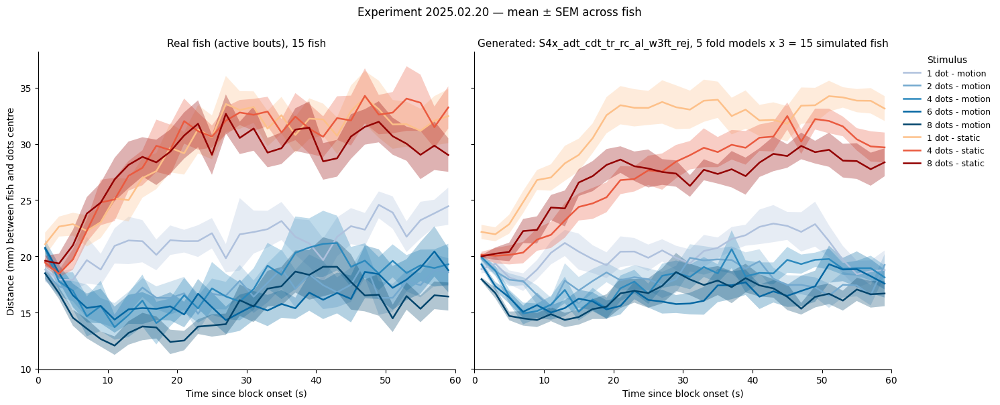


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

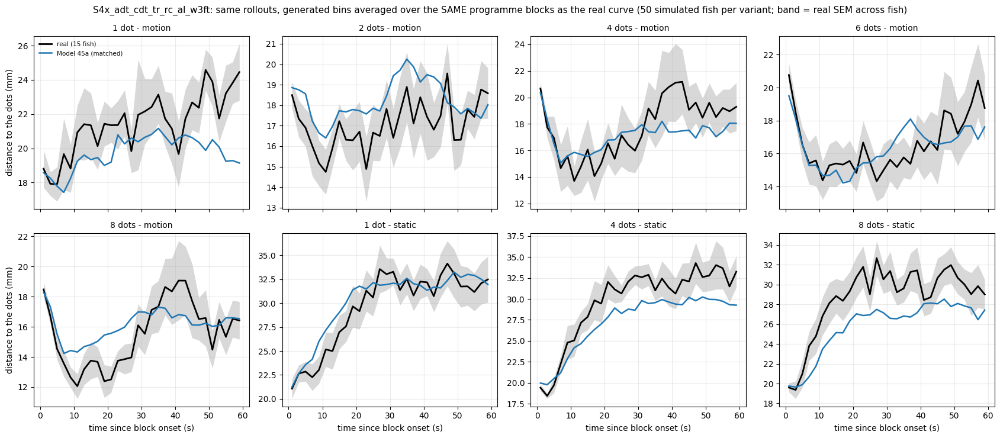


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                   plateau   null attraction
cond_label                                                                      
d1s3.5       22.41  23.57       1.16                     20.67  21.93       1.26
d2s3.5       17.39  23.58       6.19                     18.26  22.18       3.92
d4s3.5       18.74  23.93       5.19                     18.23  22.17       3.94
d6s3.5       16.69  23.12       6.43                     16.95  21.73       4.78
d8s3.5       16.41  23.36       6.94                     16.86  21.88       5.02

== turn toward the moving dots by dot count
           real  S4x_adt_cdt_tr_rc_al_w3ft
win    N                       

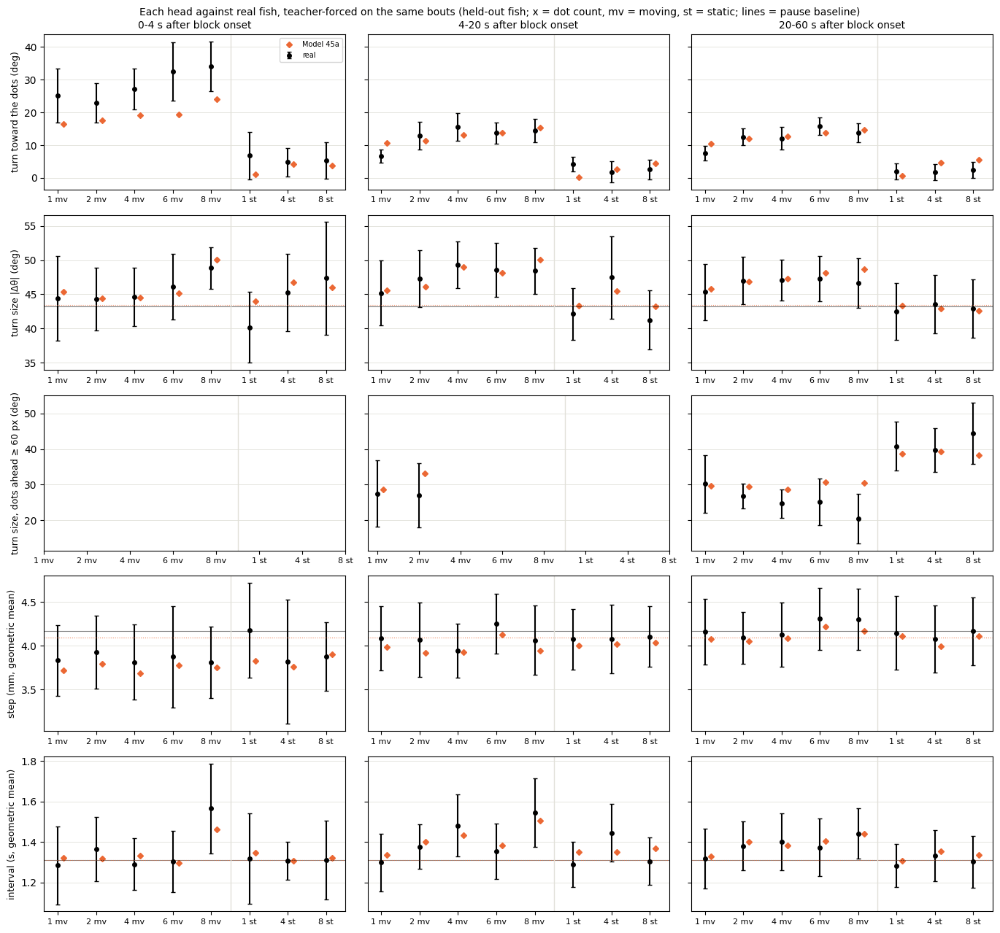

In [41]:
unit_eval.show('45a')

### M6-z, seed 101


== held-out likelihood per head (bits per bout)


turn             7.667
displacement     4.539
interval         1.448
joint           13.654

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4x_adt_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_cdt_tr_rc_al_w3ft.csv  (15 rows) in 496s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                  6.8805
symbol_js                                      0.0074
dt_w1                                          0.2401
dist_w1                                

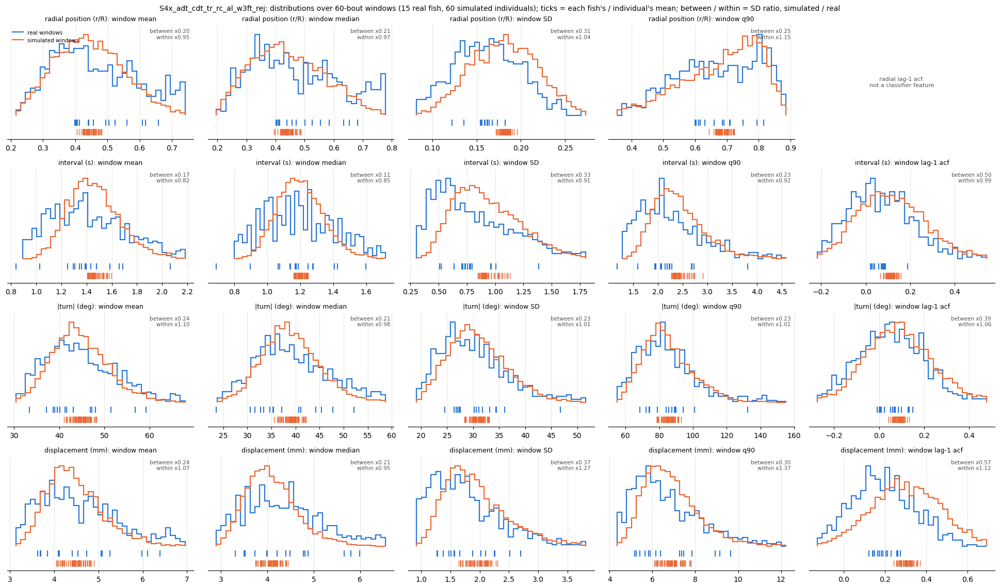


== distance to the dots across the block
  S4x_adt_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.78     1.27  0.15  1.02   3.0   5.0                  22.3 +/- 0.9  21.1 +/- 0.9
d2s3.5    1.95     1.51  2.64  2.92  11.0  17.0                  17.4 +/- 0.9  18.9 +/- 0.6
d4s3.5    1.35     0.81  4.68  4.63  19.0   7.0                  18.7 +/- 1.7  17.8 +/- 0.6
d6s3.5    1.31     0.93  4.62  3.65  13.0  11.0                  16.7 +/- 1.3  17.2 +/- 0.8
d8s3.5    1.90     1.69  4.97  2.78  11.0   9.0                  16.3 +/- 1.0  16.4 +/- 0.6
d1s0      2.72 

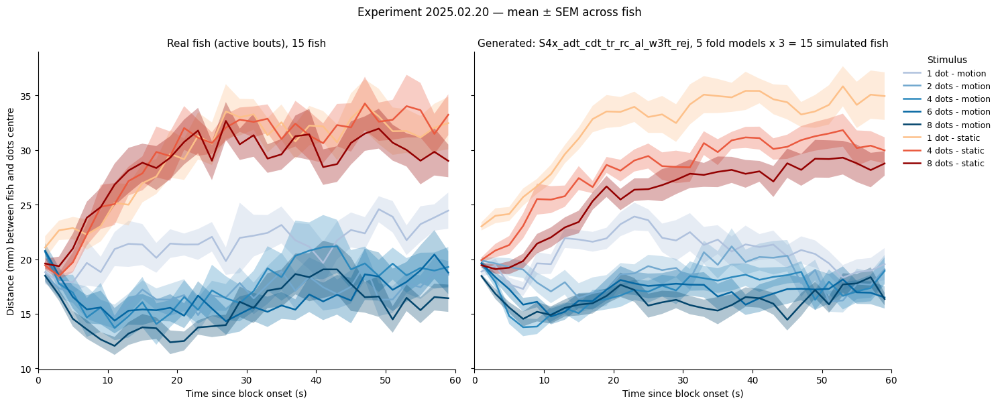


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

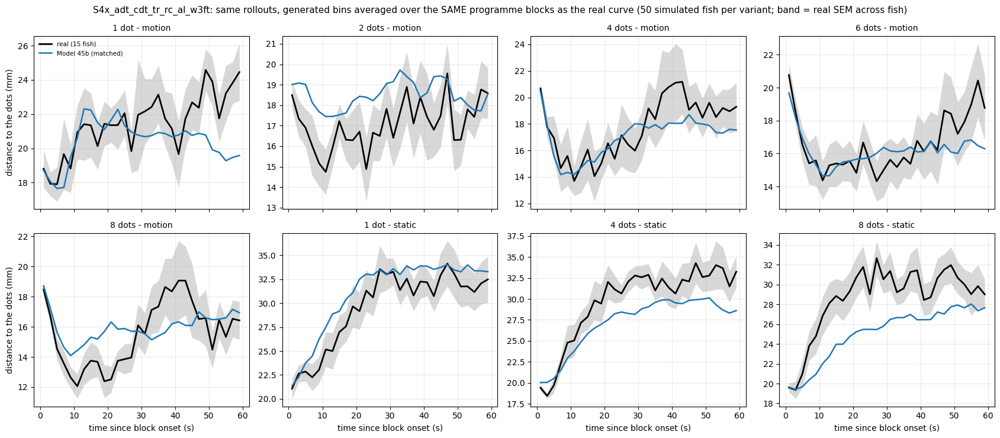


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                   plateau   null attraction
cond_label                                                                      
d1s3.5       22.41  23.57       1.16                     21.12  22.01       0.89
d2s3.5       17.39  23.58       6.19                     18.51  21.79       3.28
d4s3.5       18.74  23.93       5.19                     18.36  22.10       3.73
d6s3.5       16.69  23.12       6.43                     16.96  21.99       5.03
d8s3.5       16.41  23.36       6.94                     16.91  21.95       5.03

== turn toward the moving dots by dot count
           real  S4x_adt_cdt_tr_rc_al_w3ft
win    N                       

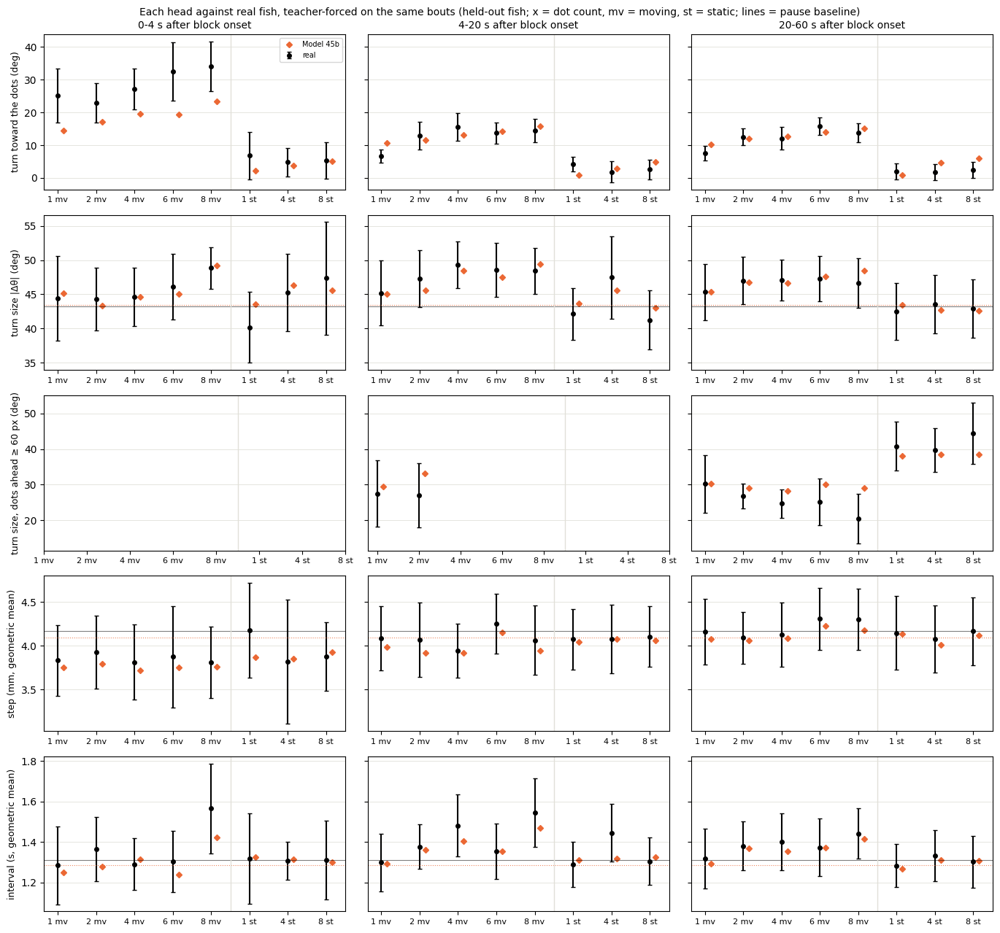

In [42]:
unit_eval.show('45b')